
# 🤖 NewsBot Intelligence System
### Automated News Classification, Language Analysis, and Business Intelligence

**Course:** ITAI 2373 - Natural Language Processing  
**Project:** Midterm Group Project  
**Team Members:** Raymond Newton
**Submission Date:** 2026 October 19
**GitHub Repository:** [Add repository URL]

---

## Project Overview

NewsBot Intelligence System is a natural language processing application designed to transform unstructured news content into organized, searchable, and actionable information.

The system combines text preprocessing, feature extraction, linguistic analysis, sentiment analysis, machine learning classification, and named entity recognition to examine news coverage across multiple categories.

The objective is not simply to classify articles, but to demonstrate how different NLP techniques can work together within a practical information analysis system.

## Core System Capabilities

- **News Classification:** Automatically organize news content into six categories: Politics, Finance, Entertainment, Sports, Wellness, and Technology.
- **Text Preprocessing:** Clean and normalize text for consistent NLP analysis.
- **Feature Extraction:** Use TF-IDF to identify informative words and represent text numerically.
- **Linguistic Analysis:** Examine part-of-speech patterns, grammatical relationships, and sentence structure.
- **Sentiment Analysis:** Evaluate positive, negative, and neutral language in news coverage.
- **Named Entity Recognition:** Identify people, organizations, locations, dates, and other important entities.
- **Business Intelligence:** Explore patterns that can support media monitoring, research, and informed decision-making.

## Dataset and Research Scope

**Dataset:** HuffPost News Category Dataset  
**Dataset Author:** Rishabh Misra  
**Source:** https://www.kaggle.com/datasets/rmisra/news-category-dataset

NewsBot uses a reproducible sample of 2,000 records selected from the publicly available HuffPost dataset.

The original dataset contains news headlines and short descriptions rather than complete article bodies. The system's findings will therefore be evaluated within the limitations of this source material.

### NewsBot Classification Categories

| NewsBot Category | Original HuffPost Category |
|---|---|
| Politics | POLITICS |
| Finance | BUSINESS + MONEY |
| Entertainment | ENTERTAINMENT |
| Sports | SPORTS |
| Wellness | WELLNESS |
| Technology | TECH |

The original Business and Money categories are combined into Finance to support broader financial-news classification. Their original labels will be retained for analysis and comparison.

## NLP Module Integration

- [ ] Module 1: NLP applications and real-world context
- [ ] Module 2: Text preprocessing
- [ ] Module 3: TF-IDF feature extraction
- [ ] Module 4: Part-of-speech tagging
- [ ] Module 5: Syntax parsing and semantic analysis
- [ ] Module 6: Sentiment and emotion analysis
- [ ] Module 7: Text classification
- [ ] Module 8: Named entity recognition

## Reproducibility and Implementation

NewsBot is developed in Python using Google Colab.

The project aims to support reproducible execution through automatic dataset retrieval, documented dependencies, consistent random sampling, and transparent model evaluation.

Results, limitations, and opportunities for future improvement will be documented throughout the notebook.

---

**Project Status:** Development and validation in progress.



## 📦 Reproducible Environment Setup

### NewsBot Intelligence System | ITAI 2373

NewsBot is developed in Python using Google Colab. The notebook is organized into sequential stages so that another user can reproduce our dataset preparation, NLP analysis, model training, and evaluation.

### 1. System Requirements

- Google Colab with a Python 3 runtime
- Internet connection for downloading dependencies and the dataset
- Access to Google Colab's standard CPU runtime
- No paid services or GPU required for the planned core analysis

### 2. Getting Started

1. Open this notebook in Google Colab.
2. Select **Runtime → Run all**, or execute each code cell in order.
3. Allow the environment setup cell to install the necessary libraries and language resources.
4. Allow the dataset-loading cell to retrieve the HuffPost News Category Dataset.
5. Review the dataset validation results before proceeding to NLP analysis.
6. Continue through preprocessing, feature extraction, linguistic analysis, classification, and evaluation.

### 3. Required Libraries and Tools

NewsBot uses the following Python libraries:

| Library | Purpose |
|---|---|
| pandas | Dataset loading, cleaning, and manipulation |
| NumPy | Numerical operations and data handling |
| NLTK | Tokenization, linguistic resources, and sentiment analysis |
| spaCy | POS tagging, dependency parsing, and named entity recognition |
| scikit-learn | TF-IDF, machine learning, and model evaluation |
| Matplotlib / Seaborn | Statistical visualizations |
| Plotly | Interactive data visualizations |
| WordCloud | Visual representation of important terms |
| kagglehub | Automatic retrieval of the public dataset |

Dependencies and NLP language resources are installed in the next code cell.

### 4. Dataset Access

**Dataset:** News Category Dataset  
**Author:** Rishabh Misra  
**Source:** https://www.kaggle.com/datasets/rmisra/news-category-dataset

NewsBot is designed to retrieve the publicly available HuffPost dataset automatically using `kagglehub`.

A personal Kaggle API key is not expected to be necessary for normal public dataset access.

If automatic retrieval fails because of network restrictions, authentication requirements, or changes to the source, the notebook will provide a manual upload option.

The fallback accepts the original ZIP archive or its extracted JSON file.

**Important:** The source dataset contains news headlines and short descriptions rather than complete article bodies. This limitation will be considered when evaluating the system's results.

### 5. Dataset Sampling and Reproducibility

To stay within the assignment requirements and maintain manageable processing times, NewsBot will use 2,000 records across six categories:

- Politics: 333
- Finance: 334
- Entertainment: 333
- Sports: 333
- Wellness: 333
- Technology: 334

The Finance category combines the original `BUSINESS` and `MONEY` labels, selecting 167 records from each.

To support reproducibility, the project uses:

- A fixed random seed of `42`
- Explicit category mappings
- Consistent data-cleaning rules
- Duplicate-record filtering
- Preserved original category labels
- Dataset size and quality validation
- Documented model evaluation procedures

The prepared dataset will be saved as `newsbot_dataset.csv` within the Colab runtime.

### 6. Privacy, Security, and Responsible Use

NewsBot does not require users to provide personal information to run the core analysis.

API credentials and private authentication tokens should never be included directly in notebook code or committed to a public GitHub repository.

The dataset's original source will be credited, and model predictions will be treated as automated estimates rather than verified conclusions.

### 7. Execution and Validation

The project is intended to be executable from a fresh Colab runtime. Reproducibility will be confirmed by testing the complete notebook after development.

Expected outputs include:

- A validated 2,000-record dataset
- Text preprocessing results
- TF-IDF feature representations
- POS tagging and dependency parsing results
- Sentiment analysis
- Classification model comparisons and evaluation metrics
- Named entity recognition results
- Summary visualizations and business intelligence findings

Any execution errors, limitations, or required manual steps will be documented.

---

### Optional extra-credit interface
Gradio is included among the automatically installed packages. The Gradio app is constructed during `Run all`, but launching its server is opt-in using `LAUNCH_NEWSBOT_UI = True` near the end.


In [2]:
# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 3 - ENVIRONMENT SETUP AND DEPENDENCY INSTALLATION
# ITAI 2373 Natural Language Processing
# ============================================================

# STEP 1: Install required Python libraries
# %pip installs packages in the active Colab environment.

%pip install -q \
    pandas \
    numpy \
    nltk \
    spacy \
    scikit-learn \
    matplotlib \
    seaborn \
    wordcloud \
    plotly \
    kagglehub \
    "gradio>=5,<7"

print("✅ Python dependencies installed.")

# ------------------------------------------------------------
# STEP 2: Install the spaCy English language model
# Used for POS tagging, dependency parsing, and NER.
# ------------------------------------------------------------

!python -m spacy download en_core_web_sm

print("✅ spaCy English language model installed.")

# ------------------------------------------------------------
# STEP 3: Download required NLTK resources
# ------------------------------------------------------------

import nltk

nltk_resources = [
    "punkt",
    "punkt_tab",
    "stopwords",
    "wordnet",
    "omw-1.4",
    "vader_lexicon",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng"
]

for resource in nltk_resources:
    success = nltk.download(resource, quiet=True)

    if not success:
        raise RuntimeError(
            f"Unable to download NLTK resource: {resource}"
        )

    print(f"✅ NLTK resource ready: {resource}")

# ------------------------------------------------------------
# STEP 4: Confirm environment setup
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("NEWSBOT ENVIRONMENT SETUP")
print("=" * 55)

print("✅ Required Python packages installed")
print("✅ spaCy English model installed")
print("✅ NLTK resources downloaded")
print("✅ KaggleHub available for dataset retrieval")

print("\nEnvironment setup completed.")

✅ Python dependencies installed.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ spaCy English language model installed.
✅ NLTK resource ready: punkt
✅ NLTK resource ready: punkt_tab
✅ NLTK resource ready: stopwords
✅ NLTK resource ready: wordnet
✅ NLTK resource ready: omw-1.4
✅ NLTK resource ready: vader_lexicon
✅ NLTK resource ready: averaged_perceptron_tagger
✅ NLTK resource ready: averaged_perceptron_tagger_eng

NEWSBOT ENVIRONMENT SETUP
✅ Required Python packages installed
✅ spaCy English model installed
✅ NLTK resources downloaded
✅ KaggleHub available for dataset retrieval

Environment setup completed.


In [3]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 4 - LIBRARY IMPORTS AND ENVIRONMENT INITIALIZATION
# ITAI 2373 Natural Language Processing
# ============================================================

# ------------------------------------------------------------
# DATA PROCESSING AND UTILITIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import re

from collections import Counter, defaultdict

# ------------------------------------------------------------
# DATA VISUALIZATION
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

import plotly.express as px
import plotly.graph_objects as go

# ------------------------------------------------------------
# NATURAL LANGUAGE PROCESSING
# ------------------------------------------------------------

import nltk
import spacy

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# ------------------------------------------------------------
# TEXT REPRESENTATION AND MACHINE LEARNING
# ------------------------------------------------------------

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    CountVectorizer
)

from sklearn.model_selection import (
    train_test_split,
    cross_val_score
)

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.pipeline import Pipeline

# ------------------------------------------------------------
# LOAD SPACY ENGLISH LANGUAGE MODEL
# ------------------------------------------------------------

try:
    nlp = spacy.load("en_core_web_sm")

except OSError as error:
    raise RuntimeError(
        "The spaCy English model is unavailable. "
        "Run Cell 3 to install en_core_web_sm."
    ) from error

# ------------------------------------------------------------
# REPRODUCIBILITY SETTINGS
# ------------------------------------------------------------

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ------------------------------------------------------------
# VISUALIZATION SETTINGS
# ------------------------------------------------------------

plt.style.use("default")
sns.set_palette("husl")

# ------------------------------------------------------------
# ENVIRONMENT VALIDATION
# ------------------------------------------------------------

print("=" * 55)
print("NEWSBOT ENVIRONMENT VALIDATION")
print("=" * 55)

print(f"Python data processing: pandas {pd.__version__}")
print(f"Numerical computing: NumPy {np.__version__}")
print(f"NLP framework: spaCy {spacy.__version__}")
print(f"NLTK version: {nltk.__version__}")
print(f"spaCy language model: {nlp.meta['name']}")
print(f"Language model version: {nlp.meta['version']}")
print(f"Random seed: {RANDOM_SEED}")

print("\nAll required libraries imported successfully.")


NEWSBOT ENVIRONMENT VALIDATION
Python data processing: pandas 2.2.3
Numerical computing: NumPy 2.1.3
NLP framework: spaCy 3.8.16
NLTK version: 3.9.1
spaCy language model: core_web_sm
Language model version: 3.8.0
Random seed: 42

All required libraries imported successfully.


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [4]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 6 - DATASET ACQUISITION AND PREPARATION
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - pandas (pd) and NumPy (np) imported in Cell 4
# - kagglehub installed in Cell 3

from pathlib import Path
import zipfile
import kagglehub

# ------------------------------------------------------------
# 1. DATASET CONFIGURATION
# ------------------------------------------------------------

DATASET_HANDLE = "rmisra/news-category-dataset"
RANDOM_SEED = 42
TARGET_SAMPLE_SIZE = 2000

# Map original HuffPost labels to NewsBot categories.
CATEGORY_MAPPING = {
    "POLITICS": "Politics",
    "BUSINESS": "Finance",
    "MONEY": "Finance",
    "ENTERTAINMENT": "Entertainment",
    "SPORTS": "Sports",
    "WELLNESS": "Wellness",
    "TECH": "Technology"
}

# Stratified sample from the original categories.
# Finance contains equal numbers of Business and Money.
SAMPLE_PLAN = {
    "POLITICS": 333,
    "BUSINESS": 167,
    "MONEY": 167,
    "ENTERTAINMENT": 333,
    "SPORTS": 333,
    "WELLNESS": 333,
    "TECH": 334
}

assert sum(SAMPLE_PLAN.values()) == TARGET_SAMPLE_SIZE

# ------------------------------------------------------------
# 2. AUTOMATIC DATASET RETRIEVAL
# ------------------------------------------------------------

print("=" * 60)
print("NEWSBOT DATASET ACQUISITION")
print("=" * 60)

print("\nRetrieving the HuffPost News Category Dataset...")

try:
    dataset_path = Path(
        kagglehub.dataset_download(DATASET_HANDLE)
    )

    # Locate the source JSON file.
    json_files = list(
        dataset_path.rglob("News_Category_Dataset_v3.json")
    )

    if not json_files:
        json_files = list(dataset_path.rglob("*.json"))

    if not json_files:
        raise FileNotFoundError(
            "The downloaded dataset does not contain a JSON file."
        )

    dataset_file = json_files[0]

    print("Dataset retrieved successfully.")
    print(f"Source file: {dataset_file.name}")

    raw_df = pd.read_json(
        dataset_file,
        lines=True
    )

    acquisition_method = "KaggleHub automatic download"

except Exception as error:

    print("\nAutomatic retrieval was unsuccessful.")
    print(f"Reason: {error}")

    print("\nManual fallback:")
    print("Upload the original HuffPost ZIP or extracted JSON.")

    from google.colab import files

    uploaded = files.upload()

    valid_files = [
        filename for filename in uploaded
        if filename.lower().endswith((".zip", ".json"))
    ]

    if not valid_files:
        raise ValueError(
            "No valid HuffPost ZIP or JSON file was uploaded."
        )

    uploaded_file = Path(valid_files[0])

    if uploaded_file.suffix.lower() == ".zip":

        with zipfile.ZipFile(uploaded_file, "r") as archive:

            json_members = [
                name for name in archive.namelist()
                if name.lower().endswith(".json")
            ]

            if not json_members:
                raise ValueError(
                    "The uploaded ZIP contains no JSON file."
                )

            with archive.open(json_members[0]) as file:
                raw_df = pd.read_json(file, lines=True)

    else:
        raw_df = pd.read_json(
            uploaded_file,
            lines=True
        )

    acquisition_method = "Manual upload fallback"

print("\nSource dataset loaded.")
print(f"Original records: {len(raw_df):,}")
print(f"Original columns: {raw_df.columns.tolist()}")

# ------------------------------------------------------------
# 3. VERIFY REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = {
    "headline",
    "short_description",
    "category",
    "date",
    "link"
}

missing_columns = (
    required_columns - set(raw_df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing dataset columns: {sorted(missing_columns)}"
    )

# ------------------------------------------------------------
# 4. FILTER AND STANDARDIZE CATEGORIES
# ------------------------------------------------------------

df = raw_df[
    raw_df["category"].isin(CATEGORY_MAPPING)
].copy()

# Preserve original HuffPost labels.
df["original_category"] = df["category"]

# Create standardized NewsBot labels.
df["category"] = df["original_category"].map(
    CATEGORY_MAPPING
)

# Standardize article fields.
df["title"] = (
    df["headline"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["content"] = (
    df["short_description"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df["source"] = "HuffPost"

# Combined headline and description word count.
df["word_count"] = (
    df["title"] + " " + df["content"]
).str.split().str.len()

# ------------------------------------------------------------
# 5. DATA QUALITY FILTERING
# ------------------------------------------------------------

records_before_cleaning = len(df)

# Remove missing titles, descriptions, dates,
# and records containing fewer than 15 total words.
df = df[
    (df["title"] != "") &
    (df["content"] != "") &
    (df["date"].notna()) &
    (df["word_count"] >= 15)
].copy()

# Remove exact duplicate headline-description pairs.
df = df.drop_duplicates(
    subset=["title", "content"]
).copy()

records_after_cleaning = len(df)

print("\n" + "=" * 60)
print("DATA QUALITY VALIDATION")
print("=" * 60)

print(f"Selected source records: {records_before_cleaning:,}")
print(f"Eligible records after cleaning: {records_after_cleaning:,}")

print("\nAvailable records by original category:")
print(
    df["original_category"]
    .value_counts()
    .reindex(SAMPLE_PLAN.keys())
)

# ------------------------------------------------------------
# 6. STRATIFIED SAMPLING
# ------------------------------------------------------------

samples = []

for original_label, sample_count in SAMPLE_PLAN.items():

    category_data = df[
        df["original_category"] == original_label
    ]

    available = len(category_data)

    if available < sample_count:
        raise ValueError(
            f"Not enough records in {original_label}. "
            f"Required: {sample_count}; Available: {available}"
        )

    selected = category_data.sample(
        n=sample_count,
        random_state=RANDOM_SEED
    )

    samples.append(selected)

# Combine samples.
df = pd.concat(
    samples,
    ignore_index=True
)

# Shuffle while keeping results reproducible.
df = df.sample(
    frac=1,
    random_state=RANDOM_SEED
).reset_index(drop=True)

# Assign unique article IDs.
df["article_id"] = np.arange(
    1,
    len(df) + 1
)

# ------------------------------------------------------------
# 7. PREPARE FINAL NEWSBOT DATAFRAME
# ------------------------------------------------------------

df = df[
    [
        "article_id",
        "title",
        "content",
        "category",
        "original_category",
        "date",
        "source",
        "word_count",
        "link"
    ]
].copy()

# ------------------------------------------------------------
# 8. FINAL DATASET VALIDATION
# ------------------------------------------------------------

assert len(df) == TARGET_SAMPLE_SIZE, (
    "Incorrect dataset size."
)

assert df["category"].nunique() == 6, (
    "Expected exactly six NewsBot categories."
)

assert df["title"].str.strip().ne("").all()
assert df["content"].str.strip().ne("").all()

assert not df.duplicated(
    subset=["title", "content"]
).any(), "Duplicate records detected."

expected_finance = {
    "BUSINESS": 167,
    "MONEY": 167
}

actual_finance = (
    df.loc[
        df["category"] == "Finance",
        "original_category"
    ]
    .value_counts()
    .to_dict()
)

assert actual_finance == expected_finance, (
    "Finance sampling does not match the design."
)

# ------------------------------------------------------------
# 9. SAVE PREPARED DATASET
# ------------------------------------------------------------

OUTPUT_FILE = "newsbot_dataset.csv"

df.to_csv(
    OUTPUT_FILE,
    index=False
)

# ------------------------------------------------------------
# 10. DATASET SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NEWSBOT DATASET SUMMARY")
print("=" * 60)

print(f"Acquisition method: {acquisition_method}")
print(f"Total articles: {len(df):,}")
print(f"Classification categories: {df['category'].nunique()}")
print(f"Random seed: {RANDOM_SEED}")

print("\nCATEGORY DISTRIBUTION:")
print(
    df["category"]
    .value_counts()
    .sort_index()
)

print("\nFINANCE ORIGINAL LABELS:")
print(
    df.loc[
        df["category"] == "Finance",
        "original_category"
    ].value_counts()
)

print("\nCONTENT STATISTICS:")
print(f"Average word count: {df['word_count'].mean():.1f}")
print(f"Minimum word count: {df['word_count'].min()}")
print(f"Maximum word count: {df['word_count'].max()}")

print("\nPUBLICATION DATE RANGE:")
print(f"Earliest: {df['date'].min().date()}")
print(f"Latest: {df['date'].max().date()}")

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nSAMPLE RECORDS:")
display(df.head(5))

print(f"\nValidated dataset saved to: {OUTPUT_FILE}")


NEWSBOT DATASET ACQUISITION

Retrieving the HuffPost News Category Dataset...
Using Colab cache for faster access to the 'news-category-dataset' dataset.
Dataset retrieved successfully.
Source file: News_Category_Dataset_v3.json

Source dataset loaded.
Original records: 209,527
Original columns: ['link', 'headline', 'category', 'short_description', 'authors', 'date']

DATA QUALITY VALIDATION
Selected source records: 85,838
Eligible records after cleaning: 75,222

Available records by original category:
original_category
POLITICS         31115
BUSINESS          5026
MONEY             1753
ENTERTAINMENT    13491
SPORTS            4028
WELLNESS         17928
TECH              1881
Name: count, dtype: int64

NEWSBOT DATASET SUMMARY
Acquisition method: KaggleHub automatic download
Total articles: 2,000
Classification categories: 6
Random seed: 42

CATEGORY DISTRIBUTION:
category
Entertainment    333
Finance          334
Politics         333
Sports           333
Technology       334
Wellness

,article_id,title,content,category,original_category,date,source,word_count,link
0,1,CrowdRise: More Fun Than Just Reading the News,CrowdRise is a fundraising site with a real se...,Technology,TECH,2012-06-30,HuffPost,52,https://www.huffingtonpost.com/entry/crowdrise...
1,2,Black Friday's Most Insane Moments Caught On T...,"Shouting, heckling, fights and arrests. This i...",Finance,BUSINESS,2012-11-23,HuffPost,31,https://www.huffingtonpost.com/entry/black-fri...
2,3,Tone From Head To Toe In Just 5 Moves,You will need: Free weights By Jessica Smith f...,Wellness,WELLNESS,2014-01-22,HuffPost,30,https://www.huffingtonpost.com/entry/toning-wo...
3,4,Behold Rose Leslie's Seriously Gorgeous Engage...,"Crafted out of the finest Valyrian steel, prob...",Entertainment,ENTERTAINMENT,2017-10-09,HuffPost,18,https://www.huffingtonpost.com/entry/behold-ro...
4,5,FIFA: Trump's Travel Ban Could Hurt U.S. Effor...,"Teams and fans ""need to have access to the cou...",Sports,SPORTS,2017-03-09,HuffPost,35,https://www.huffingtonpost.com/entry/fifa-worl...



Validated dataset saved to: newsbot_dataset.csv


NEWSBOT EXPLORATORY DATA ANALYSIS
Total records: 2,000
Total categories: 6
Data sources: 1

Categories:
['Entertainment', 'Finance', 'Politics', 'Sports', 'Technology', 'Wellness']

Publication date range:
2012-01-28 to 2022-09-14

Dataset dimensions:
2000 rows × 9 columns

CATEGORY DISTRIBUTION


,Articles,Percentage
category,,
Entertainment,333,16.65
Finance,334,16.70
Politics,333,16.65
Sports,333,16.65
Technology,334,16.70
Wellness,333,16.65


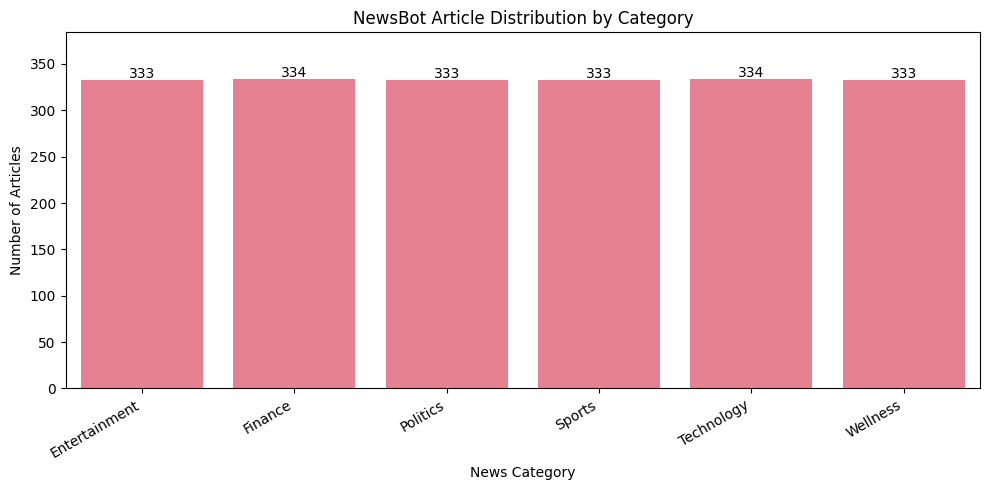


DATA QUALITY ASSESSMENT


,Missing Values,Missing Percentage
article_id,0,0.0
title,0,0.0
content,0,0.0
category,0,0.0
original_category,0,0.0
date,0,0.0
source,0,0.0
word_count,0,0.0
link,0,0.0



Duplicate headline-description pairs: 0
Missing titles: 0
Missing descriptions: 0

TEXT LENGTH ANALYSIS


,title_word_count,description_word_count,word_count
count,2000.00,2000.00,2000.00
mean,9.87,20.82,30.70
std,3.04,12.51,11.88
min,1.00,1.00,15.00
25%,8.00,12.00,23.00
50%,10.00,19.00,28.00
75%,12.00,24.00,35.00
max,26.00,164.00,166.00



Average text lengths:
Headline: 9.9 words
Description: 20.8 words
Combined: 30.7 words


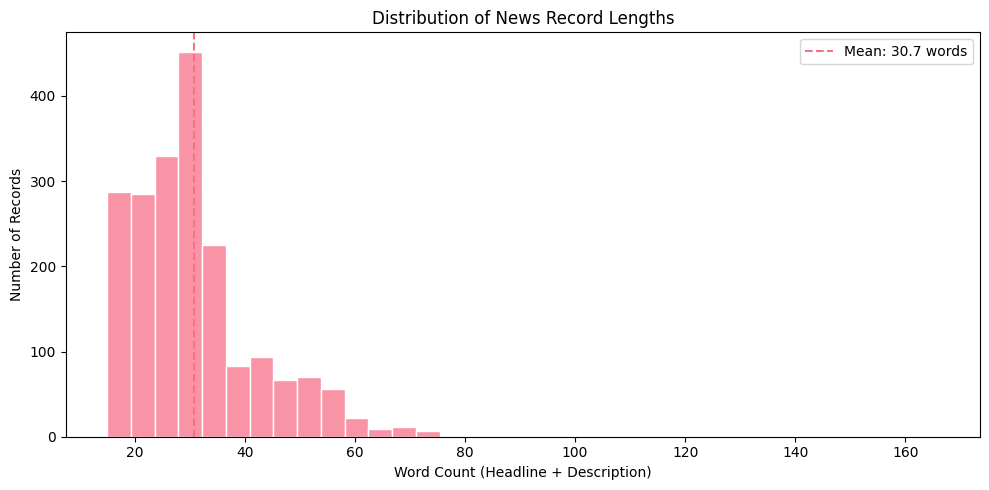


TEXT LENGTH BY CATEGORY


,count,mean,median,min,max
category,,,,,
Entertainment,333,25.86,24.0,15,74
Finance,334,34.76,32.0,15,119
Politics,333,29.22,27.0,15,166
Sports,333,27.30,25.0,15,73
Technology,334,28.93,28.0,15,65
Wellness,333,38.10,34.0,19,75


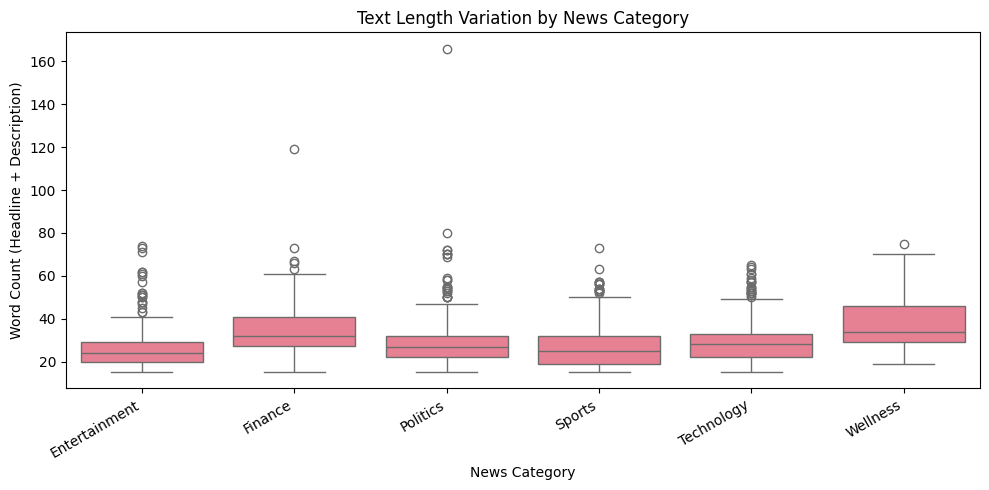


DATA SOURCE DISTRIBUTION


,Article Count
source,
HuffPost,2000



PUBLICATION YEAR DISTRIBUTION


,Article Count
publication_year,
2012,381
2013,294
2014,163
2015,330
2016,377
2017,254
2018,118
2019,19
2020,21


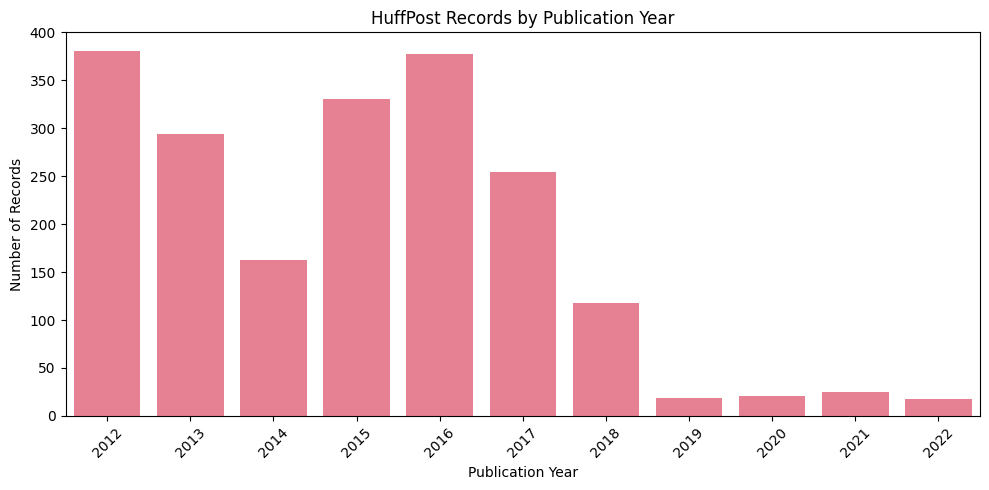


EXPLORATORY ANALYSIS FINDINGS
1. Dataset contains 2,000 records across 6 news categories.
2. Largest category: Finance (334 records).
3. Smallest category: Entertainment (333 records).
4. Average combined text length: 30.7 words.
5. Duplicate records detected: 0.
6. Total missing values: 0.
7. Publication years span 2012 to 2022.
8. Source coverage: HuffPost.

Data limitation:
Records contain headlines and short descriptions, rather than complete article bodies. Findings should be interpreted accordingly.


In [5]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 7 - EXPLORATORY DATA ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

# ------------------------------------------------------------
# 1. DATASET OVERVIEW
# ------------------------------------------------------------

print("=" * 60)
print("NEWSBOT EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print(f"Total records: {len(df):,}")
print(f"Total categories: {df['category'].nunique()}")
print(f"Data sources: {df['source'].nunique()}")

print("\nCategories:")
print(sorted(df["category"].unique()))

print("\nPublication date range:")
print(f"{df['date'].min().date()} to {df['date'].max().date()}")

print("\nDataset dimensions:")
print(f"{df.shape[0]} rows × {df.shape[1]} columns")

# ------------------------------------------------------------
# 2. CATEGORY DISTRIBUTION
# ------------------------------------------------------------

category_counts = (
    df["category"]
    .value_counts()
    .sort_index()
)

category_percentages = (
    category_counts / len(df) * 100
)

category_summary = pd.DataFrame({
    "Articles": category_counts,
    "Percentage": category_percentages.round(2)
})

print("\n" + "=" * 60)
print("CATEGORY DISTRIBUTION")
print("=" * 60)

display(category_summary)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

for i, count in enumerate(category_counts.values):
    ax.text(
        i,
        count + 2,
        str(count),
        ha="center",
        fontsize=10
    )

plt.title("NewsBot Article Distribution by Category")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.ylim(0, category_counts.max() * 1.15)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. MISSING VALUES AND DUPLICATE RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DATA QUALITY ASSESSMENT")
print("=" * 60)

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

duplicate_count = df.duplicated(
    subset=["title", "content"]
).sum()

print(f"\nDuplicate headline-description pairs: {duplicate_count}")
print(f"Missing titles: {(df['title'].str.strip() == '').sum()}")
print(f"Missing descriptions: {(df['content'].str.strip() == '').sum()}")

# ------------------------------------------------------------
# 4. TEXT LENGTH ANALYSIS
# ------------------------------------------------------------

# The dataset contains headlines and short descriptions,
# not full-length news article bodies.

df["title_word_count"] = (
    df["title"].str.split().str.len()
)

df["description_word_count"] = (
    df["content"].str.split().str.len()
)

print("\n" + "=" * 60)
print("TEXT LENGTH ANALYSIS")
print("=" * 60)

length_summary = df[
    [
        "title_word_count",
        "description_word_count",
        "word_count"
    ]
].describe().round(2)

display(length_summary)

print("\nAverage text lengths:")
print(f"Headline: {df['title_word_count'].mean():.1f} words")
print(f"Description: {df['description_word_count'].mean():.1f} words")
print(f"Combined: {df['word_count'].mean():.1f} words")

# Distribution of combined text lengths
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=35,
    edgecolor="white"
)

plt.axvline(
    df["word_count"].mean(),
    linestyle="--",
    label=f"Mean: {df['word_count'].mean():.1f} words"
)

plt.title("Distribution of News Record Lengths")
plt.xlabel("Word Count (Headline + Description)")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. TEXT LENGTH BY CATEGORY
# ------------------------------------------------------------

category_length_summary = (
    df.groupby("category")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_index()
)

print("\n" + "=" * 60)
print("TEXT LENGTH BY CATEGORY")
print("=" * 60)

display(category_length_summary)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="category",
    y="word_count",
    order=sorted(df["category"].unique())
)

plt.title("Text Length Variation by News Category")
plt.xlabel("News Category")
plt.ylabel("Word Count (Headline + Description)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. SOURCE DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DATA SOURCE DISTRIBUTION")
print("=" * 60)

source_summary = df["source"].value_counts()
display(source_summary.rename("Article Count").to_frame())

# This project currently uses only the HuffPost dataset.
# We therefore avoid a redundant source comparison chart.

# ------------------------------------------------------------
# 7. PUBLICATION YEAR ANALYSIS
# ------------------------------------------------------------

df["publication_year"] = df["date"].dt.year

year_counts = (
    df["publication_year"]
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 60)
print("PUBLICATION YEAR DISTRIBUTION")
print("=" * 60)

display(year_counts.rename("Article Count").to_frame())

plt.figure(figsize=(10, 5))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values
)

plt.title("HuffPost Records by Publication Year")
plt.xlabel("Publication Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. AUTOMATED EXPLORATORY FINDINGS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EXPLORATORY ANALYSIS FINDINGS")
print("=" * 60)

print(f"1. Dataset contains {len(df):,} records across "
      f"{df['category'].nunique()} news categories.")

print(f"2. Largest category: {category_counts.idxmax()} "
      f"({category_counts.max()} records).")

print(f"3. Smallest category: {category_counts.idxmin()} "
      f"({category_counts.min()} records).")

print(f"4. Average combined text length: "
      f"{df['word_count'].mean():.1f} words.")

print(f"5. Duplicate records detected: {duplicate_count}.")

print(f"6. Total missing values: "
      f"{df.isnull().sum().sum()}.")

print(f"7. Publication years span "
      f"{df['publication_year'].min()} to "
      f"{df['publication_year'].max()}.")

print(f"8. Source coverage: "
      f"{', '.join(df['source'].unique())}.")

print("\nData limitation:")
print(
    "Records contain headlines and short descriptions, "
    "rather than complete article bodies. "
    "Findings should be interpreted accordingly."
)


## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [6]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 9 - TEXT CLEANING AND PREPROCESSING
# ITAI 2373 Natural Language Processing
# ============================================================

import html

# ------------------------------------------------------------
# 1. INITIALIZE PREPROCESSING RESOURCES
# ------------------------------------------------------------

lemmatizer = WordNetLemmatizer()

# Preserve negation terms that can change sentence meaning.
NEGATION_WORDS = {"no", "nor", "not", "never"}

stop_words = set(stopwords.words("english"))
stop_words = stop_words - NEGATION_WORDS

# ------------------------------------------------------------
# 2. TEXT CLEANING
# ------------------------------------------------------------

def clean_text(text):
    """
    Prepare news text for statistical NLP analysis.

    Operations:
    - Handle missing input
    - Decode HTML entities
    - Remove HTML markup
    - Remove URLs and email addresses
    - Expand common negative contractions
    - Normalize lowercase text
    - Remove numbers and special characters
    - Normalize whitespace

    Original text remains available for NER and
    context-sensitive linguistic analysis.
    """

    if text is None or pd.isna(text):
        return ""

    text = html.unescape(str(text))

    # Remove script/style blocks and HTML tags.
    text = re.sub(
        r"<(script|style)\b[^>]*>.*?</\1>",
        " ",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    text = re.sub(r"<[^>]+>", " ", text)

    # Remove web addresses and email addresses.
    text = re.sub(
        r"\b(?:https?://|www\.)\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    # Normalize apostrophes and lowercase.
    text = text.replace("’", "'").lower()

    # Expand negative contractions before punctuation removal.
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\b(\w+)n't\b", r"\1 not", text)

    # Retain English alphabetic characters and spaces.
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove repeated whitespace.
    text = re.sub(r"\s+", " ", text).strip()

    return text

# ------------------------------------------------------------
# 3. COMPLETE PREPROCESSING PIPELINE
# ------------------------------------------------------------

def preprocess_text(
    text,
    remove_stopwords=True,
    lemmatize=True
):
    """
    Convert raw text into normalized tokens.

    Steps:
    1. Clean text
    2. Tokenize
    3. Optionally remove stop words
    4. Optionally lemmatize
    5. Remove short, low-information tokens

    Negation words are preserved.
    """

    cleaned_text = clean_text(text)

    if not cleaned_text:
        return ""

    # Tokenization
    tokens = word_tokenize(cleaned_text)

    # Optional stop word filtering
    if remove_stopwords:
        tokens = [
            token for token in tokens
            if token not in stop_words
        ]

    # Optional WordNet lemmatization
    if lemmatize:
        tokens = [
            lemmatizer.lemmatize(token)
            for token in tokens
        ]

    # Retain meaningful words and negations.
    tokens = [
        token for token in tokens
        if len(token) > 2 or token in NEGATION_WORDS
    ]

    return " ".join(tokens)

# ------------------------------------------------------------
# 4. PREPROCESSING VALIDATION EXAMPLES
# ------------------------------------------------------------

test_samples = {
    "Standard news text":
        "Apple Inc. announced record quarterly earnings today! "
        "Visit https://apple.com for more information.",

    "HTML and special characters":
        "<p>Breaking News: Markets rose 5% in 2022!</p>",

    "Negation and sentiment":
        "The company's results were not good, "
        "and investors weren't happy.",

    "Missing input":
        None
}

print("=" * 60)
print("NEWSBOT TEXT PREPROCESSING VALIDATION")
print("=" * 60)

for example_name, sample_text in test_samples.items():

    print(f"\nEXAMPLE: {example_name}")

    print(f"Original: {sample_text}")

    cleaned = clean_text(sample_text)
    processed = preprocess_text(sample_text)

    print(f"Cleaned: {cleaned}")
    print(f"Processed: {processed}")

# ------------------------------------------------------------
# 5. FUNCTION VALIDATION CHECKS
# ------------------------------------------------------------

assert clean_text(None) == ""

assert "https" not in clean_text(
    "Read https://example.com for updates."
)

assert "not" in preprocess_text(
    "The results were not good."
).split()

assert "not" in preprocess_text(
    "Investors weren't happy."
).split()

assert preprocess_text(
    "   "
) == ""

print("\n" + "=" * 60)
print("PREPROCESSING VALIDATION COMPLETE")
print("=" * 60)

print("Text cleaning: Passed")
print("Tokenization: Passed")
print("Negation preservation: Passed")
print("Missing input handling: Passed")


NEWSBOT TEXT PREPROCESSING VALIDATION

EXAMPLE: Standard news text
Original: Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more information.
Cleaned: apple inc announced record quarterly earnings today visit for more information
Processed: apple inc announced record quarterly earnings today visit information

EXAMPLE: HTML and special characters
Original: <p>Breaking News: Markets rose 5% in 2022!</p>
Cleaned: breaking news markets rose in
Processed: breaking news market rose

EXAMPLE: Negation and sentiment
Original: The company's results were not good, and investors weren't happy.
Cleaned: the company s results were not good and investors were not happy
Processed: company result not good investor not happy

EXAMPLE: Missing input
Original: None
Cleaned: 
Processed: 

PREPROCESSING VALIDATION COMPLETE
Text cleaning: Passed
Tokenization: Passed
Negation preservation: Passed
Missing input handling: Passed


NEWSBOT DATASET PREPROCESSING
Processing 2,000 news records...
Text cleaning and preprocessing completed.

TEXT LENGTH COMPARISON


,Text Stage,Average Words,Total Words
0,Original,30.70,61392
1,Cleaned,31.29,62587
2,Fully Preprocessed,18.38,36765



Token reduction after cleaning: 41.26%

VOCABULARY ANALYSIS


,Metric,Value
0,Unique Words - Cleaned,10223.00
1,Unique Words - Preprocessed,8901.00
2,Vocabulary Size Change (%),12.93



TOP 15 MOST COMMON PROCESSED WORDS


,Word,Frequency
0,not,517
1,new,197
2,trump,190
3,year,149
4,time,143
5,one,139
6,people,131
7,day,129
8,say,122
9,like,119


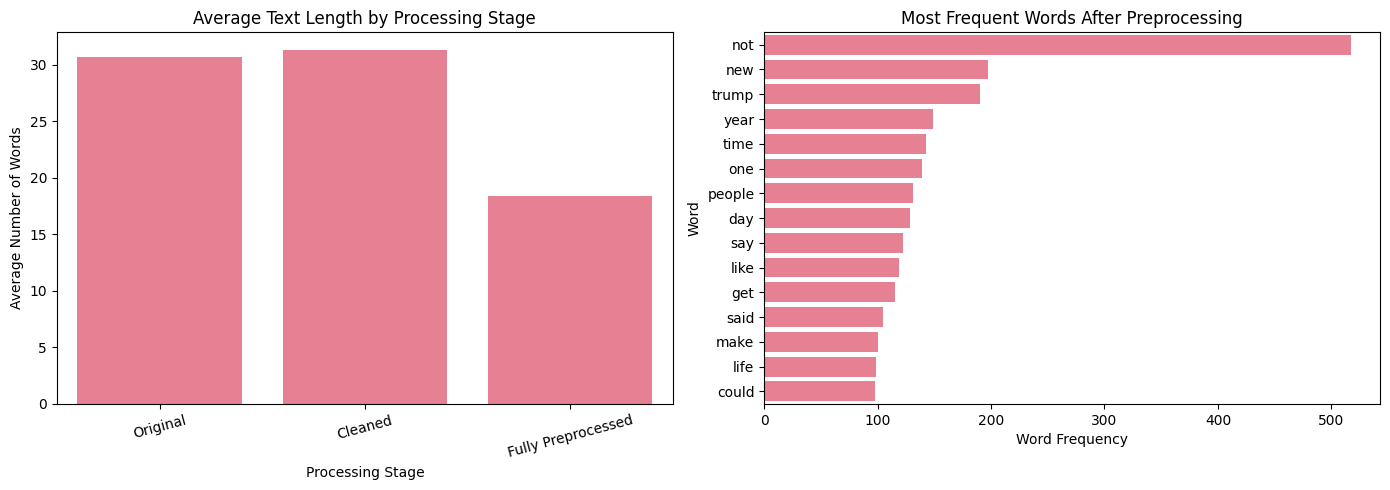


PREPROCESSING EXAMPLES

EXAMPLE 1
Category: Technology

Original:
CrowdRise: More Fun Than Just Reading the News CrowdRise is a fundraising site with a real sense of humor and humility, and the best part is that you can create your own project, get your own friends involved and do more than just read about the news: You can help fix it.

Cleaned:
crowdrise more fun than just reading the news crowdrise is a fundraising site with a real sense of humor and humility and the best part is that you can create your own project get your own friends involved and do more than just read about the news you can help fix it

Fully Preprocessed:
crowdrise fun reading news crowdrise fundraising site real sense humor humility best part create project get friend involved read news help fix
------------------------------------------------------------

EXAMPLE 2
Category: Finance

Original:
Black Friday's Most Insane Moments Caught On Tape (VIDEOS) Shouting, heckling, fights and arrests. This is just a sa

,Articles,Average_Original_Words,Average_Processed_Words,Token_Reduction_Percent
category,,,,
Entertainment,333,25.86,16.09,37.78
Finance,334,34.76,20.26,41.71
Politics,333,29.22,18.27,37.47
Sports,333,27.30,17.31,36.59
Technology,334,28.93,17.47,39.61
Wellness,333,38.10,20.89,45.17



PREPROCESSING VALIDATION
Total records processed: 2,000
Empty processed records: 0
Cleaned vocabulary size: 10,223
Processed vocabulary size: 8,901

PREPROCESSING VALIDATION COMPLETE
Processed dataset saved to: newsbot_preprocessed.csv


In [7]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 10 - DATASET PREPROCESSING AND ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df from Cell 6
# - clean_text() and preprocess_text() from Cell 9
# - pandas, NumPy, Matplotlib, Seaborn, Counter from Cell 4

print("=" * 60)
print("NEWSBOT DATASET PREPROCESSING")
print("=" * 60)

print(f"Processing {len(df):,} news records...")

# ------------------------------------------------------------
# 1. PRESERVE ORIGINAL TEXT
# ------------------------------------------------------------

# Headlines and descriptions are combined for text analysis.
# The original title and content columns remain unchanged.

df["full_text"] = (
    df["title"].fillna("") + " " +
    df["content"].fillna("")
).str.strip()

# ------------------------------------------------------------
# 2. APPLY TEXT CLEANING
# ------------------------------------------------------------

df["title_clean"] = df["title"].apply(clean_text)

df["content_clean"] = df["content"].apply(clean_text)

df["full_text_clean"] = df["full_text"].apply(clean_text)

# ------------------------------------------------------------
# 3. APPLY COMPLETE PREPROCESSING
# ------------------------------------------------------------

df["title_processed"] = (
    df["title"].apply(preprocess_text)
)

df["content_processed"] = (
    df["content"].apply(preprocess_text)
)

df["full_text_processed"] = (
    df["full_text"].apply(preprocess_text)
)

print("Text cleaning and preprocessing completed.")

# ------------------------------------------------------------
# 4. CALCULATE TEXT LENGTH STATISTICS
# ------------------------------------------------------------

# Original word counts were calculated during dataset loading.

df["clean_word_count"] = (
    df["full_text_clean"].str.split().str.len()
)

df["processed_word_count"] = (
    df["full_text_processed"].str.split().str.len()
)

# Measure token reduction from cleaned to processed text.

total_clean_words = df["clean_word_count"].sum()

total_processed_words = df["processed_word_count"].sum()

reduction_percentage = (
    (1 - total_processed_words / total_clean_words) * 100
    if total_clean_words > 0 else 0
)

length_comparison = pd.DataFrame({
    "Text Stage": [
        "Original",
        "Cleaned",
        "Fully Preprocessed"
    ],
    "Average Words": [
        df["word_count"].mean(),
        df["clean_word_count"].mean(),
        df["processed_word_count"].mean()
    ],
    "Total Words": [
        df["word_count"].sum(),
        total_clean_words,
        total_processed_words
    ]
})

length_comparison["Average Words"] = (
    length_comparison["Average Words"].round(2)
)

print("\n" + "=" * 60)
print("TEXT LENGTH COMPARISON")
print("=" * 60)

display(length_comparison)

print(
    f"\nToken reduction after cleaning: "
    f"{reduction_percentage:.2f}%"
)

# ------------------------------------------------------------
# 5. VOCABULARY ANALYSIS
# ------------------------------------------------------------

# Cleaned text provides a normalized baseline.
# Preprocessed text removes stop words and applies lemmatization.

clean_tokens = [
    token
    for text in df["full_text_clean"]
    for token in text.split()
]

processed_tokens = [
    token
    for text in df["full_text_processed"]
    for token in text.split()
]

clean_vocabulary = set(clean_tokens)

processed_vocabulary = set(processed_tokens)

vocabulary_reduction = (
    (1 - len(processed_vocabulary) / len(clean_vocabulary)) * 100
    if clean_vocabulary else 0
)

vocabulary_summary = pd.DataFrame({
    "Metric": [
        "Unique Words - Cleaned",
        "Unique Words - Preprocessed",
        "Vocabulary Size Change (%)"
    ],
    "Value": [
        len(clean_vocabulary),
        len(processed_vocabulary),
        round(vocabulary_reduction, 2)
    ]
})

print("\n" + "=" * 60)
print("VOCABULARY ANALYSIS")
print("=" * 60)

display(vocabulary_summary)

# ------------------------------------------------------------
# 6. MOST COMMON WORDS AFTER PREPROCESSING
# ------------------------------------------------------------

word_frequencies = Counter(processed_tokens)

top_words = word_frequencies.most_common(15)

top_words_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

print("\n" + "=" * 60)
print("TOP 15 MOST COMMON PROCESSED WORDS")
print("=" * 60)

display(top_words_df)

# ------------------------------------------------------------
# 7. VISUALIZE PREPROCESSING RESULTS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average word count across preprocessing stages

sns.barplot(
    data=length_comparison,
    x="Text Stage",
    y="Average Words",
    ax=axes[0]
)

axes[0].set_title("Average Text Length by Processing Stage")
axes[0].set_xlabel("Processing Stage")
axes[0].set_ylabel("Average Number of Words")
axes[0].tick_params(axis="x", rotation=15)

# Most common processed words

sns.barplot(
    data=top_words_df,
    x="Frequency",
    y="Word",
    ax=axes[1]
)

axes[1].set_title("Most Frequent Words After Preprocessing")
axes[1].set_xlabel("Word Frequency")
axes[1].set_ylabel("Word")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. BEFORE AND AFTER EXAMPLES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PREPROCESSING EXAMPLES")
print("=" * 60)

for i in range(min(3, len(df))):

    record = df.iloc[i]

    print(f"\nEXAMPLE {i + 1}")
    print(f"Category: {record['category']}")

    print("\nOriginal:")
    print(record["full_text"])

    print("\nCleaned:")
    print(record["full_text_clean"])

    print("\nFully Preprocessed:")
    print(record["full_text_processed"])

    print("-" * 60)

# ------------------------------------------------------------
# 9. CATEGORY-LEVEL PREPROCESSING ANALYSIS
# ------------------------------------------------------------

category_preprocessing = (
    df.groupby("category")
    .agg(
        Articles=("article_id", "count"),
        Average_Original_Words=("word_count", "mean"),
        Average_Processed_Words=("processed_word_count", "mean")
    )
    .round(2)
)

category_preprocessing["Token_Reduction_Percent"] = (
    (
        1 -
        category_preprocessing["Average_Processed_Words"] /
        category_preprocessing["Average_Original_Words"]
    ) * 100
).round(2)

print("\n" + "=" * 60)
print("PREPROCESSING BY CATEGORY")
print("=" * 60)

display(category_preprocessing)

# ------------------------------------------------------------
# 10. QUALITY VALIDATION
# ------------------------------------------------------------

empty_processed_records = (
    df["full_text_processed"].str.strip() == ""
).sum()

print("\n" + "=" * 60)
print("PREPROCESSING VALIDATION")
print("=" * 60)

print(f"Total records processed: {len(df):,}")
print(f"Empty processed records: {empty_processed_records}")
print(f"Cleaned vocabulary size: {len(clean_vocabulary):,}")
print(f"Processed vocabulary size: {len(processed_vocabulary):,}")

assert len(df) == 2000, (
    "The dataset size changed during preprocessing."
)

assert df["full_text"].notna().all(), (
    "Original text contains missing values."
)

assert empty_processed_records == 0, (
    "Some records became empty after preprocessing."
)

# ------------------------------------------------------------
# 11. SAVE PREPROCESSED DATASET
# ------------------------------------------------------------

OUTPUT_FILE = "newsbot_preprocessed.csv"

df.to_csv(OUTPUT_FILE, index=False)

print("\nPREPROCESSING VALIDATION COMPLETE")
print(f"Processed dataset saved to: {OUTPUT_FILE}")


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [8]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 12 - TF-IDF FEATURE EXTRACTION
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df from Cells 6 and 10
# - TfidfVectorizer, pandas, NumPy from Cell 4

print("=" * 60)
print("NEWSBOT TF-IDF FEATURE EXTRACTION")
print("=" * 60)

# ------------------------------------------------------------
# 1. VERIFY PREPROCESSED DATA
# ------------------------------------------------------------

required_columns = [
    "article_id",
    "category",
    "full_text_processed"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

documents = (
    df["full_text_processed"]
    .fillna("")
    .astype(str)
)

assert documents.str.strip().ne("").all(), (
    "TF-IDF input contains empty documents."
)

print(f"Documents available: {len(documents):,}")
print(f"Categories: {df['category'].nunique()}")

# ------------------------------------------------------------
# 2. CONFIGURE TF-IDF VECTORIZER
# ------------------------------------------------------------

# Use unigrams and bigrams to capture individual
# words as well as two-word combinations.
#
# max_features limits feature dimensionality.
# min_df removes extremely rare terms.
# max_df removes terms occurring in most documents.

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.8,
    lowercase=False,
    dtype=np.float32
)

# ------------------------------------------------------------
# 3. GENERATE TF-IDF FEATURES
# ------------------------------------------------------------

tfidf_matrix = tfidf_vectorizer.fit_transform(
    documents
)

feature_names = (
    tfidf_vectorizer.get_feature_names_out()
)

n_documents, n_features = tfidf_matrix.shape

nonzero_values = tfidf_matrix.nnz

total_positions = n_documents * n_features

density = (
    nonzero_values / total_positions * 100
    if total_positions else 0
)

sparsity = 100 - density

print("\n" + "=" * 60)
print("TF-IDF MATRIX STATISTICS")
print("=" * 60)

print(f"Matrix shape: {tfidf_matrix.shape}")
print(f"Vocabulary size: {len(feature_names):,}")
print(f"Nonzero feature values: {nonzero_values:,}")
print(f"Matrix density: {density:.2f}%")
print(f"Matrix sparsity: {sparsity:.2f}%")
print(
    f"Average active features per record: "
    f"{nonzero_values / n_documents:.2f}"
)

# ------------------------------------------------------------
# 4. CREATE MEMORY-EFFICIENT FEATURE DATAFRAME
# ------------------------------------------------------------

# Preserve the sparse structure rather than
# converting the full matrix to a dense array.

tfidf_df = pd.DataFrame.sparse.from_spmatrix(
    tfidf_matrix,
    columns=feature_names
)

tfidf_df["category"] = df["category"].values

print("\nSample TF-IDF values:")
display(tfidf_df.iloc[:5, :10])

# ------------------------------------------------------------
# 5. INSPECT REPRESENTATIVE FEATURE WEIGHTS
# ------------------------------------------------------------

# A higher TF-IDF value indicates that a term
# is relatively important within a document
# compared with its frequency across the corpus.

sample_index = 0

sample_vector = tfidf_matrix.getrow(sample_index)

sample_scores = pd.Series(
    sample_vector.data,
    index=feature_names[sample_vector.indices]
)

top_sample_terms = (
    sample_scores
    .sort_values(ascending=False)
    .head(10)
)

print("\n" + "=" * 60)
print("SAMPLE DOCUMENT FEATURE ANALYSIS")
print("=" * 60)

print(f"Article ID: {df.iloc[sample_index]['article_id']}")
print(f"Category: {df.iloc[sample_index]['category']}")
print(f"Title: {df.iloc[sample_index]['title']}")

print("\nTop TF-IDF terms:")
display(
    top_sample_terms
    .rename_axis("Term")
    .reset_index(name="TF-IDF Score")
)

# ------------------------------------------------------------
# 6. VALIDATE FEATURE REPRESENTATION
# ------------------------------------------------------------

assert n_documents == len(df), (
    "Document and feature counts do not match."
)

assert n_features > 0, (
    "No TF-IDF features were generated."
)

assert n_features <= 5000, (
    "Feature count exceeds configured maximum."
)

assert tfidf_matrix.nnz > 0, (
    "TF-IDF matrix contains no nonzero values."
)

assert tfidf_df["category"].tolist() == (
    df["category"].tolist()
), "Category labels are misaligned."

print("\nTF-IDF FEATURE VALIDATION COMPLETE")
print("Document alignment: Passed")
print("Vocabulary generation: Passed")
print("Sparse representation: Passed")


NEWSBOT TF-IDF FEATURE EXTRACTION
Documents available: 2,000
Categories: 6

TF-IDF MATRIX STATISTICS
Matrix shape: (2000, 5000)
Vocabulary size: 5,000
Nonzero feature values: 31,496
Matrix density: 0.31%
Matrix sparsity: 99.69%
Average active features per record: 15.75

Sample TF-IDF values:


,aaron,aaron rodgers,aaron swartz,abc,ability,able,able find,abortion,abound,absolutely
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0



SAMPLE DOCUMENT FEATURE ANALYSIS
Article ID: 1
Category: Technology
Title: CrowdRise: More Fun Than Just Reading the News

Top TF-IDF terms:


,Term,TF-IDF Score
0,news,0.400693
1,news help,0.289413
2,fix,0.269958
3,project,0.260722
4,sense,0.253175
5,fun,0.253175
6,reading,0.253175
7,site,0.253175
8,create,0.249862
9,read,0.241267



TF-IDF FEATURE VALIDATION COMPLETE
Document alignment: Passed
Vocabulary generation: Passed
Sparse representation: Passed


NEWSBOT CATEGORY-SPECIFIC TF-IDF ANALYSIS

ENTERTAINMENT
---------------------------------------------
not                       0.0221
star                      0.0215
new                       0.0155
movie                     0.0144
show                      0.0130
first                     0.0123
film                      0.0114
singer                    0.0110
year                      0.0108
like                      0.0101

FINANCE
---------------------------------------------
not                       0.0244
tax                       0.0209
financial                 0.0188
credit                    0.0169
business                  0.0163
money                     0.0159
year                      0.0149
day                       0.0137
time                      0.0132
bank                      0.0130

POLITICS
---------------------------------------------
trump                     0.0629
president                 0.0272
donald                    0.0261
donald trump              0

,Category,Term,Mean TF-IDF
0,Entertainment,not,0.0221
1,Entertainment,star,0.0215
2,Entertainment,new,0.0155
3,Entertainment,movie,0.0144
4,Entertainment,show,0.0130
5,Entertainment,first,0.0123
6,Entertainment,film,0.0114
7,Entertainment,singer,0.0110
8,Entertainment,year,0.0108
9,Entertainment,like,0.0101


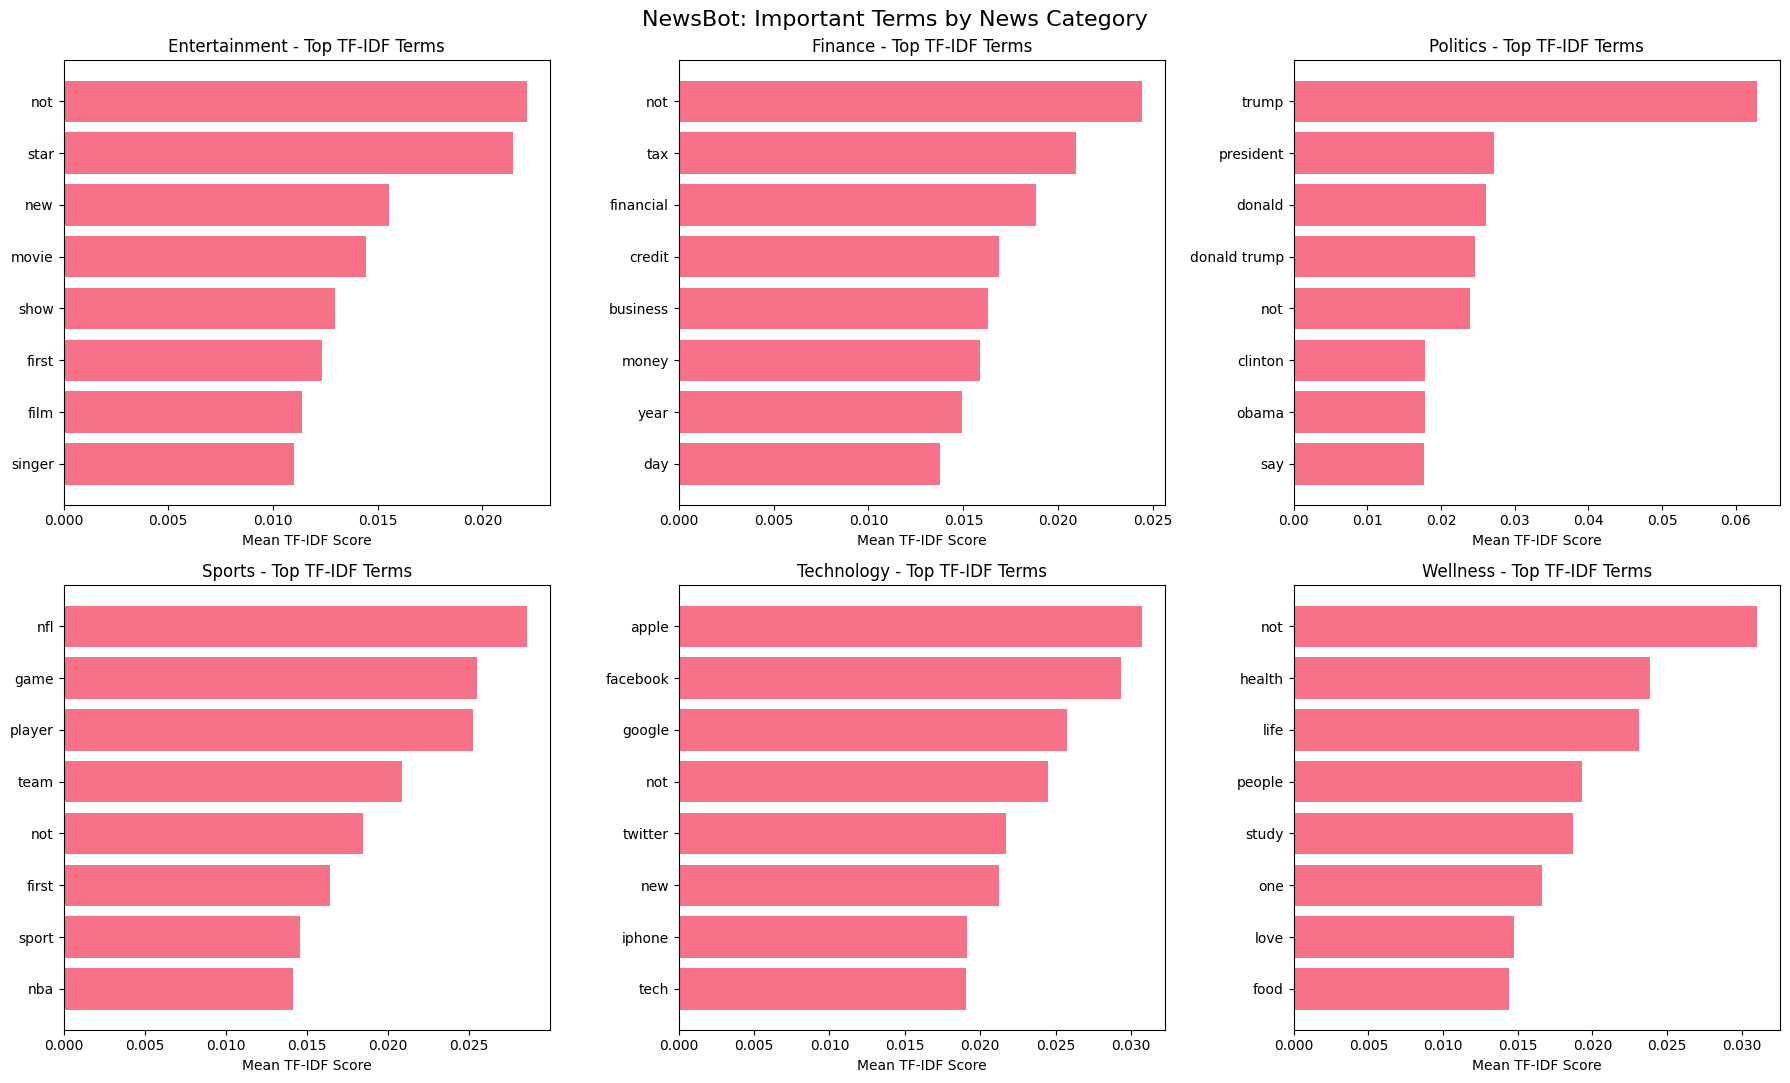

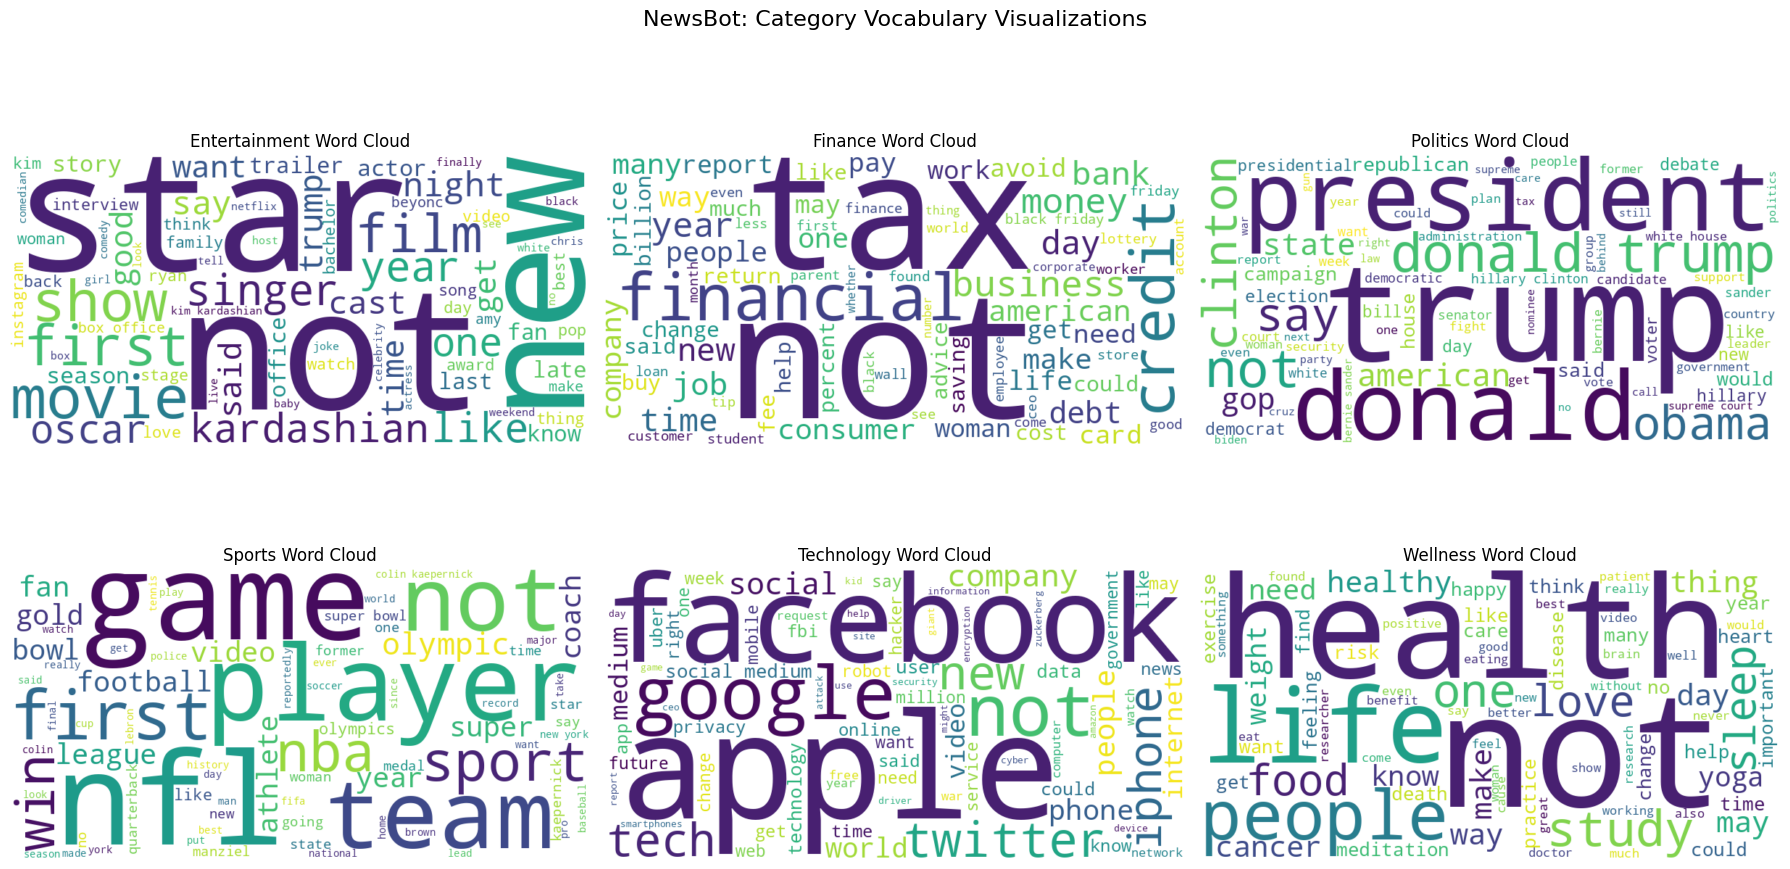

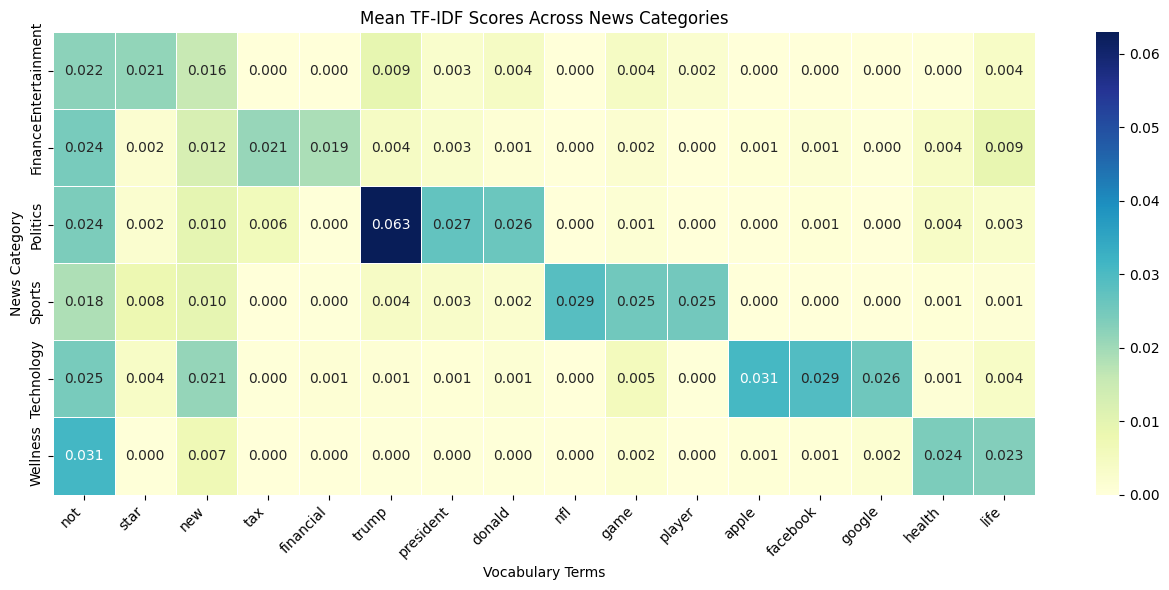


TERM INSPECTION: ABORTION
Documents containing 'abortion': 2
Term exists in the TF-IDF vocabulary.

Category distribution:


,Articles
category,
Politics,2



Matching headlines:


,article_id,category,title
730,731,Politics,Mike Pence To Anti-Abortion Crowd: Trump's Sup...
1331,1332,Politics,Abby Johnson Spreads Falsehoods About Abortion...



CATEGORY TF-IDF VALIDATION COMPLETE
Categories analyzed: 6
Unique comparison terms: 16
Category keyword extraction: Passed
Cross-category comparison: Passed
Results exported: newsbot_category_tfidf_terms.csv


In [9]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 13 - CATEGORY-SPECIFIC TF-IDF ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df, tfidf_matrix, feature_names from Cell 12
# - pandas, NumPy, Matplotlib, Seaborn, WordCloud from Cell 4

print("=" * 60)
print("NEWSBOT CATEGORY-SPECIFIC TF-IDF ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. CALCULATE MEAN TF-IDF SCORES BY CATEGORY
# ------------------------------------------------------------

# Work directly with the sparse TF-IDF matrix
# to avoid unnecessary dense memory allocation.

categories = sorted(df["category"].unique())

category_mean_scores = {}

for category in categories:

    category_mask = (
        df["category"].to_numpy() == category
    )

    category_matrix = tfidf_matrix[category_mask]

    mean_scores = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()

    category_mean_scores[category] = pd.Series(
        mean_scores,
        index=feature_names
    )

# ------------------------------------------------------------
# 2. DEFINE CATEGORY TERM EXTRACTION FUNCTION
# ------------------------------------------------------------

def get_top_tfidf_terms(category, n_terms=10):
    """
    Return the highest average TF-IDF terms for
    a specified NewsBot category.

    These scores describe terms within the category.
    They do not independently establish that a term
    is exclusive to that category.
    """

    if category not in category_mean_scores:
        raise ValueError(
            f"Unknown category: {category}"
        )

    return (
        category_mean_scores[category]
        .sort_values(ascending=False)
        .head(n_terms)
    )

# ------------------------------------------------------------
# 3. IDENTIFY TOP TERMS FOR ALL CATEGORIES
# ------------------------------------------------------------

category_terms = {}
category_term_records = []

for category in categories:

    top_terms = get_top_tfidf_terms(
        category,
        n_terms=10
    )

    category_terms[category] = top_terms

    print(f"\n{category.upper()}")
    print("-" * 45)

    for term, score in top_terms.items():

        print(f"{term:<25} {score:.4f}")

        category_term_records.append({
            "Category": category,
            "Term": term,
            "Mean TF-IDF": float(score)
        })

category_terms_df = pd.DataFrame(
    category_term_records
)

print("\n" + "=" * 60)
print("TOP TF-IDF TERMS - SUMMARY TABLE")
print("=" * 60)

display(
    category_terms_df.round(4)
)

# ------------------------------------------------------------
# 4. BAR CHARTS: TOP TERMS BY CATEGORY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

for ax, category in zip(axes, categories):

    top_terms = (
        category_terms[category]
        .head(8)
        .sort_values()
    )

    ax.barh(
        top_terms.index,
        top_terms.values
    )

    ax.set_title(
        f"{category} - Top TF-IDF Terms"
    )

    ax.set_xlabel("Mean TF-IDF Score")
    ax.set_ylabel("")

plt.suptitle(
    "NewsBot: Important Terms by News Category",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. WORD CLOUDS: CATEGORY KEYWORDS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

axes = axes.flatten()

for ax, category in zip(axes, categories):

    term_weights = (
        category_mean_scores[category]
        .sort_values(ascending=False)
        .head(75)
    )

    weights = {
        term: float(score)
        for term, score in term_weights.items()
        if score > 0
    }

    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white",
        colormap="viridis",
        random_state=42,
        collocations=False
    ).generate_from_frequencies(weights)

    ax.imshow(
        cloud,
        interpolation="bilinear"
    )

    ax.set_title(
        f"{category} Word Cloud"
    )

    ax.axis("off")

plt.suptitle(
    "NewsBot: Category Vocabulary Visualizations",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CROSS-CATEGORY TF-IDF HEATMAP
# ------------------------------------------------------------

# Select three high-scoring terms per category.
# Remove duplicates to create a comparison vocabulary.

comparison_terms = []

for category in categories:

    comparison_terms.extend(
        category_terms[category].head(3).index
    )

comparison_terms = list(
    dict.fromkeys(comparison_terms)
)

heatmap_data = pd.DataFrame({
    category: category_mean_scores[category].loc[
        comparison_terms
    ]
    for category in categories
}).T

plt.figure(
    figsize=(max(13, len(comparison_terms) * 0.7), 6)
)

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".3f",
    linewidths=0.4
)

plt.title(
    "Mean TF-IDF Scores Across News Categories"
)

plt.xlabel("Vocabulary Terms")
plt.ylabel("News Category")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. TERM INSPECTION
# ------------------------------------------------------------

# Example: investigate a topic that appears in
# the vocabulary but not in the first displayed rows.

TERM_TO_CHECK = "abortion"

print("\n" + "=" * 60)
print(f"TERM INSPECTION: {TERM_TO_CHECK.upper()}")
print("=" * 60)

term_pattern = (
    r"\b" + re.escape(TERM_TO_CHECK) + r"\b"
)

term_matches = df[
    df["full_text"].str.contains(
        term_pattern,
        case=False,
        regex=True,
        na=False
    )
]

print(
    f"Documents containing '{TERM_TO_CHECK}': "
    f"{len(term_matches)}"
)

if TERM_TO_CHECK in tfidf_vectorizer.vocabulary_:
    print("Term exists in the TF-IDF vocabulary.")
else:
    print(
        "Term is not in the TF-IDF vocabulary "
        "or was excluded by vectorizer settings."
    )

if not term_matches.empty:

    print("\nCategory distribution:")
    display(
        term_matches["category"]
        .value_counts()
        .rename("Articles")
        .to_frame()
    )

    print("\nMatching headlines:")
    display(
        term_matches[
            ["article_id", "category", "title"]
        ]
    )

# ------------------------------------------------------------
# 8. EXPORT CATEGORY TERM ANALYSIS
# ------------------------------------------------------------

category_terms_df.to_csv(
    "newsbot_category_tfidf_terms.csv",
    index=False
)

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

assert len(category_terms) == 6, (
    "Expected six categories."
)

assert all(
    len(terms) == 10
    for terms in category_terms.values()
), "Every category should contain ten top terms."

assert not category_terms_df.empty, (
    "Category term analysis is empty."
)

print("\n" + "=" * 60)
print("CATEGORY TF-IDF VALIDATION COMPLETE")
print("=" * 60)

print(f"Categories analyzed: {len(category_terms)}")
print(f"Unique comparison terms: {len(comparison_terms)}")
print("Category keyword extraction: Passed")
print("Cross-category comparison: Passed")
print("Results exported: newsbot_category_tfidf_terms.csv")


## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [10]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 15 - PART-OF-SPEECH TAGGING AND ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df and full_text from Cell 10
# - word_tokenize, pos_tag, pandas, Counter from Cell 4
# - NLTK POS resources installed in Cell 3

print("=" * 60)
print("NEWSBOT PART-OF-SPEECH ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE INPUT DATA
# ------------------------------------------------------------

required_columns = [
    "article_id",
    "category",
    "full_text"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print(f"Records available: {len(df):,}")
print(f"Categories: {df['category'].nunique()}")

print(
    "\nPOS tagging uses original headline and "
    "description text to preserve grammar and numbers."
)

# ------------------------------------------------------------
# 2. DEFINE POS ANALYSIS FUNCTION
# ------------------------------------------------------------

def analyze_pos_patterns(text):
    """
    Analyze grammatical patterns using NLTK.

    Steps:
    1. Handle missing or empty text.
    2. Tokenize the original text.
    3. Assign Penn Treebank POS tags.
    4. Exclude punctuation-only tokens from counts.
    5. Calculate proportions for each POS category.

    Returns:
        Dictionary containing POS tag proportions.
    """

    if text is None or pd.isna(text):
        return {}

    text = str(text).strip()

    if not text:
        return {}

    # Preserve original wording and capitalization.
    tokens = word_tokenize(text)

    if not tokens:
        return {}

    # Tag tokens using the NLTK English POS tagger.
    tagged_tokens = pos_tag(tokens)

    # Exclude punctuation-only tokens from proportions.
    # Numbers are retained for CD analysis.
    tagged_words = [
        (word, tag)
        for word, tag in tagged_tokens
        if any(char.isalnum() for char in word)
    ]

    if not tagged_words:
        return {}

    pos_counts = Counter(
        tag for word, tag in tagged_words
    )

    total_words = len(tagged_words)

    pos_proportions = {
        tag: count / total_words
        for tag, count in pos_counts.items()
    }

    return pos_proportions

# ------------------------------------------------------------
# 3. APPLY POS ANALYSIS TO ALL RECORDS
# ------------------------------------------------------------

print("\nAnalyzing grammatical patterns...")

pos_results = []

for _, row in df.iterrows():

    pos_analysis = analyze_pos_patterns(
        row["full_text"]
    )

    pos_analysis["article_id"] = row["article_id"]
    pos_analysis["category"] = row["category"]

    pos_results.append(pos_analysis)

# Convert results to a structured DataFrame.
# Missing tags receive a proportion of zero.

pos_df = pd.DataFrame(
    pos_results
).fillna(0)

# Identify only the POS feature columns.
pos_columns = [
    column for column in pos_df.columns
    if column not in ["article_id", "category"]
]

print("\nPOS analysis completed.")
print(f"Records analyzed: {len(pos_df):,}")
print(f"Unique POS tags identified: {len(pos_columns)}")

# ------------------------------------------------------------
# 4. VALIDATE TAG PROPORTIONS
# ------------------------------------------------------------

# Each record should have POS proportions summing to 1.

pos_totals = pos_df[pos_columns].sum(axis=1)

assert len(pos_df) == len(df), (
    "POS analysis record count mismatch."
)

assert pos_df["category"].tolist() == (
    df["category"].tolist()
), "POS labels are not aligned with the dataset."

assert np.allclose(
    pos_totals.to_numpy(),
    1.0
), "One or more records contain invalid POS proportions."

print("\nPOS proportion validation: Passed")
print("Category alignment: Passed")

# ------------------------------------------------------------
# 5. INSPECT EXAMPLE POS TAGGING
# ------------------------------------------------------------

sample_record = df.iloc[0]

sample_text = sample_record["full_text"]

sample_tokens = word_tokenize(sample_text)

sample_tags = pos_tag(sample_tokens)

sample_pos_df = pd.DataFrame(
    sample_tags,
    columns=["Token", "POS Tag"]
)

print("\n" + "=" * 60)
print("EXAMPLE POS TAGGING")
print("=" * 60)

print(f"Article ID: {sample_record['article_id']}")
print(f"Category: {sample_record['category']}")
print(f"Headline: {sample_record['title']}")

print("\nFirst 25 tagged tokens:")

display(
    sample_pos_df.head(25)
)

# ------------------------------------------------------------
# 6. DISPLAY STRUCTURED POS RESULTS
# ------------------------------------------------------------

important_tags = [
    "NN", "NNS", "NNP", "NNPS",
    "VB", "VBD", "VBG", "VBN", "VBP", "VBZ",
    "JJ", "RB", "CD"
]

available_tags = [
    tag for tag in important_tags
    if tag in pos_df.columns
]

preview_columns = (
    ["article_id", "category"] +
    available_tags
)

print("\n" + "=" * 60)
print("POS FEATURE DATASET PREVIEW")
print("=" * 60)

display(
    pos_df[preview_columns].head().round(4)
)

# ------------------------------------------------------------
# 7. CALCULATE OVERALL POS FREQUENCIES
# ------------------------------------------------------------

# Sum the per-document POS proportions to compare
# grammatical feature prevalence in the sampled corpus.

overall_pos_scores = (
    pos_df[pos_columns]
    .mean()
    .sort_values(ascending=False)
)

print("\n" + "=" * 60)
print("TOP POS TAGS ACROSS THE DATASET")
print("=" * 60)

overall_pos_summary = (
    overall_pos_scores
    .head(12)
    .rename_axis("POS Tag")
    .reset_index(name="Mean Proportion")
)

display(
    overall_pos_summary.round(4)
)

# ------------------------------------------------------------
# 8. VERIFY NUMERICAL INFORMATION IS PRESERVED
# ------------------------------------------------------------

# The CD tag is important for evaluating the
# professor's hypothesis about business/finance text.

if "CD" in pos_df.columns:

    records_with_numbers = (
        pos_df["CD"] > 0
    ).sum()

    print("\nNUMERICAL LANGUAGE:")
    print(
        f"Records containing CD tags: "
        f"{records_with_numbers:,}"
    )

    print(
        f"Percentage of records: "
        f"{records_with_numbers / len(pos_df) * 100:.2f}%"
    )

else:
    print(
        "\nNo CD tags detected. "
        "Review the original input text."
    )

# ------------------------------------------------------------
# 9. EXPORT POS FEATURES
# ------------------------------------------------------------

pos_df.to_csv(
    "newsbot_pos_features.csv",
    index=False
)

print("\n" + "=" * 60)
print("POS ANALYSIS VALIDATION COMPLETE")
print("=" * 60)

print("POS tagging: Passed")
print("Feature extraction: Passed")
print("Proportion validation: Passed")
print("Category alignment: Passed")
print("Results exported: newsbot_pos_features.csv")


NEWSBOT PART-OF-SPEECH ANALYSIS
Records available: 2,000
Categories: 6

POS tagging uses original headline and description text to preserve grammar and numbers.

Analyzing grammatical patterns...

POS analysis completed.
Records analyzed: 2,000
Unique POS tags identified: 36

POS proportion validation: Passed
Category alignment: Passed

EXAMPLE POS TAGGING
Article ID: 1
Category: Technology
Headline: CrowdRise: More Fun Than Just Reading the News

First 25 tagged tokens:


,Token,POS Tag
0,CrowdRise,NN
1,:,:
2,More,JJR
3,Fun,NNP
4,Than,NNP
5,Just,NNP
6,Reading,VBG
7,the,DT
8,News,NNP
9,CrowdRise,NNP



POS FEATURE DATASET PREVIEW


,article_id,category,NN,NNS,NNP,NNPS,VB,VBD,VBG,VBN,VBP,VBZ,JJ,RB,CD
0,1,Technology,0.1538,0.0192,0.0962,0.0,0.0962,0.0000,0.0192,0.0192,0.0192,0.0385,0.0769,0.0192,0.0000
1,2,Finance,0.1212,0.0606,0.3333,0.0,0.0000,0.0303,0.0000,0.0303,0.0000,0.0303,0.0000,0.0303,0.0000
2,3,Wellness,0.0667,0.0333,0.3333,0.0,0.0333,0.0000,0.0667,0.0000,0.0333,0.0000,0.0667,0.0000,0.0333
3,4,Entertainment,0.0526,0.0000,0.4737,0.0,0.0000,0.0526,0.0526,0.0000,0.0000,0.0000,0.0526,0.0526,0.0000
4,5,Sports,0.1389,0.0278,0.3889,0.0,0.0556,0.0278,0.0000,0.0000,0.0278,0.0278,0.0000,0.0278,0.0278



TOP POS TAGS ACROSS THE DATASET


,POS Tag,Mean Proportion
0,NNP,0.2772
1,NN,0.1053
2,IN,0.1018
3,DT,0.0784
4,JJ,0.0549
5,NNS,0.0439
6,RB,0.0343
7,VB,0.0330
8,PRP,0.0324
9,VBZ,0.0282



NUMERICAL LANGUAGE:
Records containing CD tags: 673
Percentage of records: 33.65%

POS ANALYSIS VALIDATION COMPLETE
POS tagging: Passed
Feature extraction: Passed
Proportion validation: Passed
Category alignment: Passed
Results exported: newsbot_pos_features.csv


NEWSBOT POS PATTERNS BY CATEGORY

MEAN POS TAG PROPORTIONS:


,NN,NNS,NNP,NNPS,VB,VBD,VBG,VBN,VBP,VBZ,JJ,JJR,JJS,RB,RBR,RBS,CD
category,,,,,,,,,,,,,,,,,
Entertainment,0.0876,0.0234,0.3700,0.0030,0.0242,0.0261,0.0144,0.0113,0.0130,0.0312,0.0462,0.0021,0.0027,0.0323,0.0007,0.0003,0.0145
Finance,0.1206,0.0616,0.2031,0.0056,0.0387,0.0180,0.0276,0.0145,0.0250,0.0268,0.0628,0.0056,0.0030,0.0333,0.0016,0.0010,0.0215
Politics,0.0999,0.0443,0.3068,0.0088,0.0313,0.0244,0.0191,0.0131,0.0185,0.0270,0.0538,0.0032,0.0014,0.0326,0.0015,0.0003,0.0115
Sports,0.0889,0.0295,0.3668,0.0066,0.0259,0.0285,0.0173,0.0136,0.0125,0.0259,0.0437,0.0025,0.0024,0.0302,0.0008,0.0004,0.0174
Technology,0.1129,0.0479,0.2659,0.0051,0.0346,0.0211,0.0197,0.0158,0.0219,0.0308,0.0548,0.0036,0.0031,0.0343,0.0013,0.0007,0.0157
Wellness,0.1216,0.0565,0.1506,0.0033,0.0435,0.0120,0.0292,0.0144,0.0353,0.0278,0.0679,0.0046,0.0038,0.0435,0.0022,0.0009,0.0162



GRAMMATICAL FEATURES BY CATEGORY (%)


,Common Nouns,Proper Nouns,All Verbs,Selected Verb Forms,Adjectives,Adverbs,Numbers
category,,,,,,,
Entertainment,11.10,37.30,12.01,6.46,5.09,3.32,1.45
Finance,18.22,20.87,15.06,8.43,7.14,3.59,2.15
Politics,14.43,31.56,13.33,7.48,5.84,3.44,1.15
Sports,11.83,37.34,12.37,7.18,4.87,3.14,1.74
Technology,16.08,27.10,14.40,7.55,6.15,3.62,1.57
Wellness,17.82,15.38,16.22,8.47,7.63,4.65,1.62


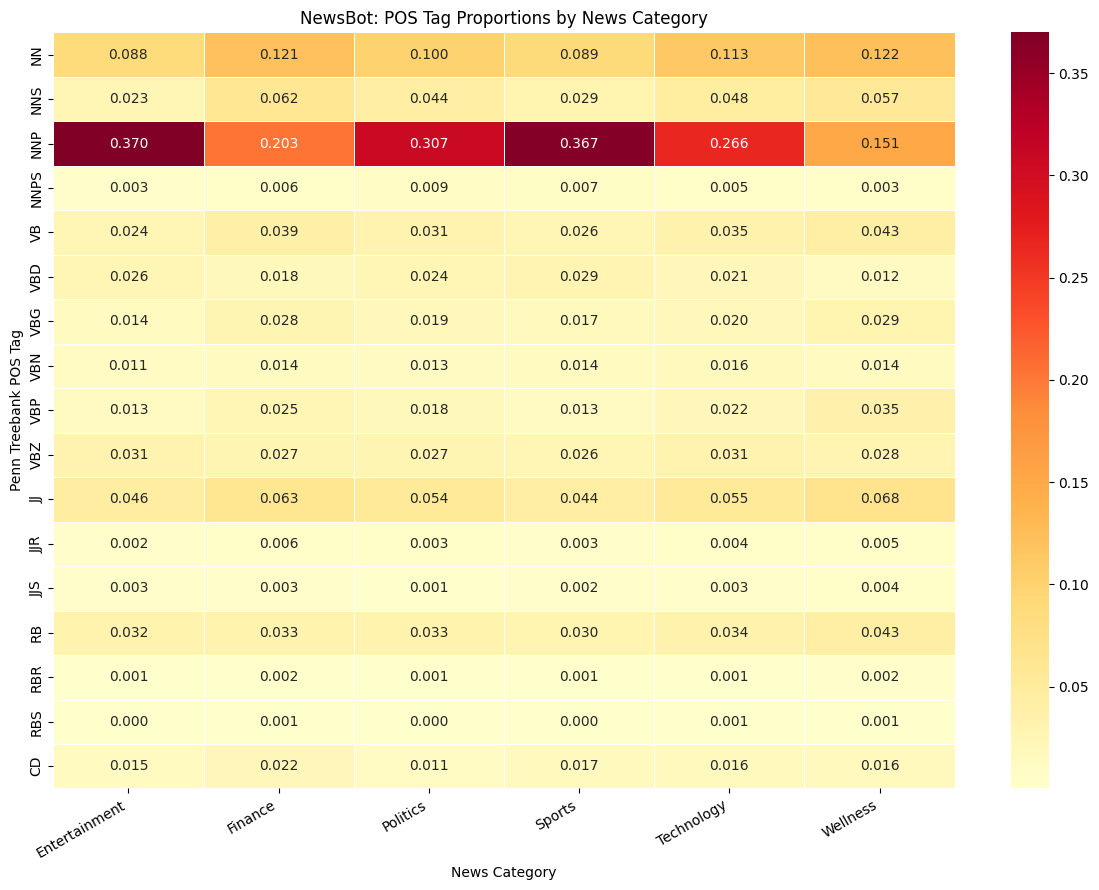

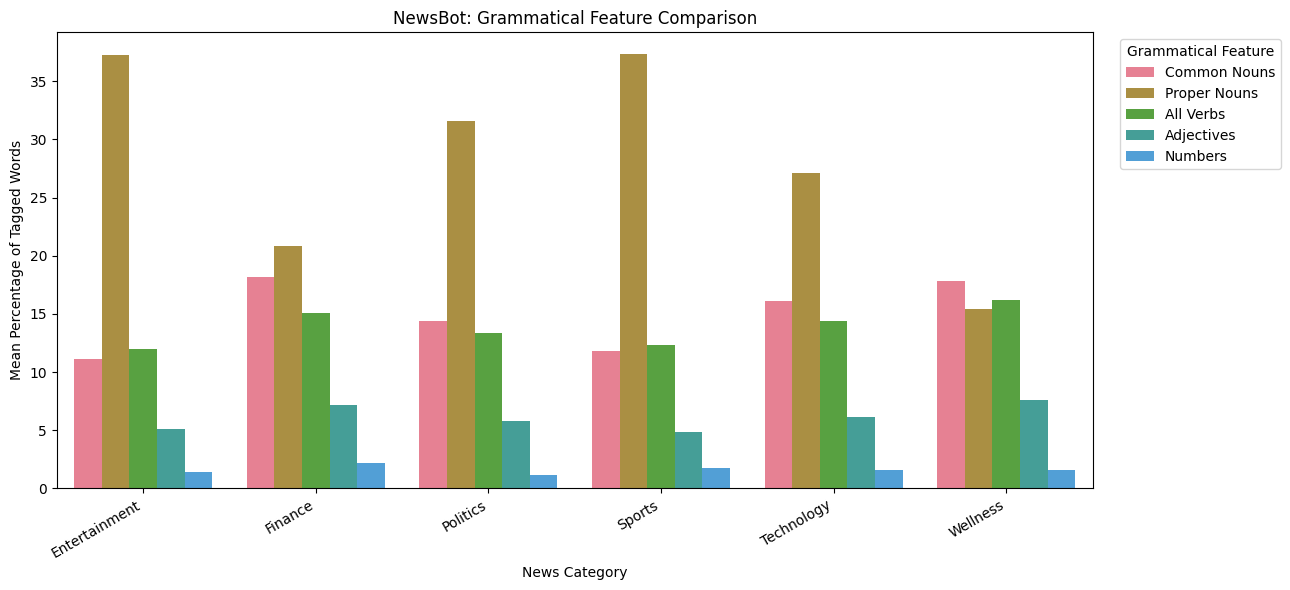


POS ANALYSIS FINDINGS

1. PROPER NOUNS (NNP / NNPS)
Highest: Sports (37.34%)
Lowest: Wellness (15.38%)

2. SELECTED VERB FORMS (VB / VBD / VBG)
Highest: Wellness (8.47%)
Sports: 7.18%
Note: These tags measure grammatical verb forms, not whether a verb expresses physical action.

3. ADJECTIVE USAGE (JJ / JJR / JJS)
Highest: Wellness (7.63%)
Lowest: Sports (4.87%)

4. NUMBER USAGE (CD)
Highest: Finance (2.15%)
Finance: 2.15%

HYPOTHESIS EVALUATION

SPORTS VERB HYPOTHESIS
Sports: 7.18%
Other categories (equal-category average): 7.68%
Observation: Sports does not exceed the other-category average.

FINANCE NUMBER HYPOTHESIS
Finance: 2.15%
Other categories (equal-category average): 1.51%
Observation: Finance has a higher proportion of numerical tags than the other-category average.

FINANCE PROPER NOUN HYPOTHESIS
Finance: 20.87%
Other categories (equal-category average): 29.74%
Observation: Finance does not exceed the other-category average.

ANALYSIS LIMITATIONS
1. POS tagging is automate

In [11]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 16 - POS PATTERNS BY NEWS CATEGORY
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - pos_df from Cell 15
# - df from previous analysis cells
# - pandas, NumPy, Matplotlib, Seaborn from Cell 4

print("=" * 60)
print("NEWSBOT POS PATTERNS BY CATEGORY")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE POS DATA
# ------------------------------------------------------------

assert len(pos_df) == len(df), (
    "POS dataset does not match article count."
)

assert pos_df["article_id"].tolist() == (
    df["article_id"].tolist()
), "Article IDs are not aligned."

assert pos_df["category"].tolist() == (
    df["category"].tolist()
), "Categories are not aligned."

# Only grammatical features should be averaged.
# Exclude article_id because it is an identifier,
# not a linguistic feature.

pos_feature_columns = [
    column for column in pos_df.columns
    if column not in ["article_id", "category"]
]

# ------------------------------------------------------------
# 2. MEAN POS PROPORTIONS BY CATEGORY
# ------------------------------------------------------------

pos_by_category = (
    pos_df.groupby("category")[pos_feature_columns]
    .mean()
    .sort_index()
)

# Original Penn Treebank tags from the professor's
# exercise, including nouns, verbs, adjectives,
# adverbs, and cardinal numbers.

major_pos = [
    "NN", "NNS", "NNP", "NNPS",
    "VB", "VBD", "VBG", "VBN", "VBP", "VBZ",
    "JJ", "JJR", "JJS",
    "RB", "RBR", "RBS",
    "CD"
]

available_pos = [
    tag for tag in major_pos
    if tag in pos_by_category.columns
]

pos_summary = pos_by_category[available_pos].copy()

print("\nMEAN POS TAG PROPORTIONS:")
display(pos_summary.round(4))

# ------------------------------------------------------------
# 3. GROUP RELATED GRAMMATICAL FEATURES
# ------------------------------------------------------------

pos_groups = {
    "Common Nouns": ["NN", "NNS"],
    "Proper Nouns": ["NNP", "NNPS"],
    "All Verbs": [
        "VB", "VBD", "VBG",
        "VBN", "VBP", "VBZ"
    ],
    "Selected Verb Forms": ["VB", "VBD", "VBG"],
    "Adjectives": ["JJ", "JJR", "JJS"],
    "Adverbs": ["RB", "RBR", "RBS"],
    "Numbers": ["CD"]
}

# Categories are expressed as percentages
# for easier comparison and interpretation.

pos_group_summary = pd.DataFrame(
    index=pos_by_category.index
)

for group_name, tags in pos_groups.items():

    present_tags = [
        tag for tag in tags
        if tag in pos_by_category.columns
    ]

    if present_tags:
        proportions = pos_by_category[
            present_tags
        ].sum(axis=1)
    else:
        proportions = pd.Series(
            0.0,
            index=pos_by_category.index
        )

    pos_group_summary[group_name] = (
        proportions * 100
    )

print("\n" + "=" * 60)
print("GRAMMATICAL FEATURES BY CATEGORY (%)")
print("=" * 60)

display(pos_group_summary.round(2))

# ------------------------------------------------------------
# 4. ORIGINAL POS TAG HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 9))

sns.heatmap(
    pos_summary.T,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.4
)

plt.title(
    "NewsBot: POS Tag Proportions by News Category"
)

plt.xlabel("News Category")
plt.ylabel("Penn Treebank POS Tag")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. COMPARATIVE GRAMMATICAL FEATURES
# ------------------------------------------------------------

comparison_features = [
    "Common Nouns",
    "Proper Nouns",
    "All Verbs",
    "Adjectives",
    "Numbers"
]

comparison_df = (
    pos_group_summary[comparison_features]
    .reset_index()
    .melt(
        id_vars="category",
        var_name="Grammatical Feature",
        value_name="Mean Percentage"
    )
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=comparison_df,
    x="category",
    y="Mean Percentage",
    hue="Grammatical Feature"
)

plt.title(
    "NewsBot: Grammatical Feature Comparison"
)

plt.xlabel("News Category")
plt.ylabel("Mean Percentage of Tagged Words")
plt.xticks(rotation=30, ha="right")
plt.legend(
    title="Grammatical Feature",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. ANSWER THE PROFESSOR'S ANALYSIS QUESTIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("POS ANALYSIS FINDINGS")
print("=" * 60)

# Question 1: Proper noun distribution

proper_noun_ranking = (
    pos_group_summary["Proper Nouns"]
    .sort_values(ascending=False)
)

print("\n1. PROPER NOUNS (NNP / NNPS)")
print(
    f"Highest: {proper_noun_ranking.index[0]} "
    f"({proper_noun_ranking.iloc[0]:.2f}%)"
)

print(
    f"Lowest: {proper_noun_ranking.index[-1]} "
    f"({proper_noun_ranking.iloc[-1]:.2f}%)"
)

# Question 2: Verb distribution

verb_ranking = (
    pos_group_summary["Selected Verb Forms"]
    .sort_values(ascending=False)
)

print("\n2. SELECTED VERB FORMS (VB / VBD / VBG)")
print(
    f"Highest: {verb_ranking.index[0]} "
    f"({verb_ranking.iloc[0]:.2f}%)"
)

print(
    f"Sports: "
    f"{pos_group_summary.loc['Sports', 'Selected Verb Forms']:.2f}%"
)

print(
    "Note: These tags measure grammatical verb forms, "
    "not whether a verb expresses physical action."
)

# Question 3: Adjective distribution

adjective_ranking = (
    pos_group_summary["Adjectives"]
    .sort_values(ascending=False)
)

print("\n3. ADJECTIVE USAGE (JJ / JJR / JJS)")
print(
    f"Highest: {adjective_ranking.index[0]} "
    f"({adjective_ranking.iloc[0]:.2f}%)"
)

print(
    f"Lowest: {adjective_ranking.index[-1]} "
    f"({adjective_ranking.iloc[-1]:.2f}%)"
)

# Question 4: Numerical language

number_ranking = (
    pos_group_summary["Numbers"]
    .sort_values(ascending=False)
)

print("\n4. NUMBER USAGE (CD)")
print(
    f"Highest: {number_ranking.index[0]} "
    f"({number_ranking.iloc[0]:.2f}%)"
)

print(
    f"Finance: "
    f"{pos_group_summary.loc['Finance', 'Numbers']:.2f}%"
)

# ------------------------------------------------------------
# 7. EVALUATE THE PROFESSOR'S HYPOTHESIS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("HYPOTHESIS EVALUATION")
print("=" * 60)

sports_verb_rate = pos_group_summary.loc[
    "Sports", "Selected Verb Forms"
]

other_verb_rate = (
    pos_group_summary.drop(index="Sports")[
        "Selected Verb Forms"
    ].mean()
)

finance_number_rate = pos_group_summary.loc[
    "Finance", "Numbers"
]

other_number_rate = (
    pos_group_summary.drop(index="Finance")[
        "Numbers"
    ].mean()
)

finance_proper_noun_rate = pos_group_summary.loc[
    "Finance", "Proper Nouns"
]

other_proper_noun_rate = (
    pos_group_summary.drop(index="Finance")[
        "Proper Nouns"
    ].mean()
)

print("\nSPORTS VERB HYPOTHESIS")
print(f"Sports: {sports_verb_rate:.2f}%")
print(
    f"Other categories (equal-category average): "
    f"{other_verb_rate:.2f}%"
)

if sports_verb_rate > other_verb_rate:
    print(
        "Observation: Sports has a higher proportion "
        "of selected verb forms than the other-category average."
    )
else:
    print(
        "Observation: Sports does not exceed "
        "the other-category average."
    )

print("\nFINANCE NUMBER HYPOTHESIS")
print(f"Finance: {finance_number_rate:.2f}%")
print(
    f"Other categories (equal-category average): "
    f"{other_number_rate:.2f}%"
)

if finance_number_rate > other_number_rate:
    print(
        "Observation: Finance has a higher proportion "
        "of numerical tags than the other-category average."
    )
else:
    print(
        "Observation: Finance does not exceed "
        "the other-category average."
    )

print("\nFINANCE PROPER NOUN HYPOTHESIS")
print(f"Finance: {finance_proper_noun_rate:.2f}%")
print(
    f"Other categories (equal-category average): "
    f"{other_proper_noun_rate:.2f}%"
)

if finance_proper_noun_rate > other_proper_noun_rate:
    print(
        "Observation: Finance has a higher proportion "
        "of proper nouns than the other-category average."
    )
else:
    print(
        "Observation: Finance does not exceed "
        "the other-category average."
    )

# ------------------------------------------------------------
# 8. DOCUMENT INTERPRETATION LIMITATIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ANALYSIS LIMITATIONS")
print("=" * 60)

print(
    "1. POS tagging is automated and may contain errors."
)

print(
    "2. Title capitalization can influence proper noun tags."
)

print(
    "3. Results describe headlines and short descriptions, "
    "not complete news articles."
)

print(
    "4. Selected verb forms are not a direct measure "
    "of action-oriented language."
)

print(
    "5. Category averages are descriptive; "
    "they do not establish statistical significance."
)

# ------------------------------------------------------------
# 9. EXPORT CATEGORY POS RESULTS
# ------------------------------------------------------------

pos_summary.to_csv(
    "newsbot_pos_tag_summary.csv"
)

pos_group_summary.to_csv(
    "newsbot_pos_category_analysis.csv"
)

# ------------------------------------------------------------
# 10. FINAL VALIDATION
# ------------------------------------------------------------

assert len(pos_group_summary) == 6, (
    "Expected six NewsBot categories."
)

assert pos_group_summary.notna().all().all(), (
    "Missing values in POS analysis."
)

assert (
    pos_group_summary >= 0
).all().all(), "Invalid negative POS proportions."

print("\n" + "=" * 60)
print("POS CATEGORY ANALYSIS VALIDATION COMPLETE")
print("=" * 60)

print("Six-category analysis: Passed")
print("Grammatical feature comparisons: Passed")
print("Hypothesis calculations: Passed")
print("Results exported successfully.")


## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [12]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 18 - SYNTAX PARSING AND FEATURE EXTRACTION
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df["full_text"] from Cell 10
# - spaCy English model (nlp) from Cell 4
# - Counter, pandas, NumPy from Cell 4

print("=" * 60)
print("NEWSBOT SYNTAX PARSING AND SEMANTIC ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE INPUT DATA
# ------------------------------------------------------------

required_columns = [
    "article_id",
    "category",
    "full_text"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

assert nlp.has_pipe("parser"), (
    "The spaCy dependency parser is required."
)

print(f"Records available: {len(df):,}")
print(f"Categories: {df['category'].nunique()}")

print(
    "\nUsing original text to preserve "
    "grammatical and sentence structure."
)

# ------------------------------------------------------------
# 2. DEFINE SYNTACTIC FEATURE EXTRACTION
# ------------------------------------------------------------

def extract_syntactic_features(text, doc=None):
    """
    Extract syntactic features using spaCy.

    Features:
    - Sentence and token counts
    - Dependency relations
    - Noun phrases
    - Approximate verb constructions
    - Subjects and objects
    - Simple active subject-verb-object patterns
    - Sentence length
    - Dependency distance

    SVO patterns are heuristic extractions.
    They are not verified semantic facts.
    """

    if doc is None:
        if text is None or not str(text).strip():
            doc = nlp("")
        else:
            doc = nlp(str(text))

    sentences = list(doc.sents)

    valid_tokens = [
        token for token in doc
        if not token.is_space and not token.is_punct
    ]

    features = {
        "num_sentences": len(sentences),
        "num_tokens": len(valid_tokens),
        "dependency_relations": [],
        "noun_phrases": [],
        "verb_phrases": [],
        "subjects": [],
        "objects": [],
        "svo_patterns": [],
        "dependency_counts": {},
        "num_noun_phrases": 0,
        "num_svo_patterns": 0,
        "avg_sentence_length": 0.0,
        "avg_dependency_distance": 0.0
    }

    if not valid_tokens:
        return features

    # --------------------------------------------------------
    # A. DEPENDENCY RELATIONS
    # --------------------------------------------------------

    features["dependency_relations"] = [
        token.dep_
        for token in valid_tokens
    ]

    features["dependency_counts"] = dict(
        Counter(features["dependency_relations"])
    )

    # --------------------------------------------------------
    # B. NOUN PHRASES
    # --------------------------------------------------------

    features["noun_phrases"] = [
        chunk.text.strip()
        for chunk in doc.noun_chunks
    ]

    features["num_noun_phrases"] = len(
        features["noun_phrases"]
    )

    # --------------------------------------------------------
    # C. SUBJECTS, OBJECTS, AND VERB CONSTRUCTIONS
    # --------------------------------------------------------

    subject_tags = {"nsubj", "nsubjpass", "csubj"}
    object_tags = {"dobj", "obj", "iobj", "pobj"}

    for token in valid_tokens:

        if token.dep_ in subject_tags:
            features["subjects"].append(token.text)

        if token.dep_ in object_tags:
            features["objects"].append(token.text)

        # Approximate verb construction:
        # Main verb plus attached auxiliaries,
        # negations, and particles.
        if token.pos_ == "VERB":

            components = [
                child
                for child in token.children
                if child.dep_ in {
                    "aux", "auxpass", "neg", "prt"
                }
            ]

            components.append(token)

            components = sorted(
                components,
                key=lambda item: item.i
            )

            phrase = " ".join(
                item.text for item in components
            )

            features["verb_phrases"].append(phrase)

    # --------------------------------------------------------
    # D. SIMPLE SUBJECT-VERB-OBJECT PATTERNS
    # --------------------------------------------------------

    # Extract direct active SVO relationships.
    # Passive sentences and more complex constructions
    # may not produce a triple using these rules.

    for token in doc:

        if token.pos_ not in {"VERB", "AUX"}:
            continue

        subjects = [
            child
            for child in token.children
            if child.dep_ in {"nsubj", "csubj"}
        ]

        objects = [
            child
            for child in token.children
            if child.dep_ in {"dobj", "obj", "iobj"}
        ]

        for subject in subjects:
            for obj in objects:

                pattern = (
                    subject.text,
                    token.lemma_,
                    obj.text
                )

                features["svo_patterns"].append(pattern)

    features["num_svo_patterns"] = len(
        features["svo_patterns"]
    )

    # --------------------------------------------------------
    # E. SENTENCE LENGTH AND DEPENDENCY DISTANCE
    # --------------------------------------------------------

    if sentences:

        sentence_lengths = [
            sum(
                1 for token in sent
                if not token.is_space
                and not token.is_punct
            )
            for sent in sentences
        ]

        features["avg_sentence_length"] = float(
            np.mean(sentence_lengths)
        )

    dependency_distances = [
        abs(token.i - token.head.i)
        for token in valid_tokens
        if token.head != token
    ]

    if dependency_distances:

        features["avg_dependency_distance"] = float(
            np.mean(dependency_distances)
        )

    return features

# ------------------------------------------------------------
# 3. APPLY SYNTACTIC ANALYSIS TO ALL ARTICLES
# ------------------------------------------------------------

print("\nProcessing syntactic features...")

syntactic_results = []

texts = df["full_text"].fillna("").astype(str).tolist()

# spaCy pipeline batching improves processing efficiency.
# Disable NER here because Cell 18 only needs
# tokenization, tagging, and dependency parsing.

for row, doc in zip(
    df.itertuples(index=False),
    nlp.pipe(
        texts,
        batch_size=64,
        disable=["ner"]
    )
):

    features = extract_syntactic_features(
        row.full_text,
        doc=doc
    )

    features["article_id"] = row.article_id
    features["category"] = row.category

    syntactic_results.append(features)

print("Syntactic analysis completed.")

# ------------------------------------------------------------
# 4. CREATE STRUCTURED SYNTACTIC FEATURE DATASET
# ------------------------------------------------------------

# Retain the full results in syntactic_results.
# Create a smaller numerical table for comparisons.

numeric_features = [
    "num_sentences",
    "num_tokens",
    "num_noun_phrases",
    "num_svo_patterns",
    "avg_sentence_length",
    "avg_dependency_distance"
]

syntactic_df = pd.DataFrame([
    {
        "article_id": result["article_id"],
        "category": result["category"],
        **{
            feature: result[feature]
            for feature in numeric_features
        }
    }
    for result in syntactic_results
])

print("\n" + "=" * 60)
print("SYNTACTIC FEATURE DATASET")
print("=" * 60)

display(
    syntactic_df.head().round(2)
)

# ------------------------------------------------------------
# 5. SHOW REPRESENTATIVE ARTICLES
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("REPRESENTATIVE SYNTACTIC ANALYSIS")
print("=" * 60)

# Display the first matching record from each category.
# Full syntactic analysis was performed on all records.

for category in sorted(df["category"].unique()):

    result = next(
        item for item in syntactic_results
        if item["category"] == category
    )

    article = df.loc[
        df["article_id"] == result["article_id"]
    ].iloc[0]

    print(f"\nCATEGORY: {category}")
    print(f"Article ID: {result['article_id']}")
    print(f"Title: {article['title']}")

    print(f"Sentences: {result['num_sentences']}")
    print(f"Tokens: {result['num_tokens']}")

    print(
        "Noun phrases:",
        result["noun_phrases"][:3]
    )

    print(
        "Verb constructions:",
        result["verb_phrases"][:3]
    )

    print(
        "Subjects:",
        result["subjects"][:3]
    )

    print(
        "Objects:",
        result["objects"][:3]
    )

    print(
        "SVO patterns:",
        result["svo_patterns"][:3]
    )

    print("-" * 60)

# ------------------------------------------------------------
# 6. OVERALL SYNTAX STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("OVERALL SYNTACTIC STATISTICS")
print("=" * 60)

summary_stats = (
    syntactic_df[numeric_features]
    .describe()
    .round(2)
)

display(summary_stats)

# Count dependency labels across all documents.
all_dependency_counts = Counter()

for result in syntactic_results:

    all_dependency_counts.update(
        result["dependency_counts"]
    )

top_dependencies = pd.DataFrame(
    all_dependency_counts.most_common(15),
    columns=["Dependency", "Frequency"]
)

print("\nMost common dependency relations:")
display(top_dependencies)

# ------------------------------------------------------------
# 7. EXPORT NUMERICAL RESULTS
# ------------------------------------------------------------

syntactic_df.to_csv(
    "newsbot_syntactic_features.csv",
    index=False
)

top_dependencies.to_csv(
    "newsbot_dependency_frequencies.csv",
    index=False
)

# ------------------------------------------------------------
# 8. VALIDATE RESULTS
# ------------------------------------------------------------

assert len(syntactic_results) == len(df), (
    "Not all articles were analyzed."
)

assert len(syntactic_df) == 2000, (
    "Unexpected number of syntactic records."
)

assert syntactic_df["article_id"].tolist() == (
    df["article_id"].tolist()
), "Article IDs are misaligned."

assert syntactic_df[numeric_features].notna().all().all(), (
    "Missing numerical syntax features detected."
)

assert (syntactic_df["num_tokens"] > 0).all(), (
    "One or more records contain no analyzed tokens."
)

print("\n" + "=" * 60)
print("SYNTACTIC ANALYSIS VALIDATION COMPLETE")
print("=" * 60)

print(f"Articles analyzed: {len(syntactic_results):,}")
print(f"Categories analyzed: {syntactic_df['category'].nunique()}")
print("Dependency extraction: Passed")
print("Numerical feature extraction: Passed")
print("Dataset alignment: Passed")
print("Results exported successfully.")


NEWSBOT SYNTAX PARSING AND SEMANTIC ANALYSIS
Records available: 2,000
Categories: 6

Using original text to preserve grammatical and sentence structure.

Processing syntactic features...
Syntactic analysis completed.

SYNTACTIC FEATURE DATASET


,article_id,category,num_sentences,num_tokens,num_noun_phrases,num_svo_patterns,avg_sentence_length,avg_dependency_distance
0,1,Technology,1,52,13,1,52.0,3.76
1,2,Finance,3,33,12,0,11.0,1.67
2,3,Wellness,1,30,8,1,30.0,2.69
3,4,Entertainment,1,19,3,0,19.0,2.39
4,5,Sports,2,36,9,1,18.0,2.97



REPRESENTATIVE SYNTACTIC ANALYSIS

CATEGORY: Entertainment
Article ID: 4
Title: Behold Rose Leslie's Seriously Gorgeous Engagement Ring From Kit Harington
Sentences: 1
Tokens: 19
Noun phrases: ["Behold Rose Leslie's Seriously Gorgeous Engagement Ring", 'Kit Harington', 'the finest Valyrian steel']
Verb constructions: ['Crafted']
Subjects: ['Ring']
Objects: ['Harington', 'steel']
SVO patterns: []
------------------------------------------------------------

CATEGORY: Finance
Article ID: 2
Title: Black Friday's Most Insane Moments Caught On Tape (VIDEOS)
Sentences: 3
Tokens: 33
Noun phrases: ["Black Friday's Most Insane Moments", 'Tape', 'VIDEOS']
Verb constructions: ['Caught', 'Shouting', 'was caught']
Subjects: ['This', 'that']
Objects: ['Tape', 'action', 'video']
SVO patterns: []
------------------------------------------------------------

CATEGORY: Politics
Article ID: 9
Title: U.S. Judge Strikes Down New Hampshire Ban On Ballot Photos
Sentences: 3
Tokens: 30
Noun phrases: ['U.S. J

,num_sentences,num_tokens,num_noun_phrases,num_svo_patterns,avg_sentence_length,avg_dependency_distance
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,1.84,31.64,8.58,0.96,20.25,2.50
std,0.98,12.05,3.83,0.99,9.16,0.52
min,1.00,14.00,2.00,0.00,3.33,1.35
25%,1.00,23.00,6.00,0.00,13.00,2.14
50%,2.00,29.00,8.00,1.00,18.00,2.43
75%,2.00,36.00,10.00,1.00,26.50,2.79
max,11.00,170.00,51.00,7.00,69.00,5.52



Most common dependency relations:


,Dependency,Frequency
0,compound,7634
1,prep,6274
2,pobj,5870
3,nsubj,5503
4,det,5003
5,ROOT,3671
6,dobj,3349
7,amod,3091
8,aux,2914
9,advmod,2608



SYNTACTIC ANALYSIS VALIDATION COMPLETE
Articles analyzed: 2,000
Categories analyzed: 6
Dependency extraction: Passed
Numerical feature extraction: Passed
Dataset alignment: Passed
Results exported successfully.


NEWSBOT COMPARATIVE SYNTAX ANALYSIS
Articles analyzed: 2,000
Categories: 6

SYNTACTIC COMPLEXITY BY CATEGORY


num_sentences              num_tokens                \
                       mean median   std       mean median    std   
category                                                            
Entertainment          1.62    1.0  0.82      26.89   25.0   9.98   
Finance                2.06    2.0  0.99      35.69   33.0  11.79   
Politics               1.66    1.0  0.91      30.17   28.0  13.08   
Sports                 1.71    2.0  0.85      28.29   25.0  10.57   
Technology             1.69    1.0  0.95      29.90   29.0  10.43   
Wellness               2.28    2.0  1.16      38.89   35.0  11.59   

              num_noun_phrases              num_svo_patterns               \
                          mean median   std             mean median   std   
category                                                                    
Entertainment             7.19    6.0  3.28             0.89    1.0  0.97   
Finance                   9.66    9.0  3.86             1.02    1.0  0.96   
Politics                  8.14    7.0  4.08             0.92    1.0  0.96   
Sports                    7.50    7.0  3.16             0.84    1.0  0.85   
Technology                8.17    8.0  3.44             0.97    1.0  0.97   
Wellness                 10.83   10.0  3.81             1.13    1.0  1.19   

              avg_sentence_length              avg_dependency_distance         \
                             mean median   std                    mean median   
category                                                                        
Entertainment               19.06   18.0  7.82                    2.60   2.50   
Finance                     20.57   17.5  9.73                    2.52   2.45   
Politics                    21.07   20.0  9.47                    2.42   2.37   
Sports                      19.25   18.0  9.09                    2.43   2.37   
Technology                  20.95   19.0  9.01                    2.53   2.43   
Wellness                    20.57   18.0  9.55                    2.53   2.42   

                     
                std  
category             
Entertainment  0.58  
Finance        0.47  
Politics       0.48  
Sports         0.54  
Technology     0.53  
Wellness       0.51

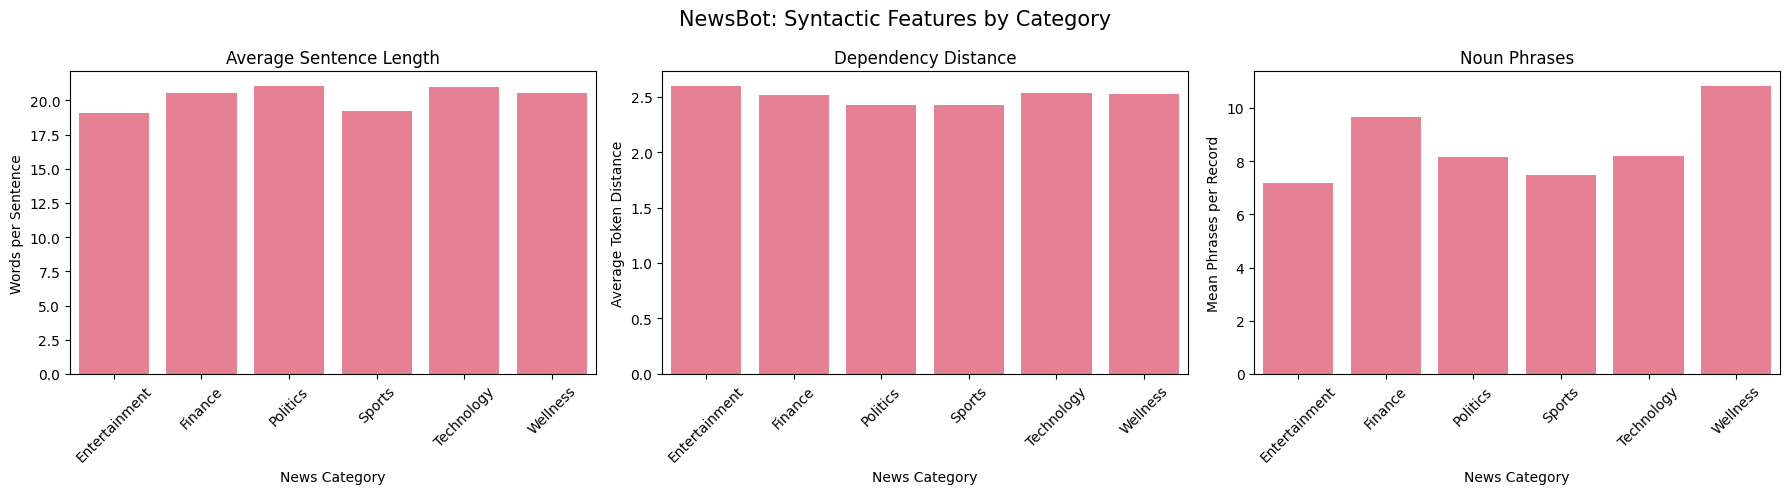


MOST COMMON DEPENDENCY RELATIONS

ENTERTAINMENT


,Dependency,Frequency,Per 100 Tokens
0,compound,1356,15.15
5,prep,850,9.49
6,pobj,817,9.13
4,nsubj,790,8.82
8,det,725,8.10



FINANCE


,Dependency,Frequency,Per 100 Tokens
44,compound,1253,10.51
50,prep,1177,9.87
51,pobj,1097,9.20
54,nsubj,1007,8.45
56,det,945,7.93



POLITICS


...

,Dependency,Frequency,Per 100 Tokens
135,compound,1577,16.74
147,prep,918,9.75
148,pobj,839,8.91
136,nsubj,766,8.13
141,det,752,7.98



TECHNOLOGY


,Dependency,Frequency,Per 100 Tokens
182,compound,1171,11.73
185,prep,965,9.66
186,pobj,941,9.42
189,nsubj,878,8.79
181,det,773,7.74



WELLNESS


,Dependency,Frequency,Per 100 Tokens
219,prep,1313,10.14
220,pobj,1186,9.16
223,nsubj,1171,9.04
230,det,996,7.69
228,compound,860,6.64


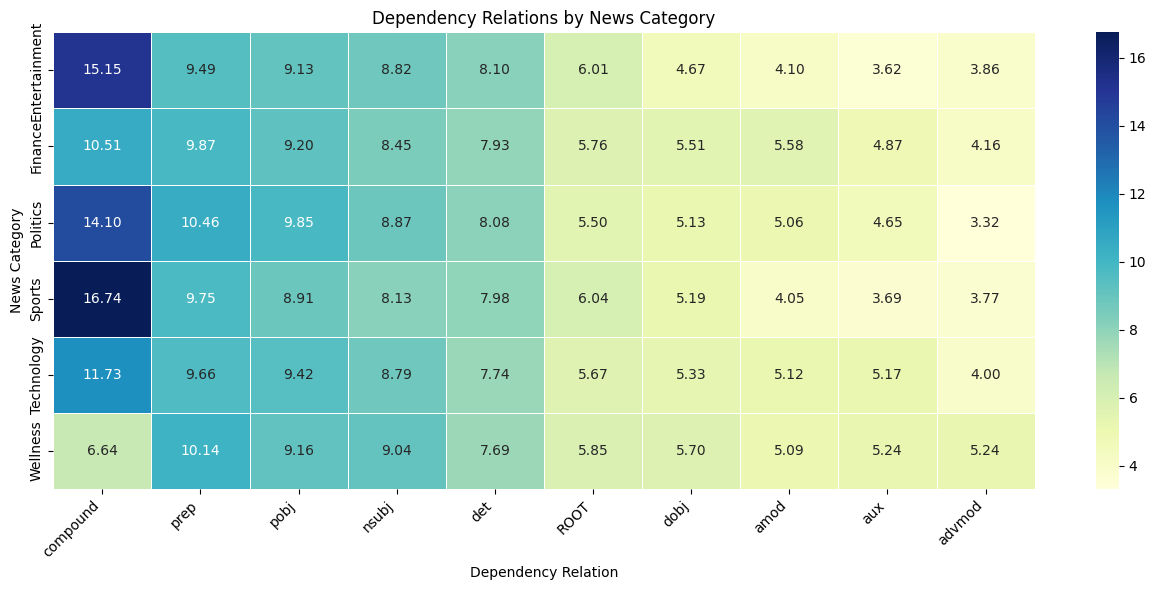


SUBJECT-VERB-OBJECT RELATIONSHIPS
Total extracted patterns: 1,924

Representative patterns by category:


,Article ID,Category,Subject,Verb,Object
0,1,Technology,you,create,project
1,3,Wellness,You,take,Approach
2,5,Sports,Ban,hurt,Efforts
3,6,Sports,game,reach,mark
4,6,Sports,Marriner,issue,five
5,7,Entertainment,We,spend,more
6,7,Entertainment,we,spend,time
7,9,Politics,judge,strike,law
8,11,Politics,Evidence,show,scrapbook
9,11,Politics,Gibson,show,scrapbook



SVO EXTRACTION COVERAGE


,Articles,Mean_SVO_Patterns,Records_With_SVO,SVO_Coverage_Percent
category,,,,
Entertainment,333,0.89,198,59.46
Finance,334,1.02,217,64.97
Politics,333,0.92,200,60.06
Sports,333,0.84,197,59.16
Technology,334,0.97,215,64.37
Wellness,333,1.13,216,64.86


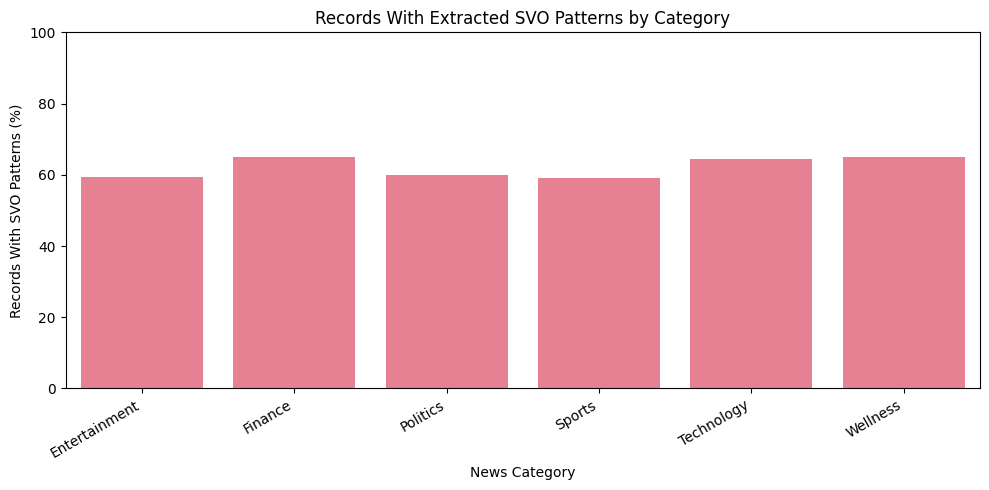


DEPENDENCY PARSE VISUALIZATION
Category: Entertainment
Sentence: Now that the much-anticipated "Behind the Candelabra" has tickled the ivories of critical acclaim, having seen praise at



OPTIONAL SYNTACTIC CLASSIFICATION FEATURES


,article_id,num_sentences,num_tokens,num_noun_phrases,num_svo_patterns,avg_sentence_length,avg_dependency_distance
0,1,1,52,13,1,52.0,3.764706
1,2,3,33,12,0,11.0,1.666667
2,3,1,30,8,1,30.0,2.689655
3,4,1,19,3,0,19.0,2.388889
4,5,2,36,9,1,18.0,2.970588



COMPARATIVE SYNTAX FINDINGS
Average sentence length: highest in Politics (21.07)
Dependency distance: highest in Entertainment (2.60)
Noun phrase count: highest in Wellness (10.83)
SVO pattern count: highest in Wellness (1.13)

Interpretation limitations:
- Dependency distance is a syntactic indicator, not a complete measure of writing complexity.
- SVO extraction uses simple grammatical rules and can miss complex relationships.
- Headlines and descriptions may be fragmented or grammatically incomplete.
- Extracted patterns are not fact-checked claims.

SYNTAX COMPARISON VALIDATION COMPLETE
Category comparisons: Passed
Dependency analysis: Passed
SVO relationship extraction: Passed
Classification feature preparation: Passed
Results exported successfully.


In [13]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 19 - DEPENDENCY VISUALIZATION AND SYNTAX COMPARISON
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df from Cell 10
# - nlp from Cell 4
# - syntactic_results and syntactic_df from Cell 18
# - pandas, NumPy, Matplotlib, Seaborn, Counter from Cell 4

from spacy import displacy

print("=" * 60)
print("NEWSBOT COMPARATIVE SYNTAX ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE PREVIOUS RESULTS
# ------------------------------------------------------------

assert len(syntactic_df) == len(df), (
    "Syntactic feature count does not match dataset."
)

assert len(syntactic_results) == len(df), (
    "Full syntactic results are incomplete."
)

assert syntactic_df["article_id"].tolist() == (
    df["article_id"].tolist()
), "Article IDs are misaligned."

categories = sorted(df["category"].unique())

print(f"Articles analyzed: {len(df):,}")
print(f"Categories: {len(categories)}")

# ------------------------------------------------------------
# 2. COMPARE SYNTACTIC COMPLEXITY BY CATEGORY
# ------------------------------------------------------------

syntax_metrics = [
    "num_sentences",
    "num_tokens",
    "num_noun_phrases",
    "num_svo_patterns",
    "avg_sentence_length",
    "avg_dependency_distance"
]

syntax_category_summary = (
    syntactic_df.groupby("category")[syntax_metrics]
    .agg(["mean", "median", "std"])
    .round(2)
)

print("\n" + "=" * 60)
print("SYNTACTIC COMPLEXITY BY CATEGORY")
print("=" * 60)

display(syntax_category_summary)

# Mean values for visual comparisons.
syntax_category_means = (
    syntactic_df.groupby("category")[syntax_metrics]
    .mean()
    .sort_index()
)

# ------------------------------------------------------------
# 3. VISUALIZE SYNTACTIC DIFFERENCES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

comparison_metrics = [
    ("avg_sentence_length", "Average Sentence Length",
     "Words per Sentence"),
    ("avg_dependency_distance", "Dependency Distance",
     "Average Token Distance"),
    ("num_noun_phrases", "Noun Phrases",
     "Mean Phrases per Record")
]

for ax, (metric, title, ylabel) in zip(
    axes, comparison_metrics
):

    sns.barplot(
        x=syntax_category_means.index,
        y=syntax_category_means[metric].values,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("News Category")
    ax.set_ylabel(ylabel)

    ax.tick_params(
        axis="x",
        rotation=45
    )

plt.suptitle(
    "NewsBot: Syntactic Features by Category",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. IDENTIFY DOMINANT DEPENDENCY RELATIONS
# ------------------------------------------------------------

# Use dependency counts calculated in Cell 18.
# Normalize to occurrences per 100 analyzed tokens,
# because categories contain texts of different lengths.

dependency_records = []

for category in categories:

    category_results = [
        item for item in syntactic_results
        if item["category"] == category
    ]

    dependency_counter = Counter()

    total_tokens = 0

    for result in category_results:

        dependency_counter.update(
            result["dependency_counts"]
        )

        total_tokens += result["num_tokens"]

    for dependency, count in dependency_counter.items():

        dependency_records.append({
            "Category": category,
            "Dependency": dependency,
            "Frequency": count,
            "Per 100 Tokens": (
                count / total_tokens * 100
                if total_tokens else 0
            )
        })

dependency_by_category_df = pd.DataFrame(
    dependency_records
)

print("\n" + "=" * 60)
print("MOST COMMON DEPENDENCY RELATIONS")
print("=" * 60)

for category in categories:

    category_dependencies = (
        dependency_by_category_df[
            dependency_by_category_df["Category"] == category
        ]
        .sort_values("Frequency", ascending=False)
        .head(5)
    )

    print(f"\n{category.upper()}")

    display(
        category_dependencies[
            ["Dependency", "Frequency", "Per 100 Tokens"]
        ].round(2)
    )

# ------------------------------------------------------------
# 5. VISUALIZE DEPENDENCY RELATIONSHIPS
# ------------------------------------------------------------

top_dependencies = (
    dependency_by_category_df
    .groupby("Dependency")["Frequency"]
    .sum()
    .nlargest(10)
    .index
    .tolist()
)

dependency_heatmap = (
    dependency_by_category_df[
        dependency_by_category_df["Dependency"].isin(
            top_dependencies
        )
    ]
    .pivot(
        index="Category",
        columns="Dependency",
        values="Per 100 Tokens"
    )
    .fillna(0)
)

dependency_heatmap = dependency_heatmap[
    top_dependencies
]

plt.figure(figsize=(13, 6))

sns.heatmap(
    dependency_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.4
)

plt.title(
    "Dependency Relations by News Category"
)

plt.xlabel("Dependency Relation")
plt.ylabel("News Category")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. EXTRACT SUBJECT-VERB-OBJECT EXAMPLES
# ------------------------------------------------------------

# These patterns were extracted in Cell 18.
# They are heuristic relationships rather than
# independently verified factual statements.

svo_records = []

for result in syntactic_results:

    for subject, verb, obj in result["svo_patterns"]:

        svo_records.append({
            "Article ID": result["article_id"],
            "Category": result["category"],
            "Subject": subject,
            "Verb": verb,
            "Object": obj
        })

svo_examples_df = pd.DataFrame(
    svo_records,
    columns=[
        "Article ID",
        "Category",
        "Subject",
        "Verb",
        "Object"
    ]
)

print("\n" + "=" * 60)
print("SUBJECT-VERB-OBJECT RELATIONSHIPS")
print("=" * 60)

print(
    f"Total extracted patterns: {len(svo_examples_df):,}"
)

if not svo_examples_df.empty:

    print("\nRepresentative patterns by category:")

    representative_svo = (
        svo_examples_df
        .groupby("Category", group_keys=False)
        .head(3)
    )

    display(representative_svo)

else:
    print(
        "No SVO patterns were extracted "
        "using the current heuristic."
    )

# ------------------------------------------------------------
# 7. COMPARE SVO EXTRACTION ACROSS CATEGORIES
# ------------------------------------------------------------

svo_category_summary = (
    syntactic_df.groupby("category")
    .agg(
        Articles=("article_id", "count"),
        Mean_SVO_Patterns=("num_svo_patterns", "mean"),
        Records_With_SVO=(
            "num_svo_patterns",
            lambda values: (values > 0).sum()
        )
    )
)

svo_category_summary["SVO_Coverage_Percent"] = (
    svo_category_summary["Records_With_SVO"] /
    svo_category_summary["Articles"] * 100
)

print("\n" + "=" * 60)
print("SVO EXTRACTION COVERAGE")
print("=" * 60)

display(svo_category_summary.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=svo_category_summary.index,
    y=svo_category_summary["SVO_Coverage_Percent"].values
)

plt.title(
    "Records With Extracted SVO Patterns by Category"
)

plt.xlabel("News Category")
plt.ylabel("Records With SVO Patterns (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. VISUALIZE A DEPENDENCY PARSE
# ------------------------------------------------------------

# Select a real HuffPost description containing
# a recognizable subject and direct object.
# Keeping the sentence short makes the diagram readable.

sample_sentence = None
sample_category = None

for category in categories:

    category_texts = df.loc[
        df["category"] == category,
        "content"
    ].dropna()

    for text in category_texts.head(40):

        candidate_doc = nlp(str(text))

        for sentence in candidate_doc.sents:

            sentence_tokens = [
                token for token in sentence
                if not token.is_punct and not token.is_space
            ]

            has_subject = any(
                token.dep_ in {"nsubj", "csubj"}
                for token in sentence
            )

            has_object = any(
                token.dep_ in {"dobj", "obj", "iobj"}
                for token in sentence
            )

            if (
                7 <= len(sentence_tokens) <= 20
                and has_subject
                and has_object
            ):

                sample_sentence = sentence.text.strip()
                sample_category = category
                break

        if sample_sentence is not None:
            break

    if sample_sentence is not None:
        break

print("\n" + "=" * 60)
print("DEPENDENCY PARSE VISUALIZATION")
print("=" * 60)

if sample_sentence is not None:

    print(f"Category: {sample_category}")
    print(f"Sentence: {sample_sentence}")

    sample_doc = nlp(sample_sentence)

    try:
        displacy.render(
            sample_doc,
            style="dep",
            jupyter=True,
            options={
                "compact": True,
                "distance": 90,
                "font": "Arial"
            }
        )

    except Exception as error:

        print(
            "Graphical rendering unavailable:",
            error
        )

        print("\nDependency relationships:")

        for token in sample_doc:

            if not token.is_punct and not token.is_space:

                print(
                    f"{token.text:<18} "
                    f"{token.dep_:<12} "
                    f"{token.head.text}"
                )

else:
    print(
        "No suitable short sentence was found "
        "for the dependency diagram."
    )

# ------------------------------------------------------------
# 9. PREPARE OPTIONAL CLASSIFICATION FEATURES
# ------------------------------------------------------------

# These numerical features could later be used
# alongside text representations.
#
# IMPORTANT:
# We are only preparing the features here.
# Model training, train/test splitting, and
# performance evaluation belong in Module 7.

syntax_features_for_model = (
    syntactic_df[
        ["article_id"] + syntax_metrics
    ]
    .copy()
)

print("\n" + "=" * 60)
print("OPTIONAL SYNTACTIC CLASSIFICATION FEATURES")
print("=" * 60)

display(syntax_features_for_model.head())

# ------------------------------------------------------------
# 10. EXPORT ANALYSIS RESULTS
# ------------------------------------------------------------

syntax_category_means.to_csv(
    "newsbot_syntax_category_summary.csv"
)

dependency_by_category_df.to_csv(
    "newsbot_dependency_category_analysis.csv",
    index=False
)

svo_examples_df.to_csv(
    "newsbot_svo_patterns.csv",
    index=False
)

syntax_features_for_model.to_csv(
    "newsbot_syntax_model_features.csv",
    index=False
)

# ------------------------------------------------------------
# 11. SUMMARY OF OBSERVED RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPARATIVE SYNTAX FINDINGS")
print("=" * 60)

for metric, label in [
    ("avg_sentence_length", "Average sentence length"),
    ("avg_dependency_distance", "Dependency distance"),
    ("num_noun_phrases", "Noun phrase count"),
    ("num_svo_patterns", "SVO pattern count")
]:

    ranking = syntax_category_means[
        metric
    ].sort_values(ascending=False)

    print(
        f"{label}: highest in {ranking.index[0]} "
        f"({ranking.iloc[0]:.2f})"
    )

print("\nInterpretation limitations:")
print(
    "- Dependency distance is a syntactic indicator, "
    "not a complete measure of writing complexity."
)

print(
    "- SVO extraction uses simple grammatical rules "
    "and can miss complex relationships."
)

print(
    "- Headlines and descriptions may be fragmented "
    "or grammatically incomplete."
)

print(
    "- Extracted patterns are not fact-checked claims."
)

# ------------------------------------------------------------
# 12. FINAL VALIDATION
# ------------------------------------------------------------

assert len(syntax_category_means) == 6
assert len(syntax_features_for_model) == 2000

assert (
    syntax_features_for_model["article_id"].tolist()
    == df["article_id"].tolist()
)

assert syntax_features_for_model[
    syntax_metrics
].notna().all().all()

print("\n" + "=" * 60)
print("SYNTAX COMPARISON VALIDATION COMPLETE")
print("=" * 60)

print("Category comparisons: Passed")
print("Dependency analysis: Passed")
print("SVO relationship extraction: Passed")
print("Classification feature preparation: Passed")
print("Results exported successfully.")


## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [14]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 21 - SENTIMENT ANALYSIS WITH VADER
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df from Cells 6 and 10
# - SentimentIntensityAnalyzer from Cell 4
# - VADER lexicon downloaded in Cell 3
# - pandas and NumPy from Cell 4

print("=" * 60)
print("NEWSBOT SENTIMENT ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. INITIALIZE VADER SENTIMENT ANALYZER
# ------------------------------------------------------------

sia = SentimentIntensityAnalyzer()

# Standard VADER compound-score thresholds.
POSITIVE_THRESHOLD = 0.05
NEGATIVE_THRESHOLD = -0.05

# ------------------------------------------------------------
# 2. DEFINE SENTIMENT ANALYSIS FUNCTION
# ------------------------------------------------------------

def analyze_sentiment(text):
    """
    Analyze emotional valence using VADER.

    VADER returns:
    - compound: normalized overall score (-1 to +1)
    - pos: positive component (0 to 1)
    - neu: neutral component (0 to 1)
    - neg: negative component (0 to 1)

    Sentiment classes:
    - Positive: compound >= 0.05
    - Negative: compound <= -0.05
    - Neutral: compound between these thresholds

    Missing or empty input receives a neutral result.
    """

    if text is None or pd.isna(text):
        return {
            "compound": 0.0,
            "pos": 0.0,
            "neu": 1.0,
            "neg": 0.0,
            "sentiment_label": "neutral"
        }

    text = str(text).strip()

    if not text:
        return {
            "compound": 0.0,
            "pos": 0.0,
            "neu": 1.0,
            "neg": 0.0,
            "sentiment_label": "neutral"
        }

    scores = sia.polarity_scores(text)

    compound = scores["compound"]

    if compound >= POSITIVE_THRESHOLD:
        label = "positive"

    elif compound <= NEGATIVE_THRESHOLD:
        label = "negative"

    else:
        label = "neutral"

    scores["sentiment_label"] = label

    return scores

# ------------------------------------------------------------
# 3. VALIDATE SENTIMENT FUNCTION
# ------------------------------------------------------------

test_sentences = [
    "The company reported excellent financial results.",
    "The company did not report good financial results.",
    "The company released its quarterly report.",
    "",
    None
]

print("\n" + "=" * 60)
print("SENTIMENT FUNCTION VALIDATION")
print("=" * 60)

for sentence in test_sentences:

    result = analyze_sentiment(sentence)

    print(f"\nText: {sentence}")
    print(f"Compound score: {result['compound']:.4f}")
    print(f"Sentiment label: {result['sentiment_label']}")

assert analyze_sentiment(None)["sentiment_label"] == "neutral"

assert analyze_sentiment("")["sentiment_label"] == "neutral"

# Confirm that VADER distinguishes a positive statement
# from a similar statement containing negation.

positive_test = analyze_sentiment(
    "The results were good."
)["compound"]

negation_test = analyze_sentiment(
    "The results were not good."
)["compound"]

assert positive_test > negation_test, (
    "VADER negation validation did not pass."
)

print("\nSentiment function validation: Passed")
print("Missing text handling: Passed")
print("Negation sensitivity: Passed")

# ------------------------------------------------------------
# 4. VERIFY DATASET COLUMNS
# ------------------------------------------------------------

required_columns = [
    "article_id",
    "category",
    "title",
    "content",
    "full_text"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# ------------------------------------------------------------
# 5. ANALYZE ALL 2,000 NEWS RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DATASET SENTIMENT PROCESSING")
print("=" * 60)

print(f"Analyzing {len(df):,} news records...")

sentiment_results = []

for row in df.itertuples(index=False):

    # Analyze original text rather than aggressively
    # preprocessed text to preserve sentiment cues.

    title_sentiment = analyze_sentiment(
        row.title
    )

    content_sentiment = analyze_sentiment(
        row.content
    )

    full_sentiment = analyze_sentiment(
        row.full_text
    )

    sentiment_results.append({
        "article_id": row.article_id,
        "category": row.category,

        "title_sentiment": title_sentiment["compound"],
        "title_label": title_sentiment["sentiment_label"],

        "content_sentiment": content_sentiment["compound"],
        "content_label": content_sentiment["sentiment_label"],

        "full_sentiment": full_sentiment["compound"],
        "full_label": full_sentiment["sentiment_label"],

        "pos_score": full_sentiment["pos"],
        "neu_score": full_sentiment["neu"],
        "neg_score": full_sentiment["neg"]
    })

sentiment_df = pd.DataFrame(
    sentiment_results
)

print("Sentiment analysis completed.")
print(f"Records analyzed: {len(sentiment_df):,}")

# ------------------------------------------------------------
# 6. COMPARE HEADLINES WITH DESCRIPTIONS
# ------------------------------------------------------------

# Identify records where headline and description
# receive different sentiment labels.

sentiment_df["title_content_disagreement"] = (
    sentiment_df["title_label"] !=
    sentiment_df["content_label"]
)

sentiment_df["title_content_score_difference"] = (
    sentiment_df["title_sentiment"] -
    sentiment_df["content_sentiment"]
).abs()

disagreement_count = (
    sentiment_df["title_content_disagreement"].sum()
)

disagreement_percentage = (
    disagreement_count / len(sentiment_df) * 100
)

print("\n" + "=" * 60)
print("HEADLINE VS. DESCRIPTION SENTIMENT")
print("=" * 60)

print(
    f"Records with different sentiment labels: "
    f"{disagreement_count:,}"
)

print(
    f"Percentage with different labels: "
    f"{disagreement_percentage:.2f}%"
)

print(
    "Note: A difference in labels does not necessarily "
    "indicate misleading or biased reporting."
)

# ------------------------------------------------------------
# 7. PRELIMINARY SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("OVERALL SENTIMENT DISTRIBUTION")
print("=" * 60)

sentiment_counts = (
    sentiment_df["full_label"]
    .value_counts()
    .reindex(
        ["positive", "neutral", "negative"],
        fill_value=0
    )
)

sentiment_percentages = (
    sentiment_counts / len(sentiment_df) * 100
)

sentiment_summary = pd.DataFrame({
    "Articles": sentiment_counts,
    "Percentage": sentiment_percentages.round(2)
})

display(sentiment_summary)

print(
    f"\nMean compound sentiment score: "
    f"{sentiment_df['full_sentiment'].mean():.4f}"
)

# ------------------------------------------------------------
# 8. INSPECT REPRESENTATIVE RESULTS
# ------------------------------------------------------------

preview_columns = [
    "article_id",
    "category",
    "title_sentiment",
    "title_label",
    "content_sentiment",
    "content_label",
    "full_sentiment",
    "full_label"
]

print("\n" + "=" * 60)
print("SAMPLE SENTIMENT RESULTS")
print("=" * 60)

display(
    sentiment_df[preview_columns]
    .head(10)
    .round(4)
)

# ------------------------------------------------------------
# 9. VALIDATE SENTIMENT OUTPUT
# ------------------------------------------------------------

assert len(sentiment_df) == len(df), (
    "Sentiment record count mismatch."
)

assert sentiment_df["article_id"].tolist() == (
    df["article_id"].tolist()
), "Article IDs are misaligned."

assert sentiment_df["category"].tolist() == (
    df["category"].tolist()
), "News categories are misaligned."

assert sentiment_df["full_sentiment"].between(
    -1, 1
).all(), "Compound scores outside the expected range."

assert sentiment_df["full_label"].isin(
    ["positive", "neutral", "negative"]
).all(), "Unexpected sentiment label detected."

assert sentiment_df[
    [
        "title_sentiment",
        "content_sentiment",
        "full_sentiment",
        "pos_score",
        "neu_score",
        "neg_score"
    ]
].notna().all().all(), (
    "Missing sentiment values detected."
)

# VADER component scores are rounded and should
# sum to approximately 1 for each record.

component_totals = sentiment_df[
    ["pos_score", "neu_score", "neg_score"]
].sum(axis=1)

assert np.allclose(
    component_totals.to_numpy(),
    1.0,
    atol=0.002
), "Sentiment components do not sum to approximately 1."

# ------------------------------------------------------------
# 10. EXPORT SENTIMENT RESULTS
# ------------------------------------------------------------

sentiment_df.to_csv(
    "newsbot_sentiment_features.csv",
    index=False
)

print("\n" + "=" * 60)
print("SENTIMENT ANALYSIS VALIDATION COMPLETE")
print("=" * 60)

print("VADER sentiment scoring: Passed")
print("Headline analysis: Passed")
print("Description analysis: Passed")
print("Combined text analysis: Passed")
print("Dataset alignment: Passed")
print("Results exported: newsbot_sentiment_features.csv")


NEWSBOT SENTIMENT ANALYSIS

SENTIMENT FUNCTION VALIDATION

Text: The company reported excellent financial results.
Compound score: 0.5719
Sentiment label: positive

Text: The company did not report good financial results.
Compound score: -0.3412
Sentiment label: negative

Text: The company released its quarterly report.
Compound score: 0.0000
Sentiment label: neutral

Text: 
Compound score: 0.0000
Sentiment label: neutral

Text: None
Compound score: 0.0000
Sentiment label: neutral

Sentiment function validation: Passed
Missing text handling: Passed
Negation sensitivity: Passed

DATASET SENTIMENT PROCESSING
Analyzing 2,000 news records...
Sentiment analysis completed.
Records analyzed: 2,000

HEADLINE VS. DESCRIPTION SENTIMENT
Records with different sentiment labels: 1,164
Percentage with different labels: 58.20%
Note: A difference in labels does not necessarily indicate misleading or biased reporting.

OVERALL SENTIMENT DISTRIBUTION


,Articles,Percentage
full_label,,
positive,1028,51.4
neutral,270,13.5
negative,702,35.1



Mean compound sentiment score: 0.0962

SAMPLE SENTIMENT RESULTS


,article_id,category,title_sentiment,title_label,content_sentiment,content_label,full_sentiment,full_label
0,1,Technology,0.5563,positive,0.9217,positive,0.9501,positive
1,2,Finance,-0.4576,negative,-0.6808,negative,-0.8221,negative
2,3,Wellness,0.0000,neutral,0.0516,positive,0.0516,positive
3,4,Entertainment,0.7430,positive,0.0000,neutral,0.7430,positive
4,5,Sports,-0.7906,negative,-0.2960,negative,-0.8481,negative
5,6,Sports,0.5859,positive,0.1027,positive,0.6369,positive
6,7,Entertainment,0.3182,positive,0.4019,positive,0.6124,positive
7,8,Technology,-0.3182,negative,0.4574,positive,0.1759,positive
8,9,Politics,-0.7269,negative,0.2023,positive,-0.6486,negative
9,10,Sports,0.5994,positive,0.6369,positive,0.8442,positive



SENTIMENT ANALYSIS VALIDATION COMPLETE
VADER sentiment scoring: Passed
Headline analysis: Passed
Description analysis: Passed
Combined text analysis: Passed
Dataset alignment: Passed
Results exported: newsbot_sentiment_features.csv


NEWSBOT SENTIMENT ANALYSIS BY CATEGORY
Articles analyzed: 2,000
News categories: 6

CATEGORY SENTIMENT STATISTICS


,Articles,Mean_Compound,Median_Compound,Std_Compound,Min_Compound,Max_Compound,Mean_Positive,Mean_Neutral,Mean_Negative
category,,,,,,,,,
Entertainment,333,0.1556,0.2458,0.5242,-0.9517,0.9755,0.1231,0.8037,0.0732
Finance,334,0.1111,0.1406,0.5599,-0.9590,0.9771,0.1059,0.8103,0.0838
Politics,333,-0.0372,0.0000,0.5182,-0.9481,0.9403,0.0896,0.8101,0.1003
Sports,333,0.0643,0.0000,0.5400,-0.9324,0.9552,0.1061,0.8041,0.0898
Technology,334,0.0742,0.0129,0.4912,-0.9423,0.9501,0.0997,0.8217,0.0786
Wellness,333,0.2095,0.3261,0.5784,-0.9638,0.9894,0.1400,0.7753,0.0846



SENTIMENT COUNTS BY CATEGORY


full_label,positive,neutral,negative
category,,,
Entertainment,184,54,95
Finance,178,39,117
Politics,133,49,151
Sports,161,50,122
Technology,164,57,113
Wellness,208,21,104



SENTIMENT PERCENTAGES BY CATEGORY:


full_label,positive,neutral,negative
category,,,
Entertainment,55.26,16.22,28.53
Finance,53.29,11.68,35.03
Politics,39.94,14.71,45.35
Sports,48.35,15.02,36.64
Technology,49.10,17.07,33.83
Wellness,62.46,6.31,31.23



HEADLINE VS. DESCRIPTION ANALYSIS


,Articles,Mean_Headline_Score,Mean_Description_Score,Mean_Combined_Score,Disagreement_Count,Mean_Absolute_Score_Difference,Disagreement_Percent
category,,,,,,,
Entertainment,333,0.027,0.142,0.156,180,0.359,54.054
Finance,334,-0.007,0.137,0.111,184,0.402,55.090
Politics,333,-0.074,0.029,-0.037,202,0.409,60.661
Sports,333,0.016,0.069,0.064,198,0.399,59.459
Technology,334,-0.022,0.093,0.074,204,0.398,61.078
Wellness,333,0.067,0.194,0.210,196,0.472,58.859


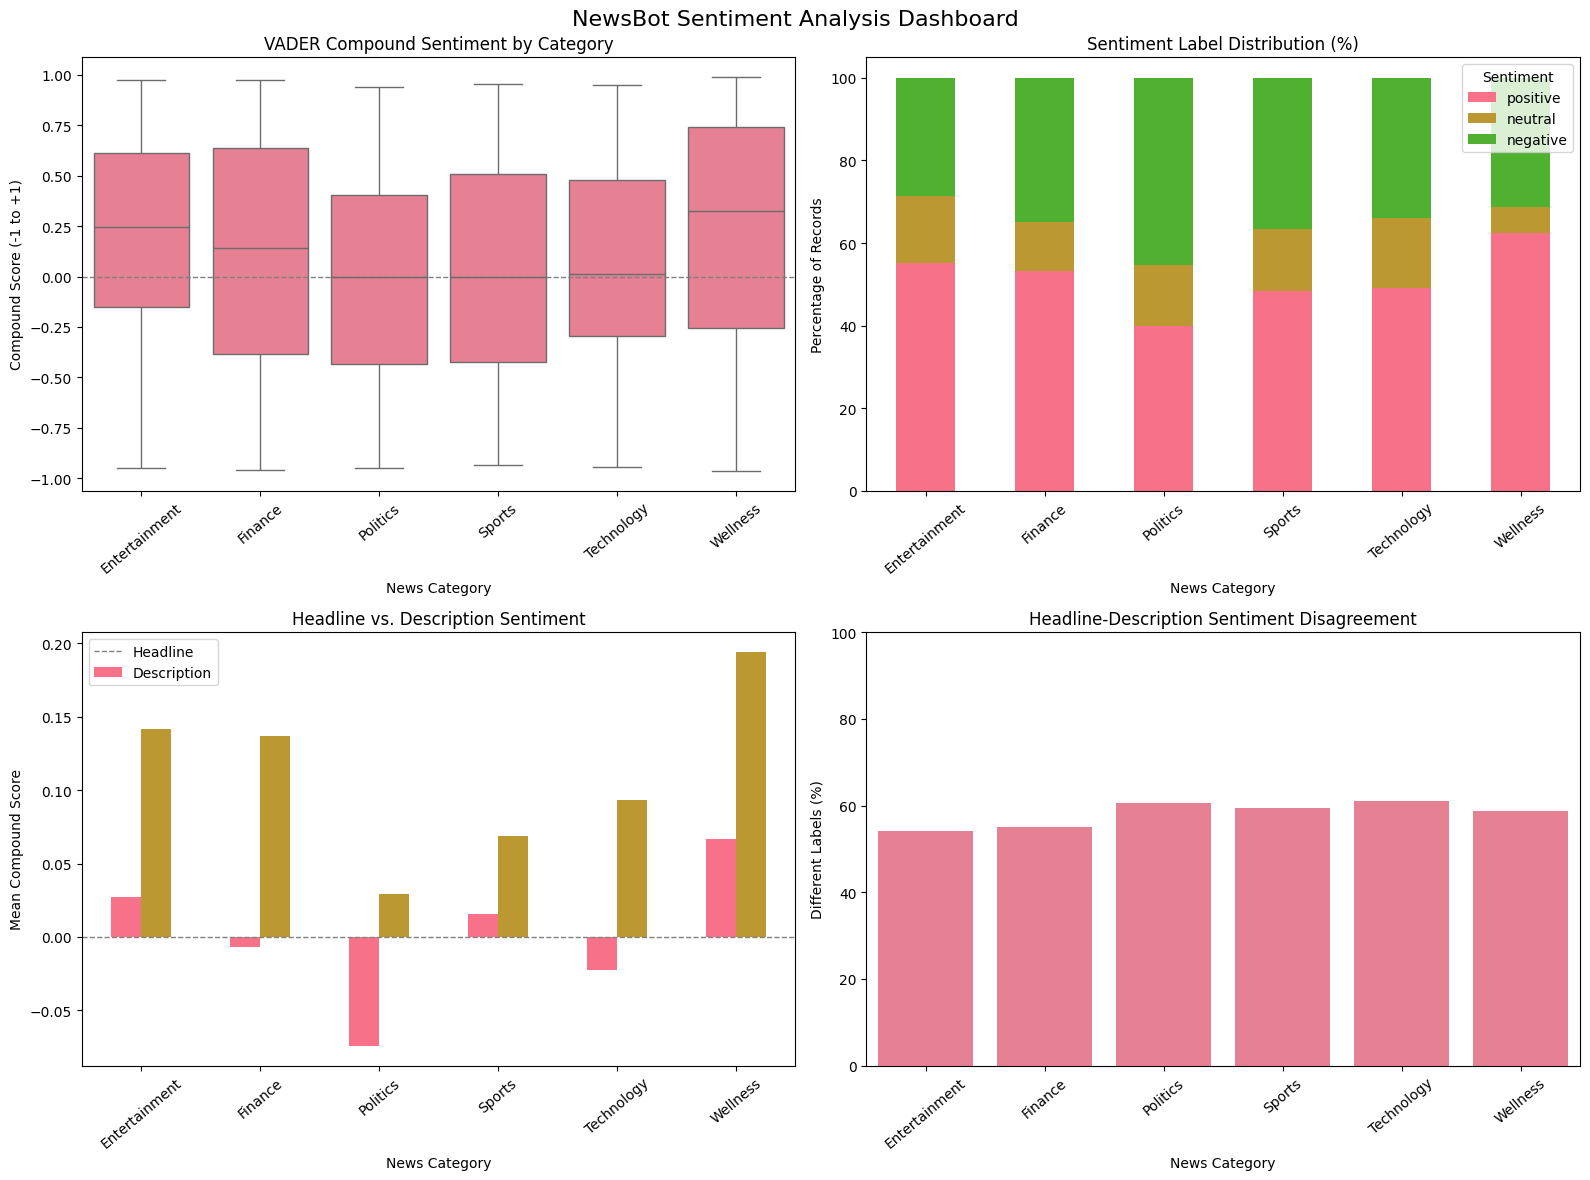

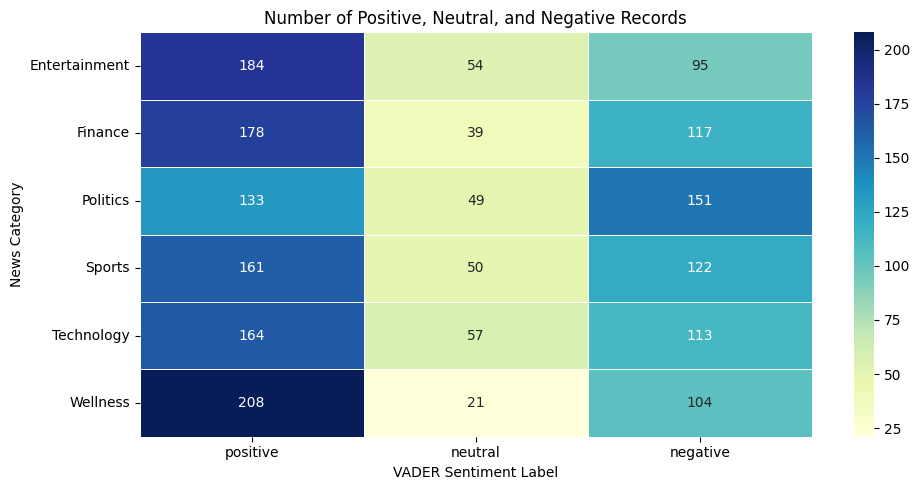


EXAMPLES OF SENTIMENT DISAGREEMENT


,category,title,content,title_label,content_label,title_sentiment,content_sentiment
687,Wellness,"Sun May Lower Blood Pressure, But Skin Cancer ...",And while it appears that going out in the sun...,negative,positive,-0.9161,0.8367
768,Finance,The Entrepreneur and Fear: An Argument for Ent...,The paralysis of financial fear can be life-de...,negative,positive,-0.6908,0.8945
990,Politics,The Politics of War,The U.S. has the most powerful military in the...,negative,positive,-0.5994,0.9527
721,Wellness,For the Love of My Sister,"Laurie and I did goof around together, but I w...",positive,negative,0.6369,-0.8894
490,Wellness,Dental Crisis Looms for California's Children,California needs real leadership in oral healt...,negative,positive,-0.6908,0.8270



Interpret these examples carefully. Different sentiment labels do not prove that a headline is misleading or biased.

SENTIMENT HYPOTHESIS EVALUATION

HIGHEST MEAN COMPOUND SENTIMENT:
Wellness: 0.2095

LOWEST MEAN COMPOUND SENTIMENT:
Politics: -0.0372

HIGHEST POSITIVE-LABEL PERCENTAGE:
Wellness: 62.46%

HIGHEST NEGATIVE-LABEL PERCENTAGE:
Politics: 45.35%

SPORTS VS. POLITICS:
Sports mean score: 0.0643
Politics mean score: -0.0372
Sports positive labels: 48.35%
Politics negative labels: 45.35%

These results provide descriptive evidence for evaluating the hypothesis, not proof of an inherent emotional quality of a category.

OPTIONAL CLASSIFICATION FEATURES


,article_id,title_sentiment,content_sentiment,full_sentiment,pos_score,neu_score,neg_score
0,1,0.5563,0.9217,0.9501,0.288,0.712,0.000
1,2,-0.4576,-0.6808,-0.8221,0.000,0.759,0.241
2,3,0.0000,0.0516,0.0516,0.099,0.808,0.093
3,4,0.7430,0.0000,0.7430,0.295,0.633,0.072
4,5,-0.7906,-0.2960,-0.8481,0.000,0.777,0.223



SENTIMENT ANALYSIS LIMITATIONS
1. VADER measures estimated text sentiment, not factual accuracy or journalistic bias.
2. Headlines and descriptions differ in length, which can influence VADER scores.
3. Irony, sarcasm, domain terminology, and context can produce incorrect sentiment scores.
4. Positive, neutral, and negative are sentiment labels, not detailed emotional categories.
5. Findings reflect our balanced 2,000-record sample, not all news published by HuffPost.

SENTIMENT CATEGORY ANALYSIS VALIDATION COMPLETE
Category statistics: Passed
Sentiment distributions: Passed
Headline-description comparison: Passed
Hypothesis evaluation: Passed
Classification feature preparation: Passed
Results exported successfully.


In [15]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 22 - CATEGORY SENTIMENT ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - sentiment_df from Cell 21
# - df from Cell 10
# - pandas, NumPy, Matplotlib, Seaborn from Cell 4

print("=" * 60)
print("NEWSBOT SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE SENTIMENT RESULTS
# ------------------------------------------------------------

required_columns = [
    "article_id",
    "category",
    "title_sentiment",
    "title_label",
    "content_sentiment",
    "content_label",
    "full_sentiment",
    "full_label",
    "pos_score",
    "neu_score",
    "neg_score",
    "title_content_disagreement"
]

missing_columns = [
    column for column in required_columns
    if column not in sentiment_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing sentiment columns: {missing_columns}"
    )

assert len(sentiment_df) == len(df), (
    "Sentiment and news datasets have different lengths."
)

assert sentiment_df["article_id"].tolist() == (
    df["article_id"].tolist()
), "Article IDs are not aligned."

categories = sorted(sentiment_df["category"].unique())

sentiment_order = [
    "positive",
    "neutral",
    "negative"
]

print(f"Articles analyzed: {len(sentiment_df):,}")
print(f"News categories: {len(categories)}")

# ------------------------------------------------------------
# 2. CALCULATE CATEGORY SENTIMENT STATISTICS
# ------------------------------------------------------------

sentiment_by_category = (
    sentiment_df.groupby("category")
    .agg(
        Articles=("article_id", "count"),
        Mean_Compound=("full_sentiment", "mean"),
        Median_Compound=("full_sentiment", "median"),
        Std_Compound=("full_sentiment", "std"),
        Min_Compound=("full_sentiment", "min"),
        Max_Compound=("full_sentiment", "max"),
        Mean_Positive=("pos_score", "mean"),
        Mean_Neutral=("neu_score", "mean"),
        Mean_Negative=("neg_score", "mean")
    )
    .sort_index()
)

print("\n" + "=" * 60)
print("CATEGORY SENTIMENT STATISTICS")
print("=" * 60)

display(sentiment_by_category.round(4))

# ------------------------------------------------------------
# 3. SENTIMENT LABEL DISTRIBUTION
# ------------------------------------------------------------

sentiment_dist = pd.crosstab(
    sentiment_df["category"],
    sentiment_df["full_label"]
).reindex(
    index=categories,
    columns=sentiment_order,
    fill_value=0
)

sentiment_dist_pct = (
    sentiment_dist.div(
        sentiment_dist.sum(axis=1),
        axis=0
    ) * 100
)

print("\n" + "=" * 60)
print("SENTIMENT COUNTS BY CATEGORY")
print("=" * 60)

display(sentiment_dist)

print("\nSENTIMENT PERCENTAGES BY CATEGORY:")
display(sentiment_dist_pct.round(2))

# ------------------------------------------------------------
# 4. HEADLINE VS. DESCRIPTION COMPARISON
# ------------------------------------------------------------

headline_description_summary = (
    sentiment_df.groupby("category")
    .agg(
        Articles=("article_id", "count"),
        Mean_Headline_Score=(
            "title_sentiment", "mean"
        ),
        Mean_Description_Score=(
            "content_sentiment", "mean"
        ),
        Mean_Combined_Score=(
            "full_sentiment", "mean"
        ),
        Disagreement_Count=(
            "title_content_disagreement", "sum"
        ),
        Mean_Absolute_Score_Difference=(
            "title_content_score_difference", "mean"
        )
    )
)

headline_description_summary[
    "Disagreement_Percent"
] = (
    headline_description_summary["Disagreement_Count"] /
    headline_description_summary["Articles"] * 100
)

print("\n" + "=" * 60)
print("HEADLINE VS. DESCRIPTION ANALYSIS")
print("=" * 60)

display(
    headline_description_summary.round(3)
)

# ------------------------------------------------------------
# 5. SENTIMENT VISUALIZATIONS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 12)
)

# A. Compound sentiment variation by category

sns.boxplot(
    data=sentiment_df,
    x="category",
    y="full_sentiment",
    order=categories,
    ax=axes[0, 0]
)

axes[0, 0].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

axes[0, 0].set_title(
    "VADER Compound Sentiment by Category"
)

axes[0, 0].set_xlabel("News Category")
axes[0, 0].set_ylabel("Compound Score (-1 to +1)")
axes[0, 0].tick_params(axis="x", rotation=40)

# B. Percentage of sentiment classes

sentiment_dist_pct.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Sentiment Label Distribution (%)"
)

axes[0, 1].set_xlabel("News Category")
axes[0, 1].set_ylabel("Percentage of Records")
axes[0, 1].tick_params(axis="x", rotation=40)
axes[0, 1].legend(
    title="Sentiment",
    loc="upper right"
)

# C. Headline vs. description mean scores

comparison_scores = (
    headline_description_summary[
        [
            "Mean_Headline_Score",
            "Mean_Description_Score"
        ]
    ]
)

comparison_scores.plot(
    kind="bar",
    ax=axes[1, 0]
)

axes[1, 0].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

axes[1, 0].set_title(
    "Headline vs. Description Sentiment"
)

axes[1, 0].set_xlabel("News Category")
axes[1, 0].set_ylabel("Mean Compound Score")
axes[1, 0].tick_params(axis="x", rotation=40)
axes[1, 0].legend(
    ["Headline", "Description"],
    loc="best"
)

# D. Percentage of headline-description disagreements

sns.barplot(
    x=headline_description_summary.index,
    y=headline_description_summary[
        "Disagreement_Percent"
    ].values,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Headline-Description Sentiment Disagreement"
)

axes[1, 1].set_xlabel("News Category")
axes[1, 1].set_ylabel("Different Labels (%)")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].tick_params(axis="x", rotation=40)

plt.suptitle(
    "NewsBot Sentiment Analysis Dashboard",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. SENTIMENT COUNT HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.heatmap(
    sentiment_dist,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.4
)

plt.title(
    "Number of Positive, Neutral, and Negative Records"
)

plt.xlabel("VADER Sentiment Label")
plt.ylabel("News Category")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. EXAMINE SENTIMENT DISAGREEMENT EXAMPLES
# ------------------------------------------------------------

# Join the original article text to sentiment results.
# This is for human interpretation only.

sentiment_examples = sentiment_df.merge(
    df[
        ["article_id", "title", "content"]
    ],
    on="article_id",
    how="left",
    validate="one_to_one"
)

# Find the most pronounced score differences.
disagreement_examples = (
    sentiment_examples[
        sentiment_examples["title_content_disagreement"]
    ]
    .sort_values(
        "title_content_score_difference",
        ascending=False
    )
    .head(5)
)

print("\n" + "=" * 60)
print("EXAMPLES OF SENTIMENT DISAGREEMENT")
print("=" * 60)

display(
    disagreement_examples[
        [
            "category",
            "title",
            "content",
            "title_label",
            "content_label",
            "title_sentiment",
            "content_sentiment"
        ]
    ]
)

print(
    "\nInterpret these examples carefully. "
    "Different sentiment labels do not prove "
    "that a headline is misleading or biased."
)

# ------------------------------------------------------------
# 8. EVALUATE THE PROFESSOR'S HYPOTHESIS
# ------------------------------------------------------------

# The original hypothesis suggests Sports may
# be more positive and Politics more negative.

mean_sentiment_ranking = (
    sentiment_by_category["Mean_Compound"]
    .sort_values(ascending=False)
)

positive_percentage_ranking = (
    sentiment_dist_pct["positive"]
    .sort_values(ascending=False)
)

negative_percentage_ranking = (
    sentiment_dist_pct["negative"]
    .sort_values(ascending=False)
)

print("\n" + "=" * 60)
print("SENTIMENT HYPOTHESIS EVALUATION")
print("=" * 60)

print("\nHIGHEST MEAN COMPOUND SENTIMENT:")
print(
    f"{mean_sentiment_ranking.index[0]}: "
    f"{mean_sentiment_ranking.iloc[0]:.4f}"
)

print("\nLOWEST MEAN COMPOUND SENTIMENT:")
print(
    f"{mean_sentiment_ranking.index[-1]}: "
    f"{mean_sentiment_ranking.iloc[-1]:.4f}"
)

print("\nHIGHEST POSITIVE-LABEL PERCENTAGE:")
print(
    f"{positive_percentage_ranking.index[0]}: "
    f"{positive_percentage_ranking.iloc[0]:.2f}%"
)

print("\nHIGHEST NEGATIVE-LABEL PERCENTAGE:")
print(
    f"{negative_percentage_ranking.index[0]}: "
    f"{negative_percentage_ranking.iloc[0]:.2f}%"
)

print("\nSPORTS VS. POLITICS:")

print(
    f"Sports mean score: "
    f"{sentiment_by_category.loc['Sports', 'Mean_Compound']:.4f}"
)

print(
    f"Politics mean score: "
    f"{sentiment_by_category.loc['Politics', 'Mean_Compound']:.4f}"
)

print(
    f"Sports positive labels: "
    f"{sentiment_dist_pct.loc['Sports', 'positive']:.2f}%"
)

print(
    f"Politics negative labels: "
    f"{sentiment_dist_pct.loc['Politics', 'negative']:.2f}%"
)

print(
    "\nThese results provide descriptive evidence "
    "for evaluating the hypothesis, not proof "
    "of an inherent emotional quality of a category."
)

# ------------------------------------------------------------
# 9. OPTIONAL SENTIMENT FEATURES FOR CLASSIFICATION
# ------------------------------------------------------------

# VADER scores are calculated independently for
# each article. We can later test whether these
# features improve news classification.
#
# Do not fit a scaler or other learned
# preprocessing transformation on the test set.
# That belongs inside the training pipeline.

sentiment_features_for_model = (
    sentiment_df[
        [
            "article_id",
            "title_sentiment",
            "content_sentiment",
            "full_sentiment",
            "pos_score",
            "neu_score",
            "neg_score"
        ]
    ]
    .copy()
)

print("\n" + "=" * 60)
print("OPTIONAL CLASSIFICATION FEATURES")
print("=" * 60)

display(
    sentiment_features_for_model.head()
)

# ------------------------------------------------------------
# 10. EXPORT RESULTS
# ------------------------------------------------------------

sentiment_by_category.to_csv(
    "newsbot_sentiment_category_statistics.csv"
)

sentiment_dist_pct.to_csv(
    "newsbot_sentiment_category_percentages.csv"
)

headline_description_summary.to_csv(
    "newsbot_headline_description_sentiment.csv"
)

sentiment_features_for_model.to_csv(
    "newsbot_sentiment_model_features.csv",
    index=False
)

# ------------------------------------------------------------
# 11. ANALYSIS LIMITATIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SENTIMENT ANALYSIS LIMITATIONS")
print("=" * 60)

print(
    "1. VADER measures estimated text sentiment, "
    "not factual accuracy or journalistic bias."
)

print(
    "2. Headlines and descriptions differ in length, "
    "which can influence VADER scores."
)

print(
    "3. Irony, sarcasm, domain terminology, and "
    "context can produce incorrect sentiment scores."
)

print(
    "4. Positive, neutral, and negative are sentiment "
    "labels, not detailed emotional categories."
)

print(
    "5. Findings reflect our balanced 2,000-record "
    "sample, not all news published by HuffPost."
)

# ------------------------------------------------------------
# 12. FINAL VALIDATION
# ------------------------------------------------------------

assert len(sentiment_by_category) == 6, (
    "Expected six news categories."
)

assert sentiment_dist.to_numpy().sum() == len(df), (
    "Sentiment category totals do not match dataset."
)

assert len(sentiment_features_for_model) == len(df), (
    "Classification feature count mismatch."
)

assert sentiment_features_for_model[
    "article_id"
].tolist() == df["article_id"].tolist(), (
    "Sentiment feature IDs are misaligned."
)

assert np.allclose(
    sentiment_dist_pct.sum(axis=1).values,
    100.0
), "Sentiment percentages do not sum to 100."

print("\n" + "=" * 60)
print("SENTIMENT CATEGORY ANALYSIS VALIDATION COMPLETE")
print("=" * 60)

print("Category statistics: Passed")
print("Sentiment distributions: Passed")
print("Headline-description comparison: Passed")
print("Hypothesis evaluation: Passed")
print("Classification feature preparation: Passed")
print("Results exported successfully.")


## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [16]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 24 - CLASSIFICATION FEATURE ENGINEERING
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - df from Cells 6 and 10
# - sentiment_df from Cell 21
# - pos_df from Cell 15
# - syntactic_df from Cell 18
# - train_test_split from Cell 4

print("=" * 60)
print("NEWSBOT CLASSIFICATION FEATURE ENGINEERING")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE REQUIRED DATASETS
# ------------------------------------------------------------

source_tables = {
    "News": df,
    "Sentiment": sentiment_df,
    "POS": pos_df,
    "Syntax": syntactic_df
}

for table_name, table in source_tables.items():

    assert "article_id" in table.columns, (
        f"{table_name} is missing article_id."
    )

    assert len(table) == 2000, (
        f"{table_name} must contain 2,000 records."
    )

    assert table["article_id"].is_unique, (
        f"{table_name} contains duplicate article IDs."
    )

    assert set(table["article_id"]) == set(df["article_id"]), (
        f"{table_name} article IDs do not match NewsBot."
    )

print("Source dataset validation: Passed")

# ------------------------------------------------------------
# 2. PREPARE TEXT FEATURES
# ------------------------------------------------------------

# Use the preprocessed text from Module 2.
# Classification TF-IDF will be fitted after splitting,
# not reused from the exploratory analysis in Cell 12.

classification_features = df[
    ["article_id", "full_text_processed"]
].copy()

assert classification_features[
    "full_text_processed"
].fillna("").str.strip().ne("").all(), (
    "Empty classification text detected."
)

# ------------------------------------------------------------
# 3. PREPARE SENTIMENT FEATURES
# ------------------------------------------------------------

# VADER scores are calculated independently for
# each article without learning from category labels.
#
# Convert compound scores from [-1, 1] to [0, 1].
# This also supports nonnegative classifiers.

sentiment_extra = sentiment_df[
    [
        "article_id",
        "title_sentiment",
        "content_sentiment",
        "full_sentiment",
        "pos_score",
        "neu_score",
        "neg_score"
    ]
].copy()

sentiment_extra["sentiment_title"] = (
    sentiment_extra["title_sentiment"] + 1
) / 2

sentiment_extra["sentiment_description"] = (
    sentiment_extra["content_sentiment"] + 1
) / 2

sentiment_extra["sentiment_combined"] = (
    sentiment_extra["full_sentiment"] + 1
) / 2

sentiment_extra = sentiment_extra.rename(
    columns={
        "pos_score": "sentiment_positive",
        "neu_score": "sentiment_neutral",
        "neg_score": "sentiment_negative"
    }
)

sentiment_columns = [
    "sentiment_title",
    "sentiment_description",
    "sentiment_combined",
    "sentiment_positive",
    "sentiment_neutral",
    "sentiment_negative"
]

classification_features = classification_features.merge(
    sentiment_extra[
        ["article_id"] + sentiment_columns
    ],
    on="article_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. PREPARE TEXT LENGTH FEATURES
# ------------------------------------------------------------

# Use log1p to reduce the influence of unusually
# long news records without losing length information.

length_extra = df[["article_id"]].copy()

length_extra["length_characters"] = np.log1p(
    df["full_text"].str.len().to_numpy()
)

length_extra["length_words"] = np.log1p(
    df["full_text"].str.split().str.len().to_numpy()
)

length_extra["length_headline"] = np.log1p(
    df["title"].str.len().to_numpy()
)

length_columns = [
    "length_characters",
    "length_words",
    "length_headline"
]

classification_features = classification_features.merge(
    length_extra,
    on="article_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 5. PREPARE POS FEATURES
# ------------------------------------------------------------

# Combine related POS tags into grammatical groups.
# Cell 15 already converted them into proportions.

pos_groups = {
    "pos_common_nouns": ["NN", "NNS"],
    "pos_proper_nouns": ["NNP", "NNPS"],
    "pos_verbs": [
        "VB", "VBD", "VBG",
        "VBN", "VBP", "VBZ"
    ],
    "pos_adjectives": ["JJ", "JJR", "JJS"],
    "pos_adverbs": ["RB", "RBR", "RBS"],
    "pos_numbers": ["CD"]
}

pos_extra = pos_df[["article_id"]].copy()

for group_name, tags in pos_groups.items():

    available_tags = [
        tag for tag in tags
        if tag in pos_df.columns
    ]

    if available_tags:

        pos_extra[group_name] = (
            pos_df[available_tags]
            .sum(axis=1)
            .to_numpy()
        )

    else:

        pos_extra[group_name] = 0.0

pos_columns = list(pos_groups.keys())

classification_features = classification_features.merge(
    pos_extra,
    on="article_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 6. PREPARE SYNTACTIC FEATURES
# ------------------------------------------------------------

# These represent observable grammatical structure.
# They do not establish factual or semantic accuracy.

syntax_columns = [
    "num_sentences",
    "num_svo_patterns",
    "avg_sentence_length",
    "avg_dependency_distance"
]

syntax_extra = syntactic_df[
    ["article_id"] + syntax_columns
].copy()

# Reduce the influence of extreme values in count-based
# and sentence-length features.

for column in [
    "num_sentences",
    "num_svo_patterns",
    "avg_sentence_length"
]:

    syntax_extra[column] = np.log1p(
        syntax_extra[column]
    )

classification_features = classification_features.merge(
    syntax_extra,
    on="article_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 7. DEFINE FINAL FEATURE CONFIGURATION
# ------------------------------------------------------------

numeric_feature_columns = (
    sentiment_columns
    + length_columns
    + pos_columns
    + syntax_columns
)

text_feature_column = "full_text_processed"

classification_input_columns = (
    [text_feature_column]
    + numeric_feature_columns
)

# Ensure numerical features are valid.
numeric_values = classification_features[
    numeric_feature_columns
].to_numpy(dtype=np.float32)

assert np.isfinite(numeric_values).all(), (
    "Invalid numerical classification features."
)

assert (numeric_values >= 0).all(), (
    "Negative feature values detected."
)

assert len(classification_features) == len(df), (
    "Feature engineering changed dataset size."
)

assert classification_features["article_id"].tolist() == (
    df["article_id"].tolist()
), "Article order changed during feature engineering."

# ------------------------------------------------------------
# 8. DEFINE TARGET LABELS
# ------------------------------------------------------------

y = df["category"].copy()

class_names = sorted(y.unique())

assert len(class_names) == 6, (
    "Expected six NewsBot classification labels."
)

# ------------------------------------------------------------
# 9. CREATE STRATIFIED TRAIN/TEST SPLIT
# ------------------------------------------------------------

# IMPORTANT:
# Split raw features before fitting TF-IDF or scaling.
#
# The test set remains separate during model training
# and hyperparameter selection.

X_train, X_test, y_train, y_test = train_test_split(
    classification_features[
        classification_input_columns
    ],
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Retain article IDs for later error analysis.
train_article_ids = classification_features.loc[
    X_train.index,
    "article_id"
].to_numpy()

test_article_ids = classification_features.loc[
    X_test.index,
    "article_id"
].to_numpy()

# ------------------------------------------------------------
# 10. VERIFY TRAIN/TEST INTEGRITY
# ------------------------------------------------------------

assert len(X_train) == 1600
assert len(X_test) == 400

assert set(train_article_ids).isdisjoint(
    set(test_article_ids)
), "Training and testing article IDs overlap."

assert X_train[
    numeric_feature_columns
].notna().all().all(), (
    "Missing training features detected."
)

assert X_test[
    numeric_feature_columns
].notna().all().all(), (
    "Missing testing features detected."
)

assert X_train[text_feature_column].str.strip().ne("").all()
assert X_test[text_feature_column].str.strip().ne("").all()

# ------------------------------------------------------------
# 11. REPORT FEATURE CONFIGURATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION FEATURE CONFIGURATION")
print("=" * 60)

print(f"Total records: {len(df):,}")
print(f"News categories: {len(class_names)}")

print("\nCategories:")
for category in class_names:
    print(f"  - {category}")

print("\nFeature groups:")
print("  1. TF-IDF text representation")
print(f"  2. Sentiment features: {len(sentiment_columns)}")
print(f"  3. Text length features: {len(length_columns)}")
print(f"  4. POS features: {len(pos_columns)}")
print(f"  5. Syntax features: {len(syntax_columns)}")

print(
    f"\nAdditional numerical features: "
    f"{len(numeric_feature_columns)}"
)

print("\nModel configurations to compare:")
print("  Baseline: TF-IDF")
print("  Enhanced: TF-IDF + numerical NLP features")

# ------------------------------------------------------------
# 12. REPORT DATA SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TRAIN/TEST SPLIT")
print("=" * 60)

print(f"Training records: {len(X_train):,}")
print(f"Testing records: {len(X_test):,}")

split_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Testing": y_test.value_counts()
}).fillna(0).astype(int).sort_index()

display(split_distribution)

# ------------------------------------------------------------
# 13. PREVIEW CLASSIFICATION INPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FEATURE DATASET PREVIEW")
print("=" * 60)

display(
    classification_features[
        ["article_id", text_feature_column]
        + numeric_feature_columns[:6]
    ].head()
)

# ------------------------------------------------------------
# 14. VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION PREPARATION COMPLETE")
print("=" * 60)

print("Dataset alignment: Passed")
print("Feature engineering: Passed")
print("Six-category labels: Passed")
print("Stratified split: Passed")
print("Train/test separation: Passed")

print(
    "\nTF-IDF and feature scaling have NOT been fitted. "
    "They will be fitted inside the model pipelines."
)


NEWSBOT CLASSIFICATION FEATURE ENGINEERING
Source dataset validation: Passed

CLASSIFICATION FEATURE CONFIGURATION
Total records: 2,000
News categories: 6

Categories:
  - Entertainment
  - Finance
  - Politics
  - Sports
  - Technology
  - Wellness

Feature groups:
  1. TF-IDF text representation
  2. Sentiment features: 6
  3. Text length features: 3
  4. POS features: 6
  5. Syntax features: 4

Additional numerical features: 19

Model configurations to compare:
  Baseline: TF-IDF
  Enhanced: TF-IDF + numerical NLP features

TRAIN/TEST SPLIT
Training records: 1,600
Testing records: 400


,Training,Testing
category,,
Entertainment,266,67
Finance,267,67
Politics,267,66
Sports,266,67
Technology,267,67
Wellness,267,66



FEATURE DATASET PREVIEW


,article_id,full_text_processed,sentiment_title,sentiment_description,sentiment_combined,sentiment_positive,sentiment_neutral,sentiment_negative
0,1,crowdrise fun reading news crowdrise fundraisi...,0.77815,0.96085,0.97505,0.288,0.712,0.000
1,2,black friday insane moment caught tape video s...,0.27120,0.15960,0.08895,0.000,0.759,0.241
2,3,tone head toe move need free weight jessica sm...,0.50000,0.52580,0.52580,0.099,0.808,0.093
3,4,behold rose leslie seriously gorgeous engageme...,0.87150,0.50000,0.87150,0.295,0.633,0.072
4,5,fifa trump travel ban could hurt effort host w...,0.10470,0.35200,0.07595,0.000,0.777,0.223



CLASSIFICATION PREPARATION COMPLETE
Dataset alignment: Passed
Feature engineering: Passed
Six-category labels: Passed
Stratified split: Passed
Train/test separation: Passed

TF-IDF and feature scaling have NOT been fitted. They will be fitted inside the model pipelines.


NEWSBOT CLASSIFICATION MODEL TRAINING
Training articles: 1,600
Testing articles: 400
Classification categories: 6

The test set will not be used for model selection.

THREE-FOLD CROSS-VALIDATION

Evaluating: TF-IDF | Naive Bayes
  Macro F1: 0.6986 (std: 0.0111)
  Accuracy: 0.6994 (std: 0.0113)

Evaluating: TF-IDF | Logistic Regression
  Macro F1: 0.6888 (std: 0.0095)
  Accuracy: 0.6887 (std: 0.0110)

Evaluating: TF-IDF | SVM
  Macro F1: 0.6747 (std: 0.0068)
  Accuracy: 0.6737 (std: 0.0081)

Evaluating: Enhanced | Naive Bayes
  Macro F1: 0.6724 (std: 0.0038)
  Accuracy: 0.6694 (std: 0.0056)

Evaluating: Enhanced | Logistic Regression
  Macro F1: 0.6313 (std: 0.0181)
  Accuracy: 0.6325 (std: 0.0205)

Evaluating: Enhanced | SVM
  Macro F1: 0.6518 (std: 0.0280)
  Accuracy: 0.6512 (std: 0.0302)

NEWSBOT MODEL COMPARISON


,Model,Configuration,Algorithm,CV Macro F1,CV F1 Std,CV Accuracy,CV Accuracy Std
0,TF-IDF | Naive Bayes,TF-IDF,Naive Bayes,0.6986,0.0111,0.6994,0.0113
1,TF-IDF | Logistic Regression,TF-IDF,Logistic Regression,0.6888,0.0095,0.6887,0.0110
2,TF-IDF | SVM,TF-IDF,SVM,0.6747,0.0068,0.6737,0.0081
3,Enhanced | Naive Bayes,Enhanced,Naive Bayes,0.6724,0.0038,0.6694,0.0056
4,Enhanced | SVM,Enhanced,SVM,0.6518,0.0280,0.6512,0.0302
5,Enhanced | Logistic Regression,Enhanced,Logistic Regression,0.6313,0.0181,0.6325,0.0205



MODEL SELECTION
Selected model: TF-IDF | Naive Bayes
Cross-validation macro F1: 0.6986

Selection criterion: Highest training cross-validation macro F1.

Selected pipeline trained successfully.

FINAL HOLDOUT TEST RESULTS
Selected model: TF-IDF | Naive Bayes
Test articles: 400
Test accuracy: 0.7425
Test macro F1: 0.7412

BASELINE VS ENHANCED FEATURE COMPARISON


,Best_CV_Macro_F1,Mean_CV_Macro_F1,Mean_CV_Accuracy
Configuration,,,
Enhanced,0.6724,0.6518,0.6510
TF-IDF,0.6986,0.6874,0.6873


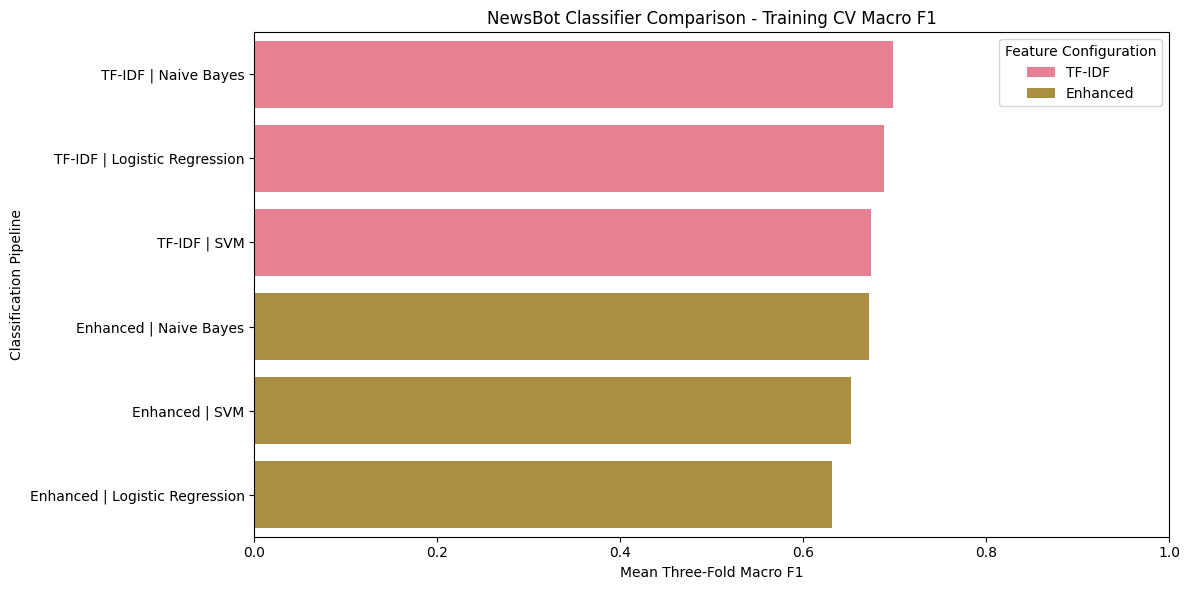


CLASSIFICATION TRAINING VALIDATION COMPLETE
Six classification experiments: Passed
Cross-validation: Passed
Training/test separation: Passed
Best model selection: Passed
Holdout evaluation: Passed
Results exported successfully.


In [17]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 25 - CLASSIFICATION MODEL TRAINING
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - X_train, X_test, y_train, y_test from Cell 24
# - text_feature_column and numeric_feature_columns
# - Pipeline and classifiers from Cell 4

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import f1_score
from sklearn.base import clone

print("=" * 60)
print("NEWSBOT CLASSIFICATION MODEL TRAINING")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE TRAINING AND TESTING DATA
# ------------------------------------------------------------

assert len(X_train) == 1600
assert len(X_test) == 400

assert len(y_train) == len(X_train)
assert len(y_test) == len(X_test)

assert len(np.unique(y_train)) == 6

print(f"Training articles: {len(X_train):,}")
print(f"Testing articles: {len(X_test):,}")
print(f"Classification categories: {len(class_names)}")

print("\nThe test set will not be used for model selection.")

# ------------------------------------------------------------
# 2. DEFINE TF-IDF CONFIGURATION
# ------------------------------------------------------------

# These settings match our exploratory analysis.
# A fresh vectorizer is fitted within each training
# fold to prevent test-data leakage.

def create_tfidf_vectorizer():

    return TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.8,
        lowercase=False,
        dtype=np.float32
    )

# ------------------------------------------------------------
# 3. DEFINE FEATURE PROCESSING PIPELINES
# ------------------------------------------------------------

def create_feature_transformer(configuration):
    """
    Build a feature transformer.

    Baseline:
        TF-IDF text features only.

    Enhanced:
        TF-IDF + sentiment, length, POS,
        and syntactic numerical features.

    All learned transformations are fitted
    only on training data within each fold.
    """

    transformers = [
        (
            "text",
            create_tfidf_vectorizer(),
            text_feature_column
        )
    ]

    if configuration == "Enhanced":

        transformers.append(
            (
                "numeric",
                MaxAbsScaler(),
                numeric_feature_columns
            )
        )

    elif configuration != "TF-IDF":

        raise ValueError(
            f"Unknown configuration: {configuration}"
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=1.0
    )

# ------------------------------------------------------------
# 4. DEFINE CLASSIFICATION ALGORITHMS
# ------------------------------------------------------------

# Linear SVM is used for efficient text classification.
# Probability estimates are enabled for NewsBot's
# eventual interactive prediction system.

classifiers = {
    "Naive Bayes": MultinomialNB(
        alpha=1.0
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "SVM": SVC(
        kernel="linear",
        probability=True,
        random_state=42
    )
}

feature_configurations = [
    "TF-IDF",
    "Enhanced"
]

# ------------------------------------------------------------
# 5. CONFIGURE CROSS-VALIDATION
# ------------------------------------------------------------

# Stratified folds preserve category proportions.
# Macro F1 gives equal importance to each category.

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy"
}

# ------------------------------------------------------------
# 6. TRAIN AND CROSS-VALIDATE SIX CONFIGURATIONS
# ------------------------------------------------------------

results = {}
model_pipelines = {}
comparison_records = []

print("\n" + "=" * 60)
print("THREE-FOLD CROSS-VALIDATION")
print("=" * 60)

for configuration in feature_configurations:

    for algorithm_name, classifier in classifiers.items():

        model_name = (
            f"{configuration} | {algorithm_name}"
        )

        print(f"\nEvaluating: {model_name}")

        feature_transformer = (
            create_feature_transformer(configuration)
        )

        pipeline = Pipeline([
            ("features", feature_transformer),
            ("classifier", clone(classifier))
        ])

        # Cross-validation fits a separate pipeline
        # for each training fold.
        #
        # The held-out test set is NOT used here.

        cv_scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv_strategy,
            scoring=scoring_metrics,
            n_jobs=1,
            error_score="raise"
        )

        mean_macro_f1 = (
            cv_scores["test_macro_f1"].mean()
        )

        std_macro_f1 = (
            cv_scores["test_macro_f1"].std()
        )

        mean_accuracy = (
            cv_scores["test_accuracy"].mean()
        )

        std_accuracy = (
            cv_scores["test_accuracy"].std()
        )

        results[model_name] = {
            "configuration": configuration,
            "algorithm": algorithm_name,
            "cv_macro_f1": mean_macro_f1,
            "cv_macro_f1_std": std_macro_f1,
            "cv_accuracy": mean_accuracy,
            "cv_accuracy_std": std_accuracy
        }

        model_pipelines[model_name] = pipeline

        comparison_records.append({
            "Model": model_name,
            "Configuration": configuration,
            "Algorithm": algorithm_name,
            "CV Macro F1": mean_macro_f1,
            "CV F1 Std": std_macro_f1,
            "CV Accuracy": mean_accuracy,
            "CV Accuracy Std": std_accuracy
        })

        print(
            f"  Macro F1: "
            f"{mean_macro_f1:.4f} "
            f"(std: {std_macro_f1:.4f})"
        )

        print(
            f"  Accuracy: "
            f"{mean_accuracy:.4f} "
            f"(std: {std_accuracy:.4f})"
        )

# ------------------------------------------------------------
# 7. COMPARE ALL SIX EXPERIMENTS
# ------------------------------------------------------------

comparison_df = pd.DataFrame(
    comparison_records
)

comparison_df = comparison_df.sort_values(
    by=["CV Macro F1", "CV Accuracy"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("NEWSBOT MODEL COMPARISON")
print("=" * 60)

display(
    comparison_df.round(4)
)

# ------------------------------------------------------------
# 8. SELECT BEST MODEL USING TRAINING CV ONLY
# ------------------------------------------------------------

# IMPORTANT:
# Do not select the best model using test accuracy.
# Doing so would turn the test set into a selection set.

best_model_name = comparison_df.loc[
    0, "Model"
]

best_configuration = comparison_df.loc[
    0, "Configuration"
]

best_algorithm = comparison_df.loc[
    0, "Algorithm"
]

print("\n" + "=" * 60)
print("MODEL SELECTION")
print("=" * 60)

print(f"Selected model: {best_model_name}")

print(
    f"Cross-validation macro F1: "
    f"{comparison_df.loc[0, 'CV Macro F1']:.4f}"
)

print(
    "\nSelection criterion: Highest training "
    "cross-validation macro F1."
)

# ------------------------------------------------------------
# 9. FIT WINNING PIPELINE ON FULL TRAINING SET
# ------------------------------------------------------------

# A fresh copy of the selected pipeline is fitted
# on all 1,600 training records.

best_model = clone(
    model_pipelines[best_model_name]
)

best_model.fit(
    X_train,
    y_train
)

# Preserve model references for the next cells.
trained_models = {
    best_model_name: best_model
}

print("\nSelected pipeline trained successfully.")

# ------------------------------------------------------------
# 10. FINAL EVALUATION ON UNTOUCHED TEST SET
# ------------------------------------------------------------

# We evaluate the selected model only after
# cross-validation and model selection are complete.

best_predictions = best_model.predict(
    X_test
)

best_probabilities = best_model.predict_proba(
    X_test
)

test_accuracy = accuracy_score(
    y_test,
    best_predictions
)

test_macro_f1 = f1_score(
    y_test,
    best_predictions,
    average="macro"
)

results[best_model_name].update({
    "accuracy": test_accuracy,
    "macro_f1": test_macro_f1,
    "predictions": best_predictions,
    "probabilities": best_probabilities
})

print("\n" + "=" * 60)
print("FINAL HOLDOUT TEST RESULTS")
print("=" * 60)

print(f"Selected model: {best_model_name}")
print(f"Test articles: {len(y_test)}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro F1: {test_macro_f1:.4f}")

# ------------------------------------------------------------
# 11. COMPARE FEATURE CONFIGURATIONS
# ------------------------------------------------------------

# Compare the best cross-validation performance
# from each feature configuration.

configuration_summary = (
    comparison_df.groupby("Configuration")
    .agg(
        Best_CV_Macro_F1=("CV Macro F1", "max"),
        Mean_CV_Macro_F1=("CV Macro F1", "mean"),
        Mean_CV_Accuracy=("CV Accuracy", "mean")
    )
    .round(4)
)

print("\n" + "=" * 60)
print("BASELINE VS ENHANCED FEATURE COMPARISON")
print("=" * 60)

display(configuration_summary)

# ------------------------------------------------------------
# 12. VISUALIZE CROSS-VALIDATION PERFORMANCE
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="CV Macro F1",
    y="Model",
    hue="Configuration",
    dodge=False
)

plt.title(
    "NewsBot Classifier Comparison - Training CV Macro F1"
)

plt.xlabel("Mean Three-Fold Macro F1")
plt.ylabel("Classification Pipeline")
plt.xlim(0, 1)
plt.legend(title="Feature Configuration")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. EXPORT MODEL COMPARISON
# ------------------------------------------------------------

comparison_df.to_csv(
    "newsbot_model_comparison.csv",
    index=False
)

configuration_summary.to_csv(
    "newsbot_feature_configuration_comparison.csv"
)

# ------------------------------------------------------------
# 14. VALIDATE MODEL OUTPUT
# ------------------------------------------------------------

assert len(comparison_df) == 6, (
    "Expected six classification experiments."
)

assert len(best_predictions) == len(y_test), (
    "Prediction count mismatch."
)

assert best_probabilities.shape == (
    len(y_test),
    len(class_names)
), "Probability matrix shape mismatch."

assert np.allclose(
    best_probabilities.sum(axis=1),
    1.0,
    atol=0.001
), "Model probabilities do not sum to one."

assert best_model_name in trained_models

assert 0 <= test_accuracy <= 1
assert 0 <= test_macro_f1 <= 1

print("\n" + "=" * 60)
print("CLASSIFICATION TRAINING VALIDATION COMPLETE")
print("=" * 60)

print("Six classification experiments: Passed")
print("Cross-validation: Passed")
print("Training/test separation: Passed")
print("Best model selection: Passed")
print("Holdout evaluation: Passed")
print("Results exported successfully.")


NEWSBOT CLASSIFICATION EVALUATION
Selected model: TF-IDF | Naive Bayes
Test records: 400

DETAILED CLASSIFICATION REPORT
               precision    recall  f1-score   support

Entertainment       0.75      0.64      0.69        67
      Finance       0.64      0.64      0.64        67
     Politics       0.81      0.83      0.82        66
       Sports       0.81      0.84      0.82        67
   Technology       0.75      0.67      0.71        67
     Wellness       0.70      0.83      0.76        66

     accuracy                           0.74       400
    macro avg       0.74      0.74      0.74       400
 weighted avg       0.74      0.74      0.74       400



,precision,recall,f1-score,support
Entertainment,0.7544,0.6418,0.6935,67.0000
Finance,0.6418,0.6418,0.6418,67.0000
Politics,0.8088,0.8333,0.8209,66.0000
Sports,0.8116,0.8358,0.8235,67.0000
Technology,0.7500,0.6716,0.7087,67.0000
Wellness,0.6962,0.8333,0.7586,66.0000
accuracy,0.7425,0.7425,0.7425,0.7425
macro avg,0.7438,0.7430,0.7412,400.0000
weighted avg,0.7438,0.7425,0.7409,400.0000



OVERALL CLASSIFICATION PERFORMANCE
Correct predictions: 297
Incorrect predictions: 103
Accuracy: 0.7425
Macro F1: 0.7412

PER-CATEGORY CLASSIFICATION PERFORMANCE


,Category,Precision,Recall,F1 Score,Support
0,Sports,0.8116,0.8358,0.8235,67
1,Politics,0.8088,0.8333,0.8209,66
2,Wellness,0.6962,0.8333,0.7586,66
3,Technology,0.7500,0.6716,0.7087,67
4,Entertainment,0.7544,0.6418,0.6935,67
5,Finance,0.6418,0.6418,0.6418,67


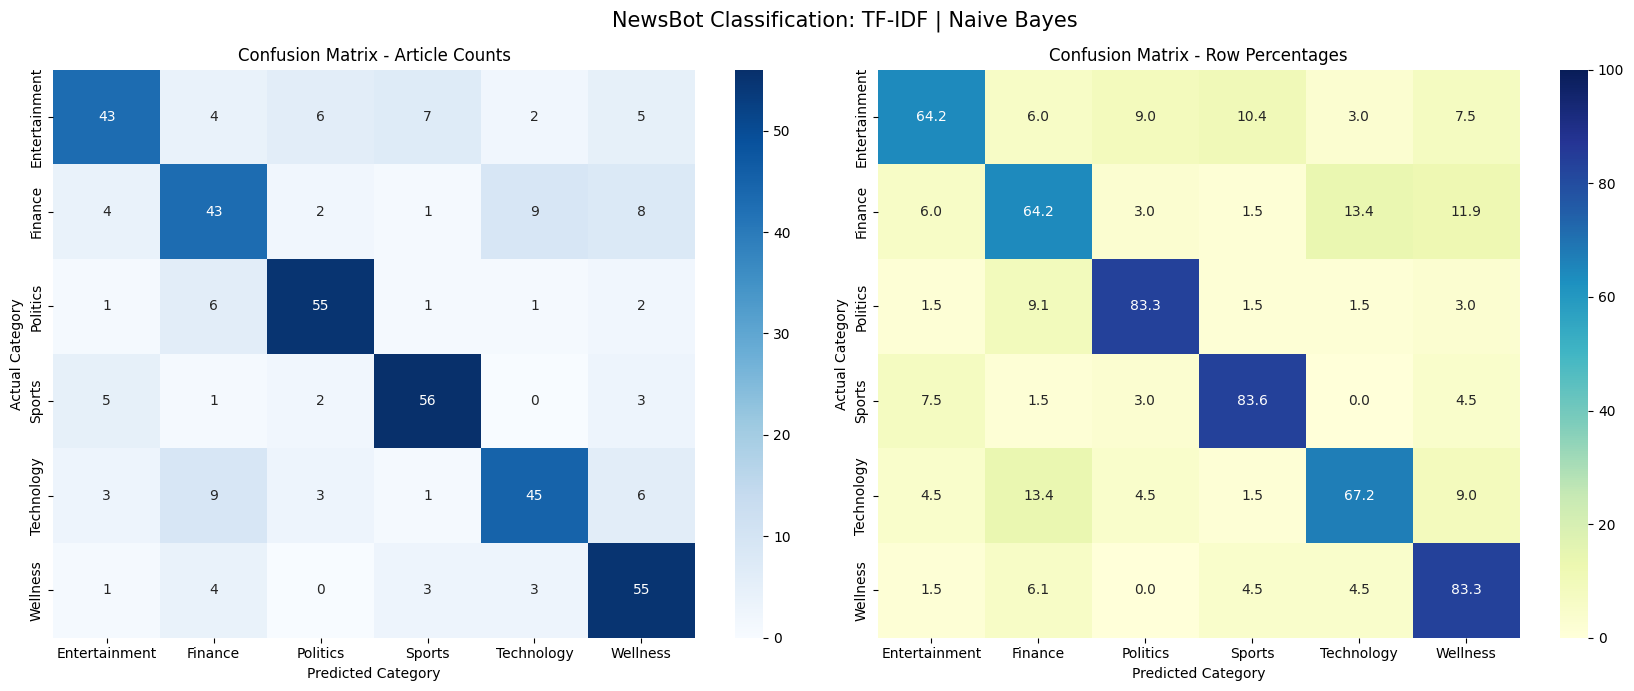

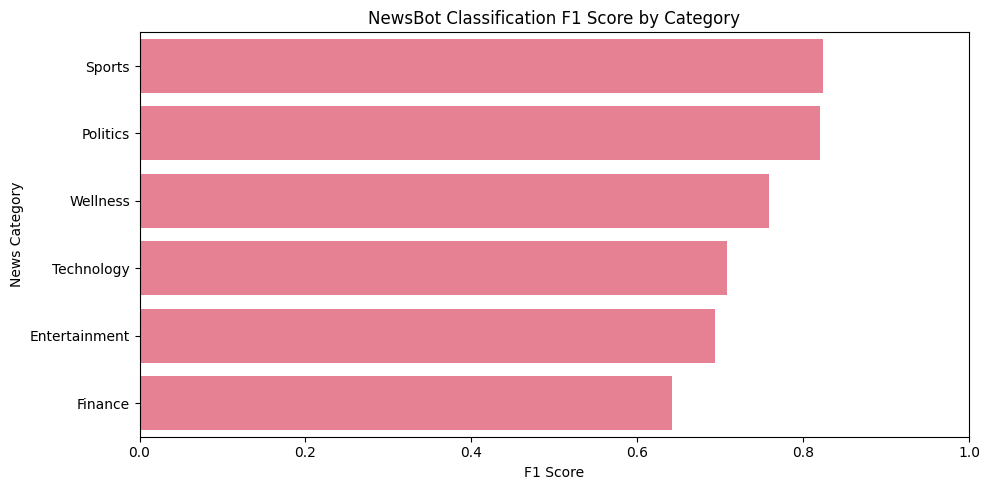


MOST COMMON CATEGORY CONFUSIONS


,actual_category,predicted_category,Errors
8,Finance,Technology,9
20,Technology,Finance,9
9,Finance,Wellness,8
2,Entertainment,Sports,7
11,Politics,Finance,6
1,Entertainment,Politics,6
23,Technology,Wellness,6
4,Entertainment,Wellness,5
15,Sports,Entertainment,5
25,Wellness,Finance,4



MISCLASSIFIED ARTICLE EXAMPLES


,article_id,actual_category,predicted_category,predicted_class_probability,title,content
216,118,Entertainment,Politics,0.667881,Dick Cheney Does Not Endorse Donald Trump (Yet),"He said it loud and clear: ""I'm not endorsing ..."
368,403,Entertainment,Politics,0.490349,John Oliver Nails The Most Terrifying Part Of ...,"The ""Last Week Tonight"" host slammed what the ..."
93,186,Entertainment,Sports,0.466659,Eminem Gives Strange Interview During Michigan...,Eminem joined Brent Musburger and Kirk Herbstr...
155,92,Technology,Finance,0.440248,How New Secure Credit Cards Are Hurting Netfli...,Keep your credit card information updated. Net...
258,480,Wellness,Sports,0.432643,Is Yoga The Secret To Olympic Gold?,Instead of going to Disney World after winning...
393,1985,Wellness,Technology,0.413275,Why Are Google Employees So Damn Happy?,Working at Google is awesome; everyone knows t...
226,692,Finance,Technology,0.395940,Message To Uber’s New CEO: Don’t Forget Your D...,"The veil has lifted on Silicon Valley, reveali..."
132,1697,Finance,Technology,0.379643,Tech CEO Celebrates Marissa Mayer For All The ...,Working 24/7 shouldn’t be an automatic badge o...
279,26,Politics,Finance,0.364255,Stop China’s Stealth Invasion,A corrupt Chinese company that is under invest...
305,325,Entertainment,Politics,0.363517,Establishment Will Stage 'Massive Resistance' ...,This weekend was an inflection point in the Re...



CLASSIFICATION ERROR RATES BY CATEGORY


...


WELLNESS


,Category,Feature,Relative Score
50,Wellness,text__health,1.7017
51,Wellness,text__study,1.4795
52,Wellness,text__cancer,1.4206
53,Wellness,text__healthy,1.3931
54,Wellness,text__life,1.3404
55,Wellness,text__meditation,1.3292
56,Wellness,text__sleep,1.3175
57,Wellness,text__exercise,1.3036
58,Wellness,text__weight,1.2977
59,Wellness,text__food,1.2511



FEATURE CONFIGURATION COMPARISON


,Best CV Macro F1
Configuration,
TF-IDF,0.6986
Enhanced,0.6724



Additional features are not automatically better than a simpler TF-IDF baseline.

CLASSIFICATION EVALUATION LIMITATIONS
1. Results apply to our sampled HuffPost headlines and descriptions.
2. Category labels reflect the original publisher's editorial classification.
3. Some articles may reasonably belong to more than one topic.
4. Predicted class probabilities may not be well calibrated.
5. Test-set examples are for interpretation, not additional model selection or tuning.
6. Feature associations do not establish causation or factual importance.

CLASSIFICATION EVALUATION VALIDATION COMPLETE
Classification report: Passed
Confusion matrix: Passed
Category metrics: Passed
Prediction alignment: Passed
Error analysis: Passed
Feature interpretation: Completed
Evaluation files exported successfully.


In [18]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 26 - CLASSIFICATION EVALUATION AND ERROR ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies:
# - best_model, best_model_name from Cell 25
# - best_predictions, best_probabilities from Cell 25
# - y_test, X_test, test_article_ids from Cell 24
# - df, class_names, comparison_df
# - pandas, NumPy, Matplotlib, Seaborn from Cell 4

from sklearn.metrics import (
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

print("=" * 60)
print("NEWSBOT CLASSIFICATION EVALUATION")
print("=" * 60)

print(f"Selected model: {best_model_name}")
print(f"Test records: {len(y_test):,}")

# ------------------------------------------------------------
# 1. VALIDATE MODEL PREDICTIONS
# ------------------------------------------------------------

actual_labels = y_test.to_numpy()
predicted_labels = np.asarray(best_predictions)
model_classes = best_model.classes_

assert len(actual_labels) == len(predicted_labels)
assert len(actual_labels) == len(test_article_ids)

assert set(model_classes) == set(class_names), (
    "Model classes do not match NewsBot categories."
)

assert best_probabilities.shape == (
    len(actual_labels),
    len(model_classes)
), "Prediction probability dimensions are incorrect."

# ------------------------------------------------------------
# 2. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DETAILED CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        actual_labels,
        predicted_labels,
        labels=class_names,
        zero_division=0
    )
)

report_dict = classification_report(
    actual_labels,
    predicted_labels,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

classification_report_df = pd.DataFrame(
    report_dict
).T

display(
    classification_report_df.round(4)
)

# ------------------------------------------------------------
# 3. OVERALL PERFORMANCE
# ------------------------------------------------------------

correct_predictions = int(
    np.sum(actual_labels == predicted_labels)
)

incorrect_predictions = (
    len(actual_labels) - correct_predictions
)

final_accuracy = accuracy_score(
    actual_labels,
    predicted_labels
)

final_macro_f1 = f1_score(
    actual_labels,
    predicted_labels,
    average="macro"
)

print("\n" + "=" * 60)
print("OVERALL CLASSIFICATION PERFORMANCE")
print("=" * 60)

print(f"Correct predictions: {correct_predictions}")
print(f"Incorrect predictions: {incorrect_predictions}")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Macro F1: {final_macro_f1:.4f}")

# ------------------------------------------------------------
# 4. PER-CATEGORY PERFORMANCE
# ------------------------------------------------------------

precision, recall, f1_values, support = (
    precision_recall_fscore_support(
        actual_labels,
        predicted_labels,
        labels=class_names,
        zero_division=0
    )
)

category_performance_df = pd.DataFrame({
    "Category": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_values,
    "Support": support
})

category_performance_df = (
    category_performance_df
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 60)
print("PER-CATEGORY CLASSIFICATION PERFORMANCE")
print("=" * 60)

display(
    category_performance_df.round(4)
)

# ------------------------------------------------------------
# 5. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=class_names
)

# Normalize rows to percentages.
# Each row represents the actual news category.

cm_percent = (
    cm /
    np.maximum(cm.sum(axis=1, keepdims=True), 1)
    * 100
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix - Article Counts")
axes[0].set_xlabel("Predicted Category")
axes[0].set_ylabel("Actual Category")

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)

axes[1].set_title("Confusion Matrix - Row Percentages")
axes[1].set_xlabel("Predicted Category")
axes[1].set_ylabel("Actual Category")

plt.suptitle(
    f"NewsBot Classification: {best_model_name}",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. VISUALIZE PER-CATEGORY F1 SCORES
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_performance_df,
    x="F1 Score",
    y="Category"
)

plt.title("NewsBot Classification F1 Score by Category")
plt.xlabel("F1 Score")
plt.ylabel("News Category")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. PREPARE ARTICLE-LEVEL PREDICTION RESULTS
# ------------------------------------------------------------

# The largest predicted probability is useful for
# prioritizing examples for investigation.
#
# IMPORTANT:
# These probabilities are not necessarily calibrated.
# They are not verified measures of model certainty.

prediction_df = pd.DataFrame({
    "article_id": test_article_ids,
    "actual_category": actual_labels,
    "predicted_category": predicted_labels,
    "predicted_class_probability": (
        best_probabilities.max(axis=1)
    )
})

prediction_df["correct"] = (
    prediction_df["actual_category"] ==
    prediction_df["predicted_category"]
)

# Join source text for qualitative error analysis.

article_reference = df[
    [
        "article_id",
        "title",
        "content",
        "original_category"
    ]
].copy()

prediction_df = prediction_df.merge(
    article_reference,
    on="article_id",
    how="left",
    validate="one_to_one"
)

assert prediction_df["title"].notna().all()

# ------------------------------------------------------------
# 8. IDENTIFY COMMON CLASSIFICATION ERRORS
# ------------------------------------------------------------

errors_df = prediction_df[
    ~prediction_df["correct"]
].copy()

error_pairs_df = (
    errors_df.groupby(
        ["actual_category", "predicted_category"]
    )
    .size()
    .reset_index(name="Errors")
    .sort_values("Errors", ascending=False)
)

print("\n" + "=" * 60)
print("MOST COMMON CATEGORY CONFUSIONS")
print("=" * 60)

if not error_pairs_df.empty:

    display(
        error_pairs_df.head(12)
    )

else:
    print("No classification errors detected.")

# ------------------------------------------------------------
# 9. EXAMINE MISCLASSIFIED NEWS RECORDS
# ------------------------------------------------------------

# Examples with the highest predicted-class
# probabilities can reveal confident-looking errors.
#
# This does not mean those probabilities are calibrated.

print("\n" + "=" * 60)
print("MISCLASSIFIED ARTICLE EXAMPLES")
print("=" * 60)

if not errors_df.empty:

    example_errors = (
        errors_df.sort_values(
            "predicted_class_probability",
            ascending=False
        )
        .head(10)
    )

    display(
        example_errors[
            [
                "article_id",
                "actual_category",
                "predicted_category",
                "predicted_class_probability",
                "title",
                "content"
            ]
        ]
    )

else:
    print("No misclassified articles.")

# ------------------------------------------------------------
# 10. ANALYZE CATEGORY-LEVEL ERROR RATES
# ------------------------------------------------------------

category_error_summary = (
    prediction_df.groupby("actual_category")
    .agg(
        Test_Articles=("article_id", "count"),
        Correct=("correct", "sum")
    )
)

category_error_summary["Incorrect"] = (
    category_error_summary["Test_Articles"] -
    category_error_summary["Correct"]
)

category_error_summary["Error_Rate_Percent"] = (
    category_error_summary["Incorrect"] /
    category_error_summary["Test_Articles"] * 100
)

category_error_summary = (
    category_error_summary.sort_values(
        "Error_Rate_Percent",
        ascending=False
    )
)

print("\n" + "=" * 60)
print("CLASSIFICATION ERROR RATES BY CATEGORY")
print("=" * 60)

display(
    category_error_summary.round(2)
)

# ------------------------------------------------------------
# 11. INTERPRET THE SELECTED MODEL'S FEATURES
# ------------------------------------------------------------

# The winning model is a scikit-learn Pipeline:
# ColumnTransformer -> Classification algorithm.
#
# Extract actual feature names from the fitted model,
# not from the exploratory TF-IDF matrix in Cell 12.

print("\n" + "=" * 60)
print("MODEL FEATURE INTERPRETATION")
print("=" * 60)

fitted_transformer = (
    best_model.named_steps["features"]
)

fitted_classifier = (
    best_model.named_steps["classifier"]
)

model_feature_names = (
    fitted_transformer.get_feature_names_out()
)

feature_interpretation_records = []

if hasattr(fitted_classifier, "feature_log_prob_"):

    # Multinomial Naive Bayes:
    # Compare a feature's conditional log probability
    # for one category against the other categories.
    #
    # Higher values indicate stronger relative
    # association within this fitted model.

    log_probs = fitted_classifier.feature_log_prob_

    for class_index, category in enumerate(
        fitted_classifier.classes_
    ):

        other_class_indices = [
            i for i in range(len(model_classes))
            if i != class_index
        ]

        relative_scores = (
            log_probs[class_index] -
            log_probs[other_class_indices].mean(axis=0)
        )

        top_indices = np.argsort(
            relative_scores
        )[-10:][::-1]

        for feature_index in top_indices:

            feature_interpretation_records.append({
                "Category": category,
                "Feature": model_feature_names[feature_index],
                "Relative Score": float(
                    relative_scores[feature_index]
                )
            })

elif hasattr(fitted_classifier, "coef_"):

    # Linear classifiers:
    # Coefficients measure the model's learned
    # associations with each class.

    coefficients = fitted_classifier.coef_

    if coefficients.shape[0] == len(model_classes):

        for class_index, category in enumerate(
            fitted_classifier.classes_
        ):

            top_indices = np.argsort(
                coefficients[class_index]
            )[-10:][::-1]

            for feature_index in top_indices:

                feature_interpretation_records.append({
                    "Category": category,
                    "Feature": model_feature_names[feature_index],
                    "Relative Score": float(
                        coefficients[
                            class_index,
                            feature_index
                        ]
                    )
                })

feature_interpretation_df = pd.DataFrame(
    feature_interpretation_records,
    columns=[
        "Category",
        "Feature",
        "Relative Score"
    ]
)

if not feature_interpretation_df.empty:

    print(
        "Top model-associated features by category:"
    )

    for category in class_names:

        print(f"\n{category.upper()}")

        display(
            feature_interpretation_df[
                feature_interpretation_df["Category"] == category
            ].round(4)
        )

else:

    print(
        "Direct feature ranking is unavailable "
        "for this selected estimator."
    )

# ------------------------------------------------------------
# 12. SUMMARIZE BASELINE VS ENHANCED RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FEATURE CONFIGURATION COMPARISON")
print("=" * 60)

feature_comparison_summary = (
    comparison_df.groupby("Configuration")
    ["CV Macro F1"]
    .max()
    .sort_values(ascending=False)
)

display(
    feature_comparison_summary
    .rename("Best CV Macro F1")
    .to_frame()
    .round(4)
)

print(
    "\nAdditional features are not automatically "
    "better than a simpler TF-IDF baseline."
)

# ------------------------------------------------------------
# 13. DOCUMENT ANALYSIS LIMITATIONS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION EVALUATION LIMITATIONS")
print("=" * 60)

print(
    "1. Results apply to our sampled HuffPost "
    "headlines and descriptions."
)

print(
    "2. Category labels reflect the original "
    "publisher's editorial classification."
)

print(
    "3. Some articles may reasonably belong "
    "to more than one topic."
)

print(
    "4. Predicted class probabilities may not "
    "be well calibrated."
)

print(
    "5. Test-set examples are for interpretation, "
    "not additional model selection or tuning."
)

print(
    "6. Feature associations do not establish "
    "causation or factual importance."
)

# ------------------------------------------------------------
# 14. EXPORT EVALUATION RESULTS
# ------------------------------------------------------------

classification_report_df.to_csv(
    "newsbot_classification_report.csv"
)

category_performance_df.to_csv(
    "newsbot_category_performance.csv",
    index=False
)

prediction_df.to_csv(
    "newsbot_test_predictions.csv",
    index=False
)

error_pairs_df.to_csv(
    "newsbot_classification_error_pairs.csv",
    index=False
)

category_error_summary.to_csv(
    "newsbot_category_error_rates.csv"
)

feature_interpretation_df.to_csv(
    "newsbot_model_feature_interpretation.csv",
    index=False
)

# ------------------------------------------------------------
# 15. FINAL VALIDATION
# ------------------------------------------------------------

assert len(prediction_df) == len(y_test)

assert (
    prediction_df["correct"].sum()
    == correct_predictions
)

assert (
    len(errors_df) == incorrect_predictions
)

assert cm.sum() == len(y_test)

assert (
    category_error_summary["Test_Articles"].sum()
    == len(y_test)
)

assert (
    category_performance_df["Support"].sum()
    == len(y_test)
)

print("\n" + "=" * 60)
print("CLASSIFICATION EVALUATION VALIDATION COMPLETE")
print("=" * 60)

print("Classification report: Passed")
print("Confusion matrix: Passed")
print("Category metrics: Passed")
print("Prediction alignment: Passed")
print("Error analysis: Passed")
print("Feature interpretation: Completed")
print("Evaluation files exported successfully.")



### Classification Error Analysis: Finance and Technology Overlap

Our classification results revealed a notable relationship between the Finance and Technology categories. Of the 103 misclassified test records, nine Finance articles were predicted as Technology, while nine Technology articles were predicted as Finance.

These 18 errors account for approximately 17.5% of all classification mistakes.

However, these results do not necessarily mean that all 18 articles are genuinely ambiguous. Technology companies participate in financial markets, and technological developments can influence business decisions, investments, and stock prices.

For example, an article about NVIDIA developing new GPU technology would primarily concern Technology, while an article about NVIDIA's financial performance or stock valuation would primarily concern Finance. Some articles may meaningfully involve both subjects.

This raises an important question about our classification methodology: Is the model incorrectly interpreting the article, or is the original single-label categorization insufficient to represent its subject matter?

**Further Analysis:** We should manually examine the 18 misclassified records to identify genuine classification errors, overlapping subject matter, and possible differences in editorial labeling.

**Potential Improvement:** Future versions of NewsBot could support hierarchical or multi-label classification, allowing articles to receive a primary category alongside relevant secondary topics.

**Key Finding:** Classification accuracy depends not only on the algorithm but also on the quality, consistency, and intended meaning of the dataset's labels.


## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [19]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 5237
📰 Articles processed: 2000

🏷️ Entity types found: ['DATE' 'EVENT' 'GPE' 'PERSON' 'ORG' 'CARDINAL' 'TIME' 'WORK_OF_ART'
 'NORP' 'PERCENT' 'FAC' 'LAW' 'LOC' 'ORDINAL' 'MONEY' 'QUANTITY' 'PRODUCT'
 'LANGUAGE']

📝 Sample entities:
                   text   label       category
0                Friday    DATE        Finance
1          Black Friday   EVENT        Finance
2               America     GPE        Finance
3         Jessica Smith  PERSON       Wellness
4             Shape.com     ORG       Wellness
5  Behold Rose Leslie's  PERSON  Entertainment
6              Valyrian     ORG  Entertainment
7    Trump's Travel Ban     ORG         Sports
8              The 2026   EVENT         Sports
9       World Cup Teams   EVENT         Sports


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
PERSON         1500
ORG            1338
DATE            640
CARDINAL        459
GPE             441
NORP            225
WORK_OF_ART     184
ORDINAL          82
MONEY            81
EVENT            70
TIME             70
FAC              41
PERCENT          32
LOC              26
PRODUCT          18
QUANTITY         17
LAW              12
LANGUAGE          1
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC  GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                    
Entertainment        47    96      8   10   45         0    4    1      9   
Finance              95   144     15    4   69         0    1    9     36   
Politics             59   114      8    4  136         0    3    7      6   
Sports               97   101     27   21  112         0    1    1      7   
Technology           63    97      9    0   45         1  

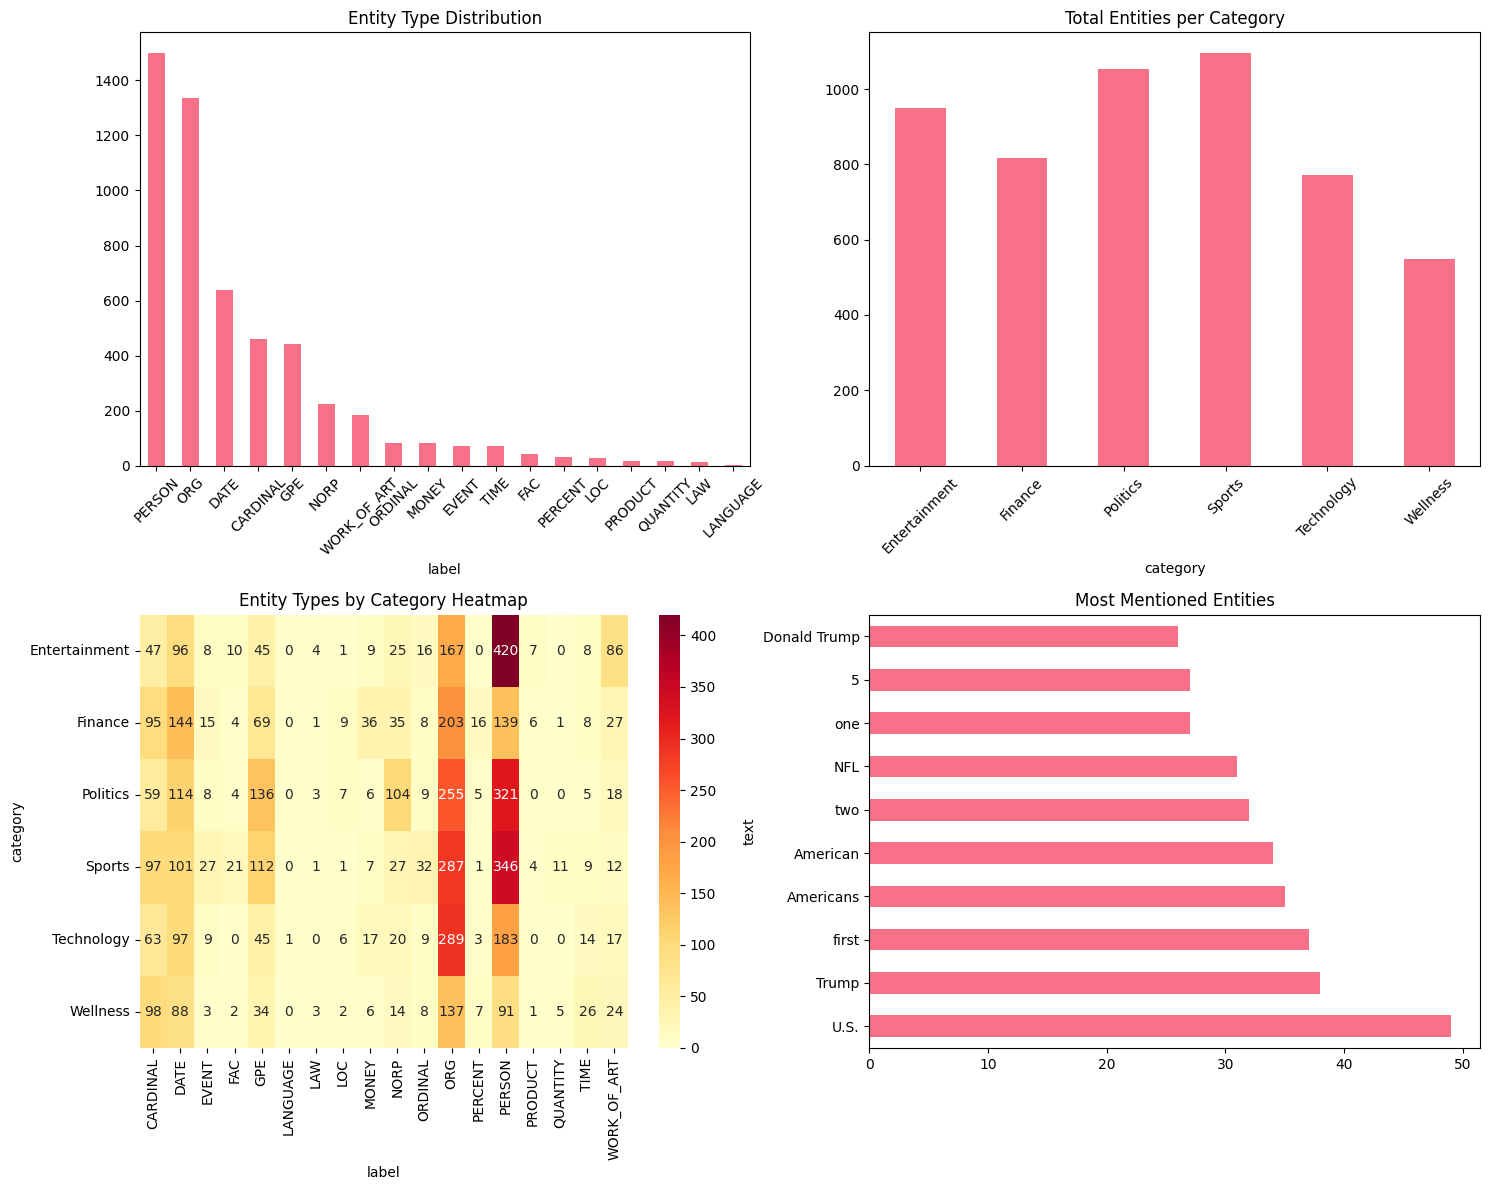

In [20]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

NEWSBOT ADVANCED ENTITY INTELLIGENCE
Original entity mentions: 5,237
Core entity mentions: 3,279
Unique article-entity combinations: 3158

MOST FREQUENT PEOPLE, ORGANIZATIONS AND PLACES


,Articles,Categories,Display_Name,Observed_Labels
entity_key,,,,
u.s.,47,6,U.S.,GPE
trump,34,4,Trump,"ORG, PERSON"
donald trump,26,6,Donald Trump,PERSON
nfl,26,1,NFL,ORG
gop,21,2,GOP,ORG
apple,19,2,Apple,ORG
america,18,5,America,GPE
hillary clinton,15,4,Hillary Clinton,PERSON
google,13,3,Google,ORG



ENTITIES FOUND ACROSS MULTIPLE NEWS CATEGORIES


,Articles,Categories,Display_Name,Observed_Labels
entity_key,,,,
u.s.,47,6,U.S.,GPE
donald trump,26,6,Donald Trump,PERSON
america,18,5,America,GPE
trump,34,4,Trump,"ORG, PERSON"
hillary clinton,15,4,Hillary Clinton,PERSON
donald trump's,11,4,Donald Trump's,PERSON
san francisco,9,4,San Francisco,GPE
russia,8,4,Russia,GPE
reuters,6,4,Reuters,ORG


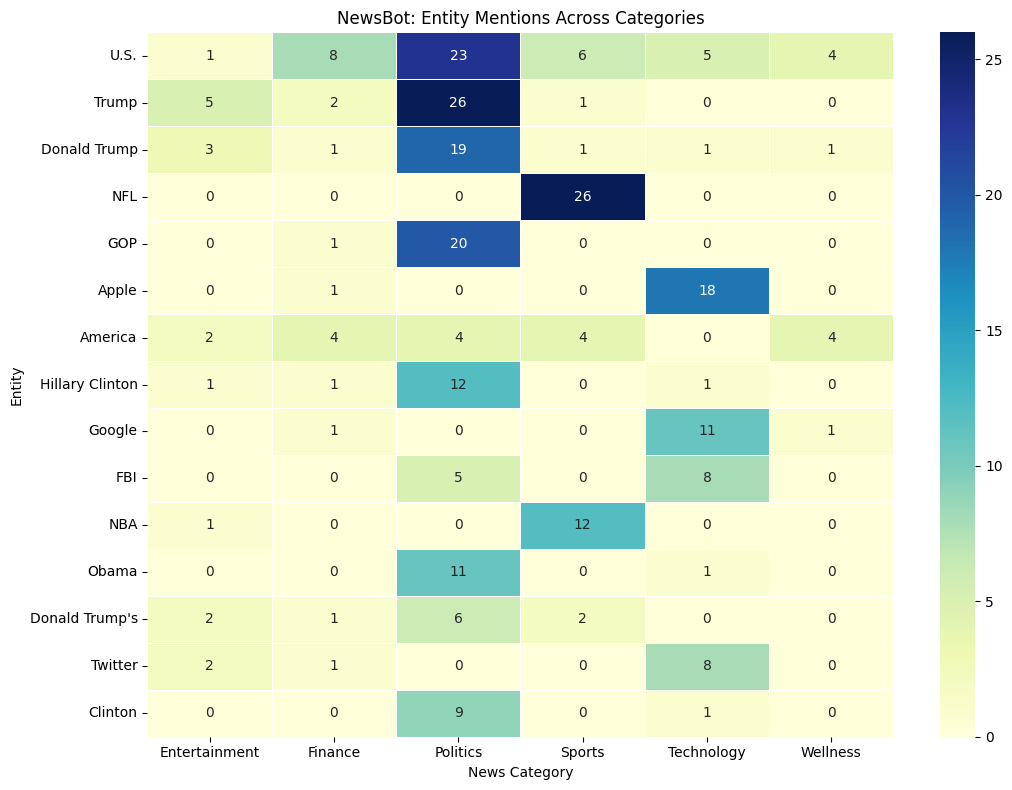


ENTITY CO-OCCURRENCE


,Entity A,Entity B,Shared Articles
0,Apple,FBI,5
1,Colin Kaepernick,San Francisco,3
2,FBI,Trump,3
3,Clinton,Hillary Clinton,3
4,Reuters,U.S.,2
5,Trump,U.S.,2
6,New York,Reuters,2
7,GOP,U.S.,2
8,Obama,U.S.,2
9,Hillary Clinton,NRA,2



Co-occurrence means two entities appeared in the same article, not that a relationship between them has been verified.

ARTICLE SENTIMENT ASSOCIATED WITH ENTITY MENTIONS


,Entity,Articles,Mean_Article_Sentiment,Negative_Article_Percent
entity_key,,,,
u.s.,U.S.,47,0.075,38.298
trump,Trump,34,-0.004,38.235
nfl,NFL,26,-0.093,46.154
donald trump,Donald Trump,26,-0.118,38.462
gop,GOP,21,-0.116,52.381
apple,Apple,19,0.014,31.579
america,America,18,-0.103,44.444
hillary clinton,Hillary Clinton,15,-0.093,46.667
google,Google,13,0.212,23.077



Interpretation: VADER scores describe the overall article text. They do not measure public opinion about an individual person or organization.

ENTITY LABELS FOR MANUAL REVIEW


,article_id,category,text,label
5,4,Entertainment,Behold Rose Leslie's,PERSON
6,4,Entertainment,Valyrian,ORG
7,5,Sports,Trump's Travel Ban,ORG
8,5,Sports,The 2026,EVENT
9,5,Sports,World Cup Teams,EVENT
100,34,Entertainment,Trump,ORG
221,81,Politics,Donald Trump,PERSON
313,118,Entertainment,Donald Trump,PERSON
406,155,Politics,Trump,PERSON
692,268,Politics,Trump,ORG



These are review candidates. Their correctness must be evaluated in context.

ADVANCED ENTITY ANALYSIS COMPLETE
Core entity filtering: Passed
Cross-category tracking: Passed
Entity co-occurrence: Passed
Article-sentiment association: Passed
Quality-control sample: Prepared
Analysis files exported successfully.


In [21]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# CELL 31 - ADVANCED ENTITY INTELLIGENCE ANALYSIS
# ITAI 2373 Natural Language Processing
# ============================================================

from itertools import combinations

print("=" * 60)
print("NEWSBOT ADVANCED ENTITY INTELLIGENCE")
print("=" * 60)

# ------------------------------------------------------------
# 1. VALIDATE SOURCE DATA
# ------------------------------------------------------------

assert not entities_df.empty, (
    "NER results are empty."
)

assert {"article_id", "category", "text", "label"}.issubset(
    entities_df.columns
)

assert {"article_id", "full_sentiment", "full_label"}.issubset(
    sentiment_df.columns
)

# Focus on people, organizations, and geographic entities.
# Dates, ordinals, and numeric quantities remain available
# in the original entities_df for other applications.

CORE_ENTITY_TYPES = ["PERSON", "ORG", "GPE"]

core_entities = entities_df[
    entities_df["label"].isin(CORE_ENTITY_TYPES)
].copy()

# Normalize capitalization and spacing for counting.
# This does not automatically merge aliases such as
# "Donald Trump" and "Trump".

core_entities["entity_name"] = (
    core_entities["text"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

core_entities["entity_key"] = (
    core_entities["entity_name"].str.casefold()
)

core_entities = core_entities[
    core_entities["entity_key"] != ""
].copy()

# One record per entity per article for article coverage.
unique_article_entities = core_entities.drop_duplicates(
    subset=["article_id", "entity_key"]
).copy()

print(f"Original entity mentions: {len(entities_df):,}")
print(f"Core entity mentions: {len(core_entities):,}")
print(
    "Unique article-entity combinations:",
    len(unique_article_entities)
)

# ------------------------------------------------------------
# 2. ENTITY FREQUENCY AND CATEGORY COVERAGE
# ------------------------------------------------------------

entity_overview = (
    unique_article_entities
    .groupby("entity_key")
    .agg(
        Articles=("article_id", "nunique"),
        Categories=("category", "nunique"),
        Display_Name=(
            "entity_name",
            lambda values: values.mode().iloc[0]
        ),
        Observed_Labels=(
            "label",
            lambda values: ", ".join(
                sorted(values.unique())
            )
        )
    )
    .sort_values(
        ["Articles", "Categories"],
        ascending=False
    )
)

print("\n" + "=" * 60)
print("MOST FREQUENT PEOPLE, ORGANIZATIONS AND PLACES")
print("=" * 60)

display(entity_overview.head(20))

# ------------------------------------------------------------
# 3. CROSS-CATEGORY ENTITY TRACKING
# ------------------------------------------------------------

cross_category_entities = (
    entity_overview[
        entity_overview["Categories"] >= 2
    ]
    .sort_values(
        ["Categories", "Articles"],
        ascending=False
    )
)

print("\n" + "=" * 60)
print("ENTITIES FOUND ACROSS MULTIPLE NEWS CATEGORIES")
print("=" * 60)

display(cross_category_entities.head(20))

# Entity-category table for frequently mentioned entities.
top_entity_keys = entity_overview.head(15).index

entity_category_matrix = pd.crosstab(
    unique_article_entities["entity_key"],
    unique_article_entities["category"]
)

entity_category_matrix = entity_category_matrix.reindex(
    top_entity_keys,
    fill_value=0
)

entity_category_matrix.index = [
    entity_overview.loc[key, "Display_Name"]
    for key in entity_category_matrix.index
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    entity_category_matrix,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.4
)

plt.title("NewsBot: Entity Mentions Across Categories")
plt.xlabel("News Category")
plt.ylabel("Entity")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. ENTITY CO-OCCURRENCE ANALYSIS
# ------------------------------------------------------------

# Examine which frequently mentioned entities appear
# together within the same news record.
#
# Co-occurrence does not establish a factual relationship.

top_30_keys = set(
    entity_overview.head(30).index
)

pair_counts = Counter()

for article_id, group in unique_article_entities.groupby(
    "article_id"
):

    present_entities = sorted(
        set(group["entity_key"]) & top_30_keys
    )

    for pair in combinations(present_entities, 2):
        pair_counts[pair] += 1

cooccurrence_records = []

for (entity_a, entity_b), count in pair_counts.most_common():

    cooccurrence_records.append({
        "Entity A": entity_overview.loc[
            entity_a, "Display_Name"
        ],
        "Entity B": entity_overview.loc[
            entity_b, "Display_Name"
        ],
        "Shared Articles": count
    })

cooccurrence_df = pd.DataFrame(
    cooccurrence_records,
    columns=[
        "Entity A",
        "Entity B",
        "Shared Articles"
    ]
)

print("\n" + "=" * 60)
print("ENTITY CO-OCCURRENCE")
print("=" * 60)

if not cooccurrence_df.empty:
    display(cooccurrence_df.head(15))
else:
    print("No co-occurrences among the selected entities.")

print(
    "\nCo-occurrence means two entities appeared "
    "in the same article, not that a relationship "
    "between them has been verified."
)

# ------------------------------------------------------------
# 5. ENTITY AND ARTICLE SENTIMENT ASSOCIATIONS
# ------------------------------------------------------------

# Join each unique article-entity mention with VADER.
# IMPORTANT: This measures the sentiment of the article
# mentioning the entity, NOT sentiment toward the entity.

entity_sentiment = unique_article_entities.merge(
    sentiment_df[
        ["article_id", "full_sentiment", "full_label"]
    ],
    on="article_id",
    how="left",
    validate="many_to_one"
)

entity_sentiment_summary = (
    entity_sentiment
    .groupby("entity_key")
    .agg(
        Articles=("article_id", "nunique"),
        Mean_Article_Sentiment=(
            "full_sentiment", "mean"
        ),
        Negative_Article_Percent=(
            "full_label",
            lambda values: (
                values.eq("negative").mean() * 100
            )
        )
    )
)

# Require at least five articles for this summary.
# This remains a descriptive threshold, not a
# statistical significance test.

entity_sentiment_summary = (
    entity_sentiment_summary[
        entity_sentiment_summary["Articles"] >= 5
    ]
    .sort_values("Articles", ascending=False)
)

entity_sentiment_summary.insert(
    0,
    "Entity",
    [
        entity_overview.loc[key, "Display_Name"]
        for key in entity_sentiment_summary.index
    ]
)

print("\n" + "=" * 60)
print("ARTICLE SENTIMENT ASSOCIATED WITH ENTITY MENTIONS")
print("=" * 60)

display(entity_sentiment_summary.head(20).round(3))

print(
    "\nInterpretation: VADER scores describe the overall "
    "article text. They do not measure public opinion "
    "about an individual person or organization."
)

# ------------------------------------------------------------
# 6. ENTITY QUALITY-CONTROL EXAMPLES
# ------------------------------------------------------------

review_terms = [
    "Trump",
    "Donald Trump",
    "Behold Rose Leslie's",
    "Valyrian",
    "Trump's Travel Ban",
    "The 2026",
    "World Cup Teams"
]

entity_audit_candidates = entities_df[
    entities_df["text"].isin(review_terms)
][
    ["article_id", "category", "text", "label"]
].drop_duplicates()

print("\n" + "=" * 60)
print("ENTITY LABELS FOR MANUAL REVIEW")
print("=" * 60)

display(entity_audit_candidates.head(25))

print(
    "\nThese are review candidates. "
    "Their correctness must be evaluated in context."
)

# ------------------------------------------------------------
# 7. EXPORT ADVANCED ANALYSIS RESULTS
# ------------------------------------------------------------

entity_overview.to_csv(
    "newsbot_entity_frequency_analysis.csv"
)

cross_category_entities.to_csv(
    "newsbot_cross_category_entities.csv"
)

cooccurrence_df.to_csv(
    "newsbot_entity_cooccurrence.csv",
    index=False
)

entity_sentiment_summary.to_csv(
    "newsbot_entity_article_sentiment.csv"
)

entity_audit_candidates.to_csv(
    "newsbot_ner_quality_review.csv",
    index=False
)

# ------------------------------------------------------------
# 8. FINAL VALIDATION
# ------------------------------------------------------------

assert not core_entities.empty
assert not entity_overview.empty

assert unique_article_entities.duplicated(
    subset=["article_id", "entity_key"]
).sum() == 0

assert entity_sentiment["full_sentiment"].notna().all()

assert entity_sentiment["article_id"].isin(
    df["article_id"]
).all()

print("\n" + "=" * 60)
print("ADVANCED ENTITY ANALYSIS COMPLETE")
print("=" * 60)

print("Core entity filtering: Passed")
print("Cross-category tracking: Passed")
print("Entity co-occurrence: Passed")
print("Article-sentiment association: Passed")
print("Quality-control sample: Prepared")
print("Analysis files exported successfully.")


### Advanced NER Findings: Entity Identity, Roles, and Context

Our advanced Named Entity Recognition analysis identified 5,237 entity mentions across 2,000 news records. Of those, 3,279 mentions involved people, organizations, or geographical entities, representing 3,158 unique article-entity combinations.

One of the most important findings was that the same individual could be identified under different names and entity labels. For example, `Donald Trump` appeared in 26 articles across all six categories, while `Trump` appeared in 34 articles across four categories. The shorter name was also labeled as both `PERSON` and `ORG`. We observed additional inconsistencies involving Obama, Twitter, and other extracted entities.

These findings revealed three distinct challenges: **entity identity, professional or public role, and article context**. Identifying a person does not automatically establish their relationship to an organization, their role in a particular article, or the primary topic being discussed.

Our results also demonstrated cross-category relationships. For example, Apple and FBI appeared together in five records. Although this provides a useful starting point for investigation, co-occurrence alone does not establish a verified relationship.

This analysis highlights an important limitation of traditional NER: extracting structured information does not guarantee that the information is correctly identified, accurately labeled, or interpreted within its proper context.

**Potential Improvements:** Future versions of NewsBot could incorporate entity linking, alias resolution, contextual relationship extraction, and multi-label news classification. A manually annotated evaluation set would also help measure entity-level precision, recall, and boundary accuracy.

**Key Finding:** Reliable news intelligence requires more than extracting names. It requires distinguishing who an entity is, what role it plays, and why it is relevant to the information being analyzed.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

NEWSBOT | COMPREHENSIVE ANALYSIS AND INSIGHTS

MODEL SELECTION: 3-FOLD TRAINING CROSS-VALIDATION


,Model,Configuration,CV Macro F1,CV Accuracy
0,TF-IDF | Naive Bayes,TF-IDF,0.6986,0.6994
1,TF-IDF | Logistic Regression,TF-IDF,0.6888,0.6887
2,TF-IDF | SVM,TF-IDF,0.6747,0.6737
3,Enhanced | Naive Bayes,Enhanced,0.6724,0.6694
4,Enhanced | SVM,Enhanced,0.6518,0.6512
5,Enhanced | Logistic Regression,Enhanced,0.6313,0.6325



FINAL EVALUATION: SELECTED MODEL, UNTOUCHED HOLDOUT SET


,Selected Model,Holdout Articles,Accuracy,Macro Precision,Macro Recall,Macro F1,Correct,Incorrect
0,TF-IDF | Naive Bayes,400,0.7425,0.7438,0.743,0.7412,297,103



Methodology: The six models were compared using training-only cross-validation. Only the selected model was evaluated on the 400-article holdout set. These are different evaluation stages.

CATEGORY PERFORMANCE AND ERROR RATES


...


ENTITY LABELS THAT OCCUR ACROSS MULTIPLE CATEGORIES


,Articles,Categories,Display_Name,Observed_Labels
entity_key,,,,
u.s.,47,6,U.S.,GPE
donald trump,26,6,Donald Trump,PERSON
america,18,5,America,GPE
trump,34,4,Trump,"ORG, PERSON"
hillary clinton,15,4,Hillary Clinton,PERSON
donald trump's,11,4,Donald Trump's,PERSON
san francisco,9,4,San Francisco,GPE
russia,8,4,Russia,GPE
reuters,6,4,Reuters,ORG



ARTICLE SENTIMENT ASSOCIATED WITH ENTITY MENTIONS


,Entity,Articles,Mean_Article_Sentiment,Negative_Article_Percent
entity_key,,,,
u.s.,U.S.,47,0.075,38.298
trump,Trump,34,-0.004,38.235
nfl,NFL,26,-0.093,46.154
donald trump,Donald Trump,26,-0.118,38.462
gop,GOP,21,-0.116,52.381
apple,Apple,19,0.014,31.579
america,America,18,-0.103,44.444
hillary clinton,Hillary Clinton,15,-0.093,46.667
google,Google,13,0.212,23.077



NER interpretation: These are model-detected mentions, not verified identities. Different spellings and aliases may refer to the same person. Article sentiment is NOT sentiment toward a mentioned person or organization.


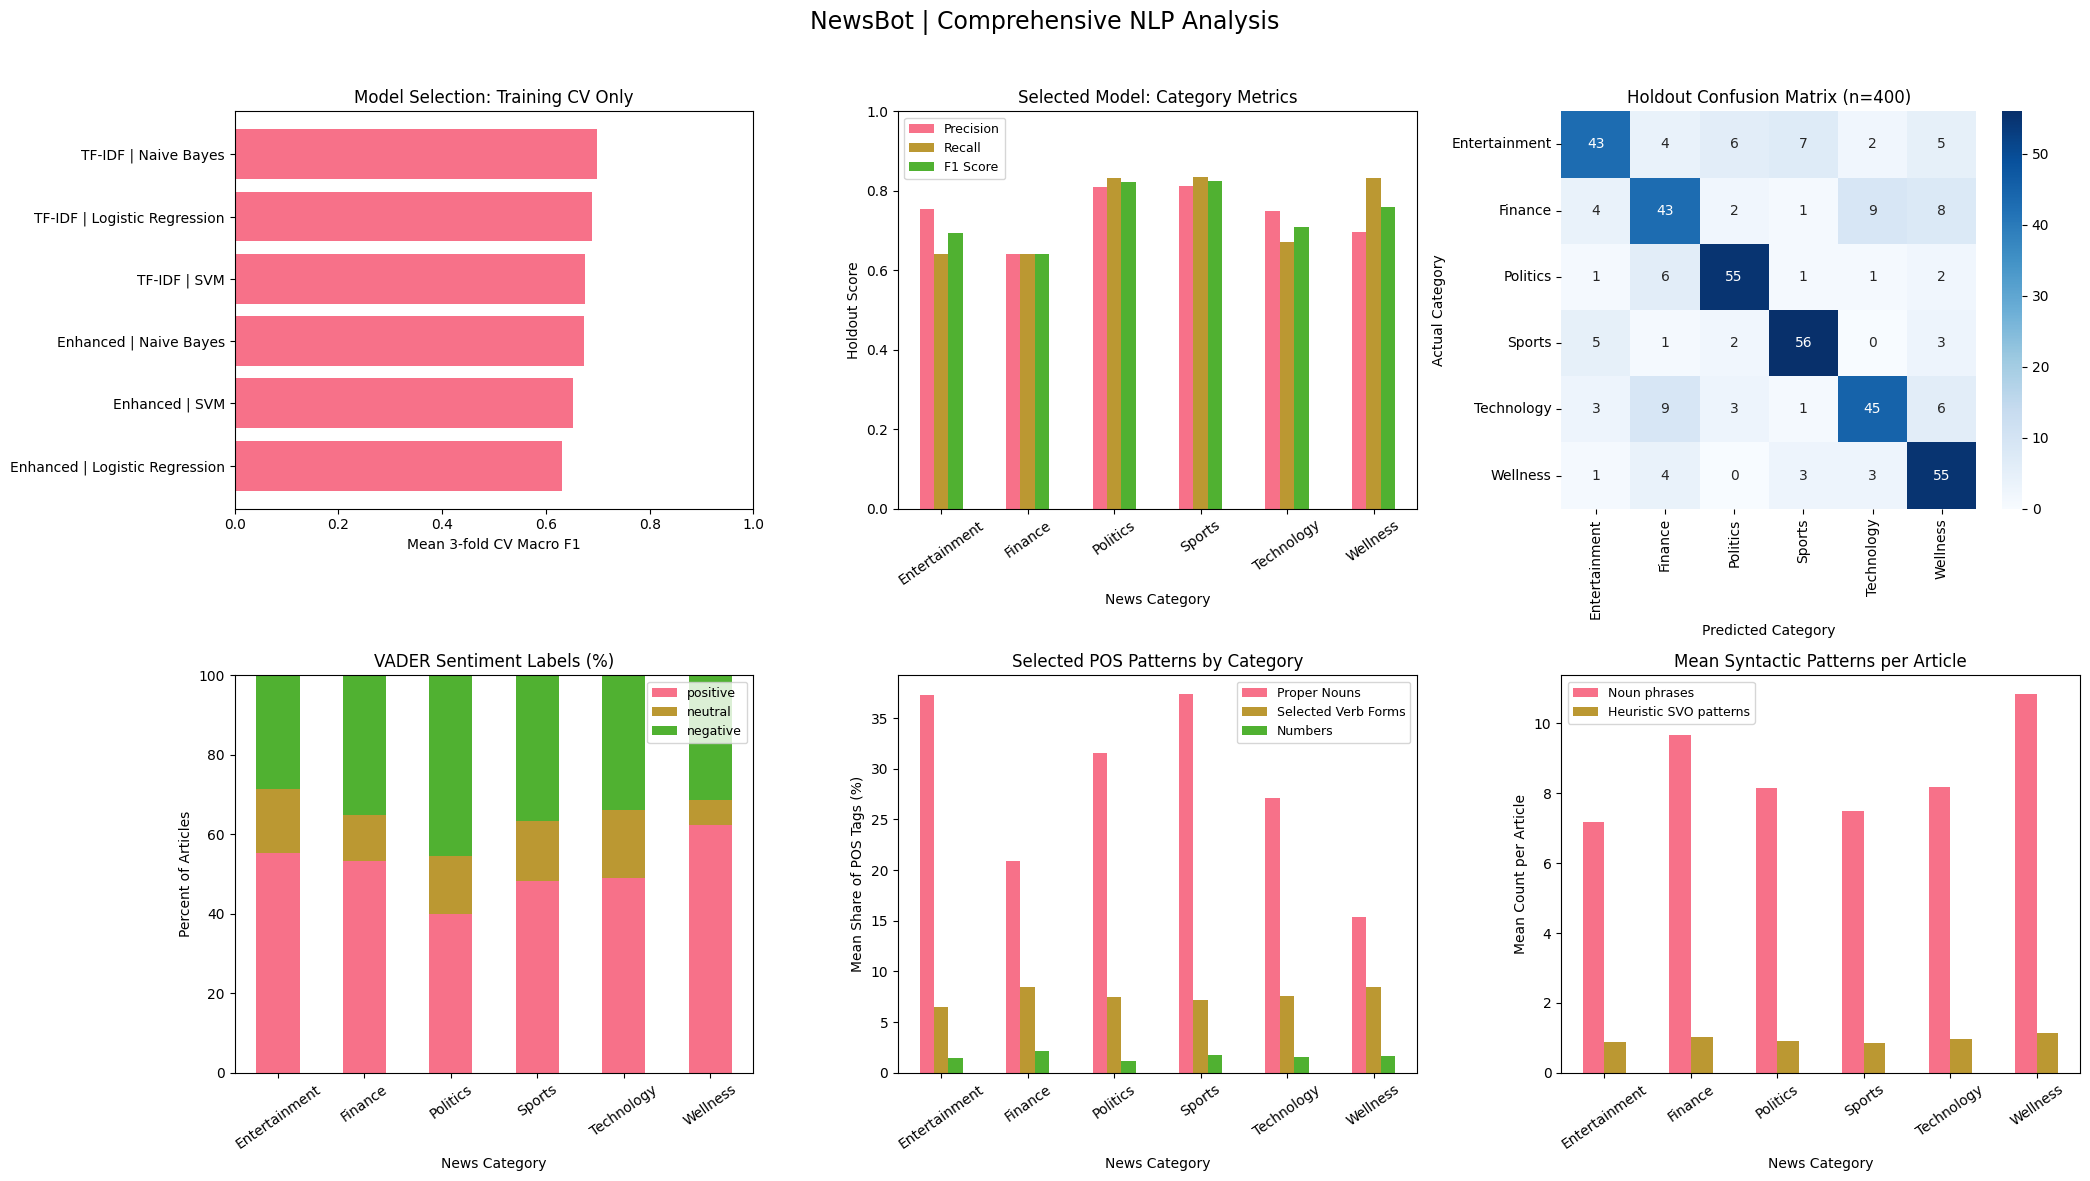

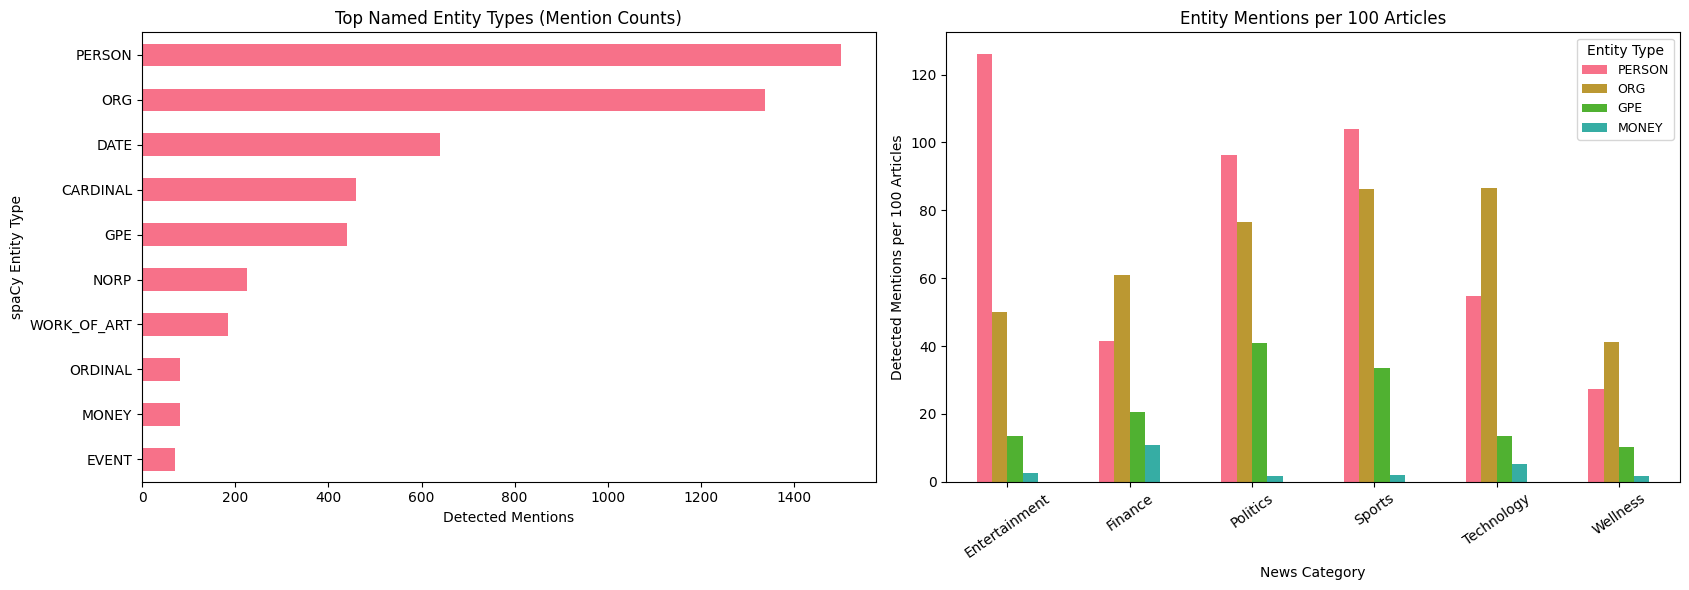


NEWSBOT | FINDINGS AND BUSINESS IMPLICATIONS
1. News organization: TF-IDF | Naive Bayes produced 74.25% holdout accuracy and 0.7412 macro F1. Sports had the strongest category F1; Finance had the weakest. Human review remains useful for uncertain subjects.
2. Cross-topic monitoring: 18 Finance/Technology confusions warrant review. Future multi-label classification may help with articles about the financial activities of technology companies.
3. Editorial analysis: 58.2% of headlines and descriptions received different VADER labels. This suggests a review opportunity, not proof that headlines are misleading or biased.
4. Entity tracking: Identify recurring people, organizations, and places across categories, but do not equate co-occurrence with relationships or whole-article sentiment with reputation.
5. Information quality: This dataset contains short headlines and descriptions, not full news articles. Word counts and syntactic complexity are descriptive proxies, not verified measurem

In [22]:
# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# COMPREHENSIVE ANALYSIS AND INSIGHTS - FINAL DASHBOARD
# ITAI 2373 Natural Language Processing
# ============================================================
# Uses existing results from Modules 1-8. No refitting, model
# selection, or additional evaluation on the holdout test set.

print('=' * 66)
print('NEWSBOT | COMPREHENSIVE ANALYSIS AND INSIGHTS')
print('=' * 66)

# ------------------------------------------------------------
# 1. VERIFY SAVED IN-MEMORY RESULTS AND DATA ALIGNMENT
# ------------------------------------------------------------

required_tables = {
    'df': df,
    'comparison_df': comparison_df,
    'category_performance_df': category_performance_df,
    'category_error_summary': category_error_summary,
    'error_pairs_df': error_pairs_df,
    'sentiment_df': sentiment_df,
    'sentiment_dist_pct': sentiment_dist_pct,
    'headline_description_summary': headline_description_summary,
    'pos_group_summary': pos_group_summary,
    'syntax_category_means': syntax_category_means,
    'syntactic_df': syntactic_df,
    'entities_df': entities_df,
    'entity_overview': entity_overview,
    'cross_category_entities': cross_category_entities,
    'entity_sentiment_summary': entity_sentiment_summary,
}

for table_name, table in required_tables.items():
    if not isinstance(table, pd.DataFrame):
        raise TypeError(f'{table_name} must be a DataFrame.')
    if table.empty:
        raise ValueError(f'{table_name} is empty.')

assert len(df) == len(sentiment_df) == len(syntactic_df) == 2000
assert len(comparison_df) == 6
assert len(category_performance_df) == 6
assert len(y_test) == 400
assert int(cm.sum()) == len(y_test)
assert int(category_error_summary['Incorrect'].sum()) == int((~prediction_df['correct']).sum())
assert comparison_df.iloc[0]['Model'] == best_model_name
assert set(df['category']) == set(class_names)

# Restrict all comparisons to observed values. Test metrics are
# reported for the single CV-selected model ONLY.
model_cv_report = comparison_df[
    ['Model', 'Configuration', 'CV Macro F1', 'CV Accuracy']
].copy()

holdout_report = pd.DataFrame([{
    'Selected Model': best_model_name,
    'Holdout Articles': len(y_test),
    'Accuracy': final_accuracy,
    'Macro Precision': category_performance_df['Precision'].mean(),
    'Macro Recall': category_performance_df['Recall'].mean(),
    'Macro F1': final_macro_f1,
    'Correct': int((prediction_df['correct']).sum()),
    'Incorrect': int((~prediction_df['correct']).sum()),
}])

assert np.isclose(
    holdout_report.loc[0, 'Accuracy'],
    holdout_report.loc[0, 'Correct'] / len(y_test)
)
assert 0 <= holdout_report.loc[0, 'Macro F1'] <= 1

print('\nMODEL SELECTION: 3-FOLD TRAINING CROSS-VALIDATION')
display(model_cv_report.round(4))

print('\nFINAL EVALUATION: SELECTED MODEL, UNTOUCHED HOLDOUT SET')
display(holdout_report.round(4))

print(
    '\nMethodology: The six models were compared using training-only '
    'cross-validation. Only the selected model was evaluated on the '
    '400-article holdout set. These are different evaluation stages.'
)

# ------------------------------------------------------------
# 2. SYNTHESIZE CLASSIFICATION ERRORS AND CROSSOVERS
# ------------------------------------------------------------

category_detail = category_performance_df.merge(
    category_error_summary[
        ['Test_Articles', 'Incorrect', 'Error_Rate_Percent']
    ],
    left_on='Category', right_index=True,
    how='left', validate='one_to_one'
)

print('\nCATEGORY PERFORMANCE AND ERROR RATES')
display(category_detail.round(3))

print('\nMOST COMMON DIRECTIONAL CATEGORY CONFUSIONS')
display(error_pairs_df.head(10))

finance_to_tech = int(error_pairs_df.loc[
    (error_pairs_df['actual_category'] == 'Finance') &
    (error_pairs_df['predicted_category'] == 'Technology'),
    'Errors'
].sum())

tech_to_finance = int(error_pairs_df.loc[
    (error_pairs_df['actual_category'] == 'Technology') &
    (error_pairs_df['predicted_category'] == 'Finance'),
    'Errors'
].sum())

print(
    f'\nFinance → Technology: {finance_to_tech} articles; '
    f'Technology → Finance: {tech_to_finance} articles. '
    'This shows overlapping subject matter and/or classification errors; '
    'it does not prove both labels are correct.'
)

# ------------------------------------------------------------
# 3. SYNTHESIZE SENTIMENT, POS AND SYNTACTIC ANALYSIS
# ------------------------------------------------------------

sentiment_disagreement = int(
    sentiment_df['title_content_disagreement'].sum()
)
disagreement_percent = (
    sentiment_disagreement / len(sentiment_df) * 100
)

linguistic_summary = pd.DataFrame({
    'Articles': df.groupby('category')['article_id'].size(),
    'Average Words': df.groupby('category')['word_count'].mean(),
    'Positive Articles (%)': sentiment_dist_pct['positive'],
    'Headline/Description Disagreement (%)':
        headline_description_summary['Disagreement_Percent'],
    'Proper Nouns (% of POS tags)': pos_group_summary['Proper Nouns'],
    'Selected Verbs (% of POS tags)':
        pos_group_summary['Selected Verb Forms'],
    'Numerical Tags (% of POS tags)': pos_group_summary['Numbers'],
    'Mean SVO Patterns per Article':
        syntax_category_means['num_svo_patterns'],
    'Mean Sentence Length':
        syntax_category_means['avg_sentence_length'],
}).sort_index()

print('\nLINGUISTIC AND SENTIMENT COMPARISONS BY CATEGORY')
display(linguistic_summary.round(2))

print(
    f'\nHeadline/description sentiment labels differ in '
    f'{sentiment_disagreement:,} of {len(df):,} records '
    f'({disagreement_percent:.1f}%). '
    'This is an automated VADER comparison, not evidence of bias.'
)
print(
    f'Total heuristic SVO patterns: '
    f'{int(syntactic_df["num_svo_patterns"].sum()):,}. '
    'These are parser-derived patterns, not verified factual claims.'
)

# ------------------------------------------------------------
# 4. SYNTHESIZE NER AND CROSS-CATEGORY ENTITIES
# ------------------------------------------------------------

entity_type_counts = entities_df['label'].value_counts()
entity_counts_by_category = pd.crosstab(
    entities_df['category'], entities_df['label']
).reindex(index=class_names, fill_value=0)

# Mentions per 100 sampled articles, NOT percentages of articles:
# an article can mention multiple entities of the same type.
entity_counts_per_100 = entity_counts_by_category.reindex(
    columns=['PERSON', 'ORG', 'GPE', 'MONEY'],
    fill_value=0
).div(
    df.groupby('category').size().reindex(class_names),
    axis=0
).mul(100)

print('\nNER DISTRIBUTION: MOST FREQUENT ENTITY TYPES')
display(entity_type_counts.rename('Mentions').to_frame().head(12))

print('\nENTITY LABELS THAT OCCUR ACROSS MULTIPLE CATEGORIES')
display(cross_category_entities.head(12))

print('\nARTICLE SENTIMENT ASSOCIATED WITH ENTITY MENTIONS')
display(entity_sentiment_summary.head(10).round(3))

print(
    '\nNER interpretation: These are model-detected mentions, '
    'not verified identities. Different spellings and aliases may '
    'refer to the same person. Article sentiment is NOT sentiment '
    'toward a mentioned person or organization.'
)

# ------------------------------------------------------------
# 5. OVERVIEW DASHBOARD: MODEL AND LINGUISTIC ANALYSIS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(21, 12))

# A. Training-only cross-validation comparison.
cv_plot = model_cv_report.sort_values('CV Macro F1')
axes[0, 0].barh(cv_plot['Model'], cv_plot['CV Macro F1'])
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_xlabel('Mean 3-fold CV Macro F1')
axes[0, 0].set_title('Model Selection: Training CV Only')

# B. Precision/recall/F1 on the holdout set, selected model only.
category_performance_df.set_index('Category')[
    ['Precision', 'Recall', 'F1 Score']
].reindex(class_names).plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_xlabel('News Category')
axes[0, 1].set_ylabel('Holdout Score')
axes[0, 1].set_title('Selected Model: Category Metrics')
axes[0, 1].tick_params(axis='x', rotation=35)
axes[0, 1].legend(fontsize=9)

# C. The holdout confusion matrix.
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    ax=axes[0, 2]
)
axes[0, 2].set_title('Holdout Confusion Matrix (n=400)')
axes[0, 2].set_xlabel('Predicted Category')
axes[0, 2].set_ylabel('Actual Category')

# D. Sentiment by category (VADER on original wording).
sentiment_dist_pct.reindex(class_names)[
    ['positive', 'neutral', 'negative']
].plot(kind='bar', stacked=True, ax=axes[1, 0])
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_title('VADER Sentiment Labels (%)')
axes[1, 0].set_xlabel('News Category')
axes[1, 0].set_ylabel('Percent of Articles')
axes[1, 0].tick_params(axis='x', rotation=35)
axes[1, 0].legend(fontsize=9)

# E. Category-specific POS-tag proportions.
pos_group_summary.reindex(class_names)[
    ['Proper Nouns', 'Selected Verb Forms', 'Numbers']
].plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Selected POS Patterns by Category')
axes[1, 1].set_xlabel('News Category')
axes[1, 1].set_ylabel('Mean Share of POS Tags (%)')
axes[1, 1].tick_params(axis='x', rotation=35)
axes[1, 1].legend(fontsize=9)

# F. Syntactic structures by category.
syntax_category_means.reindex(class_names)[
    ['num_noun_phrases', 'num_svo_patterns']
].rename(columns={
    'num_noun_phrases': 'Noun phrases',
    'num_svo_patterns': 'Heuristic SVO patterns'
}).plot(kind='bar', ax=axes[1, 2])
axes[1, 2].set_title('Mean Syntactic Patterns per Article')
axes[1, 2].set_xlabel('News Category')
axes[1, 2].set_ylabel('Mean Count per Article')
axes[1, 2].tick_params(axis='x', rotation=35)
axes[1, 2].legend(fontsize=9)

fig.suptitle('NewsBot | Comprehensive NLP Analysis', fontsize=17)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig('newsbot_comprehensive_dashboard.png', dpi=160, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# 6. ENTITY INTELLIGENCE VISUALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

entity_type_counts.head(10).sort_values().plot(
    kind='barh', ax=axes[0]
)
axes[0].set_title('Top Named Entity Types (Mention Counts)')
axes[0].set_xlabel('Detected Mentions')
axes[0].set_ylabel('spaCy Entity Type')

entity_counts_per_100.plot(kind='bar', ax=axes[1])
axes[1].set_title('Entity Mentions per 100 Articles')
axes[1].set_xlabel('News Category')
axes[1].set_ylabel('Detected Mentions per 100 Articles')
axes[1].tick_params(axis='x', rotation=35)
axes[1].legend(title='Entity Type', fontsize=9)

fig.tight_layout()
fig.savefig('newsbot_entity_intelligence_dashboard.png', dpi=160,
            bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# 7. EVIDENCE-BASED BUSINESS INSIGHTS AND LIMITATIONS
# ------------------------------------------------------------

best_category = category_performance_df.loc[
    category_performance_df['F1 Score'].idxmax(), 'Category'
]
worst_category = category_performance_df.loc[
    category_performance_df['F1 Score'].idxmin(), 'Category'
]

print('\n' + '=' * 66)
print('NEWSBOT | FINDINGS AND BUSINESS IMPLICATIONS')
print('=' * 66)

print(
    f'1. News organization: {best_model_name} produced '
    f'{final_accuracy:.2%} holdout accuracy and '
    f'{final_macro_f1:.4f} macro F1. '
    f'{best_category} had the strongest category F1; '
    f'{worst_category} had the weakest. '
    'Human review remains useful for uncertain subjects.'
)

print(
    f'2. Cross-topic monitoring: {finance_to_tech + tech_to_finance} '
    'Finance/Technology confusions warrant review. '
    'Future multi-label classification may help with articles '
    'about the financial activities of technology companies.'
)

print(
    f'3. Editorial analysis: {disagreement_percent:.1f}% of headlines '
    'and descriptions received different VADER labels. '
    'This suggests a review opportunity, not proof that '
    'headlines are misleading or biased.'
)

print(
    '4. Entity tracking: Identify recurring people, organizations, '
    'and places across categories, but do not equate co-occurrence '
    'with relationships or whole-article sentiment with reputation.'
)

print(
    '5. Information quality: This dataset contains short headlines '
    'and descriptions, not full news articles. Word counts and '
    'syntactic complexity are descriptive proxies, not verified '
    'measurements of reporting quality or article importance.'
)

print(
    '6. Reliability: Source labels can hide secondary subjects; '
    'NER can mislabel names; sentiment models can miss context; '
    'and the classifier cannot reject an unsupported news category. '
    'The prototype is not yet production-validated.'
)

# ------------------------------------------------------------
# 8. EXPORT TABLES AND VALIDATE DASHBOARD
# ------------------------------------------------------------

model_cv_report.to_csv('newsbot_dashboard_cv_models.csv', index=False)
holdout_report.to_csv('newsbot_dashboard_holdout_summary.csv', index=False)
category_detail.to_csv('newsbot_dashboard_category_errors.csv', index=False)
linguistic_summary.to_csv('newsbot_dashboard_linguistics.csv')
entity_counts_per_100.to_csv('newsbot_dashboard_entity_rates.csv')

assert len(model_cv_report) == 6
assert len(holdout_report) == 1
assert (
    int(holdout_report.loc[0, 'Correct']) +
    int(holdout_report.loc[0, 'Incorrect']) == len(y_test)
)
assert np.isclose(sentiment_dist_pct.sum(axis=1), 100).all()
assert int(entity_type_counts.sum()) == len(entities_df)

print('\nDashboard validation: PASSED')
print('Saved 2 dashboard figures (PNG) and 5 report tables (CSV).')
print('No model retraining or additional holdout model selection occurred.')


## 🏆 Extra Credit: Advanced News Intelligence Research

The extra-credit sections extend the validated baseline without changing the existing
six-category classifier, its **74.25% holdout accuracy**, or the existing integration test outputs.
They examine historical patterns, evaluate an experimental NER improvement, and provide
an optional interactive demonstration.

**Important evidence boundaries:** The source dataset is a category-stratified historical
sample of short HuffPost records, not a representative time series. NER outputs are
model predictions rather than verified identities. We report comparative measurements
from a small, explicitly **hand-authored synthetic NER evaluation set**, not a new
real-world benchmark. Additional research and evaluation are required before deployment.

### Extension A — Historical Temporal Intelligence

Review article counts by publication year, mentions of selected exact phrases per
100 sampled articles, and VADER article tone by year. This is descriptive analysis;
it is **not** a claim about changes in population-level news coverage, public opinion,
or causal relationships.


NEWSBOT EXTRA CREDIT | HISTORICAL NEWS AND ENTITY TRENDS

ARTICLE COUNTS BY HISTORICAL YEAR AND CATEGORY


category,Entertainment,Finance,Politics,Sports,Technology,Wellness
year,,,,,,
2012,10,157,0,16,75,123
2013,25,37,0,22,56,154
2014,15,45,13,30,8,52
2015,64,38,70,90,68,0
2016,70,32,86,93,96,0
2017,87,16,106,28,17,0
2018,36,4,31,33,14,0
2019,6,3,6,4,0,0
2020,6,1,10,0,0,4



TRACKED PHRASES IN ORIGINAL NEWS TEXT


,year,tracked_phrase,articles_mentioning_phrase,sample_articles_that_year,articles_per_100_sampled
11,2012,Apple,8,381,2.10
12,2013,Apple,8,294,2.72
13,2014,Apple,0,163,0.00
14,2015,Apple,5,330,1.52
15,2016,Apple,16,377,4.24
16,2017,Apple,0,254,0.00
17,2018,Apple,2,118,1.69
18,2019,Apple,0,19,0.00
19,2020,Apple,0,21,0.00
20,2021,Apple,0,25,0.00



AVERAGE ARTICLE SENTIMENT BY HISTORICAL YEAR


,year,sample_articles,mean_vader_compound
0,2012,381,0.113
1,2013,294,0.210
2,2014,163,0.225
3,2015,330,0.100
4,2016,377,0.024
5,2017,254,0.031
6,2018,118,0.018
7,2019,19,0.023
8,2020,21,-0.135
9,2021,25,-0.012


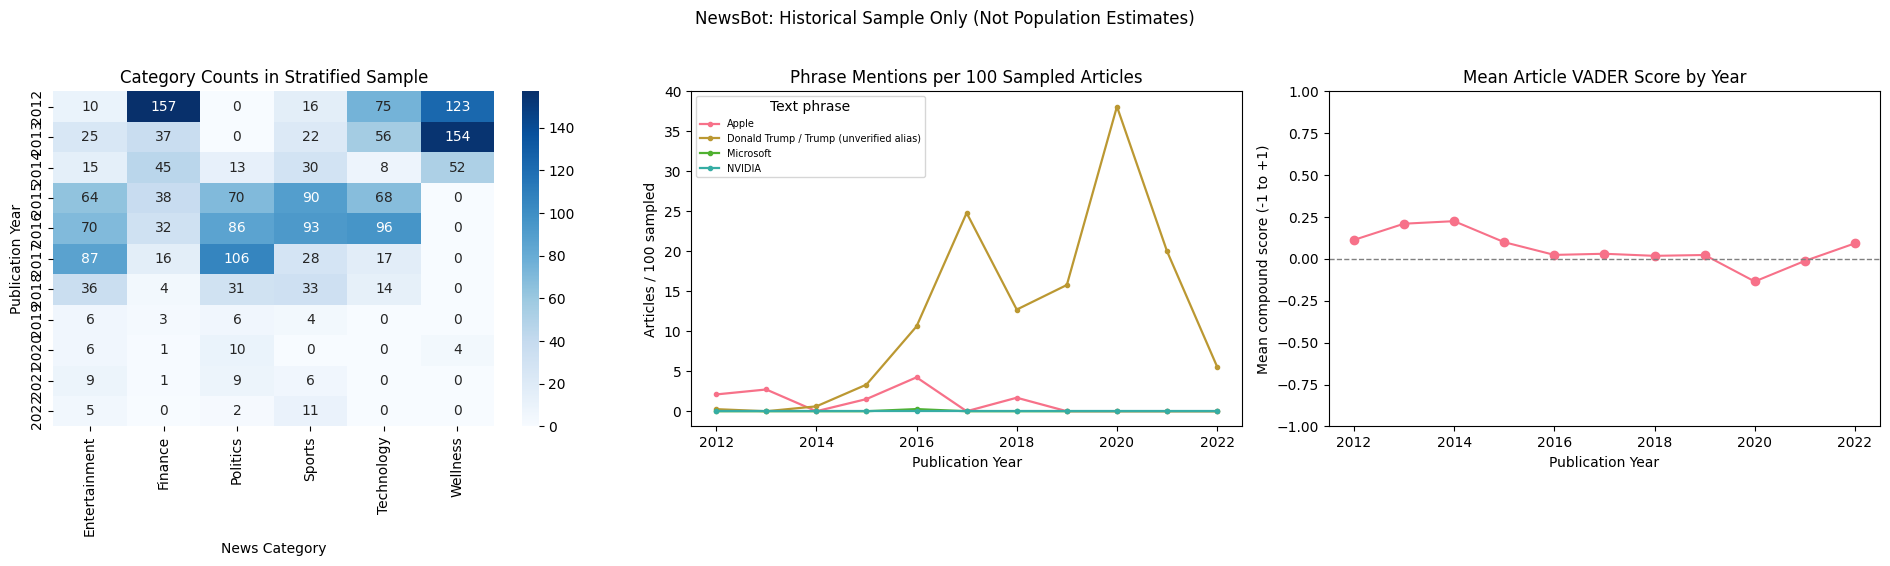


INTERPRETATION LIMITS:
- The 2,000 articles were stratified by original category, not by year.
- Historical variation may reflect sampling and original news coverage.
- Phrase matching does not resolve identity or establish relationships.
- VADER rates are article tone estimates, not public opinion.
Saved temporal tables and visualizations. Existing models unchanged.


In [23]:
# ============================================================
# EXTRA CREDIT 1 | TEMPORAL NEWS INTELLIGENCE (5 points possible)
# ITAI 2373 | Descriptive historical analysis, not forecasting
# ============================================================

print('=' * 68)
print('NEWSBOT EXTRA CREDIT | HISTORICAL NEWS AND ENTITY TRENDS')
print('=' * 68)

# Keep the original 2,000-article stratified dataset unchanged.
# Yearly sample counts are NOT estimates of overall HuffPost coverage.
required_temporal_cols = {'article_id', 'date', 'category', 'title', 'content'}
assert required_temporal_cols.issubset(df.columns)
assert {'article_id', 'full_sentiment'}.issubset(sentiment_df.columns)

temporal_articles = df[list(required_temporal_cols)].copy()
temporal_articles['date'] = pd.to_datetime(temporal_articles['date'], errors='coerce')
temporal_articles = temporal_articles.dropna(subset=['date'])
temporal_articles['year'] = temporal_articles['date'].dt.year
assert temporal_articles['article_id'].is_unique

# Link sentiment by article ID (rather than assuming identical row order).
temporal_articles = temporal_articles.merge(
    sentiment_df[['article_id', 'full_sentiment']],
    on='article_id', how='left', validate='one_to_one'
)
assert temporal_articles['full_sentiment'].notna().all()

annual_category_counts = (
    temporal_articles.groupby(['year', 'category']).size()
    .rename('sample_articles').reset_index()
)
annual_sample_size = temporal_articles.groupby('year').size()
annual_category_counts['annual_sample_total'] = (
    annual_category_counts['year'].map(annual_sample_size)
)
annual_category_counts['share_of_that_years_sample_pct'] = (
    100 * annual_category_counts['sample_articles'] /
    annual_category_counts['annual_sample_total']
)

# Exact-phrase mention search in original text, not potentially faulty NER.
# A reference is not proof of a person's identity, role, or relationship.
tracked_terms = {
    'NVIDIA': r'\bnvidia\b',
    'Apple': r'\bapple\b',
    'Microsoft': r'\bmicrosoft\b',
    'Donald Trump / Trump (unverified alias)': r"\b(?:donald\s+)?trump(?:'s)?\b",
}
original_text = (
    temporal_articles['title'].fillna('').astype(str) + ' ' +
    temporal_articles['content'].fillna('').astype(str)
)

entity_annual_records = []
for term, regex_pattern in tracked_terms.items():
    hit = original_text.str.contains(
        regex_pattern, regex=True, flags=re.IGNORECASE, na=False
    )
    for year, group in temporal_articles.groupby('year'):
        mentions = int(hit.loc[group.index].sum())
        entity_annual_records.append({
            'year': int(year),
            'tracked_phrase': term,
            'articles_mentioning_phrase': mentions,
            'sample_articles_that_year': len(group),
            'articles_per_100_sampled': round(100 * mentions / len(group), 2)
        })
entity_annual_df = pd.DataFrame(entity_annual_records)

annual_sentiment = (
    temporal_articles.groupby('year')
    .agg(sample_articles=('article_id', 'size'),
         mean_vader_compound=('full_sentiment', 'mean'))
    .reset_index()
)

print('\nARTICLE COUNTS BY HISTORICAL YEAR AND CATEGORY')
display(annual_category_counts.pivot(
    index='year', columns='category', values='sample_articles'
).fillna(0).astype(int))
print('\nTRACKED PHRASES IN ORIGINAL NEWS TEXT')
display(entity_annual_df.sort_values(
    ['tracked_phrase', 'year']
).head(30))
print('\nAVERAGE ARTICLE SENTIMENT BY HISTORICAL YEAR')
display(annual_sentiment.round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
category_plot = annual_category_counts.pivot(
    index='year', columns='category', values='sample_articles'
).fillna(0)
sns.heatmap(category_plot, annot=True, fmt='.0f', cmap='Blues', ax=axes[0])
axes[0].set_title('Category Counts in Stratified Sample')
axes[0].set_xlabel('News Category')
axes[0].set_ylabel('Publication Year')

phrase_plot = entity_annual_df.pivot(
    index='year', columns='tracked_phrase', values='articles_per_100_sampled'
).fillna(0)
phrase_plot.plot(ax=axes[1], marker='o', linewidth=1.6, markersize=3)
axes[1].set_title('Phrase Mentions per 100 Sampled Articles')
axes[1].set_xlabel('Publication Year')
axes[1].set_ylabel('Articles / 100 sampled')
axes[1].legend(title='Text phrase', fontsize=7)

axes[2].plot(annual_sentiment['year'],
             annual_sentiment['mean_vader_compound'], marker='o')
axes[2].axhline(0, color='grey', linestyle='--', linewidth=1)
axes[2].set_title('Mean Article VADER Score by Year')
axes[2].set_xlabel('Publication Year')
axes[2].set_ylabel('Mean compound score (-1 to +1)')
axes[2].set_ylim(-1, 1)

fig.suptitle('NewsBot: Historical Sample Only (Not Population Estimates)', y=1.02)
fig.tight_layout()
fig.savefig('newsbot_extra_temporal_dashboard.png', dpi=170, bbox_inches='tight')
plt.show()

annual_category_counts.to_csv('newsbot_extra_annual_category_counts.csv', index=False)
entity_annual_df.to_csv('newsbot_extra_entity_phrase_trends.csv', index=False)
annual_sentiment.to_csv('newsbot_extra_annual_sentiment.csv', index=False)

print('\nINTERPRETATION LIMITS:')
print('- The 2,000 articles were stratified by original category, not by year.')
print('- Historical variation may reflect sampling and original news coverage.')
print('- Phrase matching does not resolve identity or establish relationships.')
print('- VADER rates are article tone estimates, not public opinion.')
print('Saved temporal tables and visualizations. Existing models unchanged.')


### Extension B — Evaluated Entity Resolution Research

**Question:** Can a fixed, transparent domain lexicon correct some of the
entity-boundary and entity-label problems we observed (such as recognizing NVIDIA as
an organization or separating `FIFA` from an overly long detected entity)?

**Method:** Compare unmodified spaCy NER with the same model plus a **predeclared,
lexicon-based span correction and alias normalization layer**. Score both against
**20 hand-authored, manually labeled synthetic snippets**, using exact character
boundaries **and** entity type for micro-precision, micro-recall, and micro-F1.
No training or tuning is performed on the 400-article classification holdout set.

**Limitations:** This curated micro-evaluation deliberately includes familiar names
and is **not** an independent representative evaluation. The lexicon is not a new
trained model or factual identity verifier, and can misidentify ambiguous uses (such
as `Trump Tower`). Results demonstrate a *prototype experiment*, not reliable
real-world NER performance. Roles and relationships remain unresolved.


NEWSBOT RESEARCH EXTENSION | RULE-ASSISTED ENTITY RECOGNITION

STRICT EXACT-SPAN + ENTITY-TYPE EVALUATION
Hand-authored evaluation snippets: 20


,true_positive,false_positive,false_negative,precision,recall,strict_entity_f1
method,,,,,,
spaCy + fixed lexicon,26,1,1,0.963,0.963,0.963
spaCy baseline,19,5,8,0.792,0.704,0.745



EVALUATION EXAMPLES, INCLUDING KNOWN FAILURE MODES


,case,text,method,gold_count,predicted_count,true_positive,false_positive,false_negative
0,1,NVIDIA unveiled a graphics architecture.,spaCy baseline,1,0,0,0,1
1,1,NVIDIA unveiled a graphics architecture.,spaCy + fixed lexicon,1,1,1,0,0
2,2,NVIDIA shares declined after earnings.,spaCy baseline,1,0,0,0,1
3,2,NVIDIA shares declined after earnings.,spaCy + fixed lexicon,1,1,1,0,0
4,3,Donald Trump met Elon Musk.,spaCy baseline,2,2,2,0,0
5,3,Donald Trump met Elon Musk.,spaCy + fixed lexicon,2,2,2,0,0
6,4,President Trump commented on Amazon.,spaCy baseline,2,2,1,1,1
7,4,President Trump commented on Amazon.,spaCy + fixed lexicon,2,2,2,0,0
8,5,Mark Zuckerberg spoke at Meta.,spaCy baseline,2,2,2,0,0
9,5,Mark Zuckerberg spoke at Meta.,spaCy + fixed lexicon,2,2,2,0,0


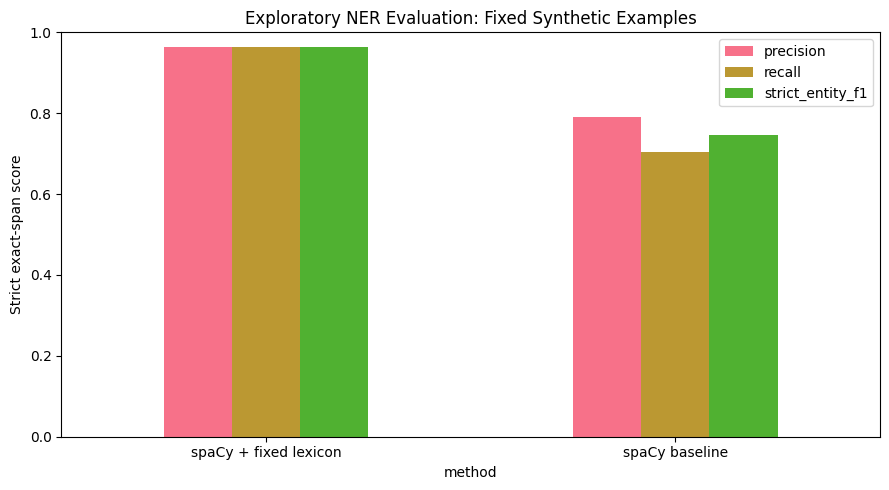


RESEARCH LIMITATIONS
- Hand-authored cases favor known names; these are not representative.
- Lexicon rules do not verify identity, occupation, or actual relationships.
- Missing/ambiguous/new entities remain difficult; inspect failures.
- Evaluation did NOT use classification holdout labels or fit a new model.
Baseline NER and the existing NewsBot classifier remain unchanged.


In [24]:
# ============================================================
# EXTRA CREDIT 2 | EVALUATED ENTITY-RESOLUTION RESEARCH
# ITAI 2373 | Fixed lexicon + transparent exploratory evaluation
# ============================================================

import re
from collections import Counter

print('=' * 68)
print('NEWSBOT RESEARCH EXTENSION | RULE-ASSISTED ENTITY RECOGNITION')
print('=' * 68)

# A fixed, transparent lexicon defined BEFORE running the comparison.
# This is not a trained custom NER model. Short forms such as "Trump"
# remain ambiguous in the real world and must be reviewed in context.
ENTITY_RULES = [
    ('Donald Trump', 'PERSON', ['Donald Trump', 'President Trump', 'Trump']),
    ('Elon Musk', 'PERSON', ['Elon Musk']),
    ('Jeff Bezos', 'PERSON', ['Jeff Bezos']),
    ('Mark Zuckerberg', 'PERSON', ['Mark Zuckerberg']),
    ('Satya Nadella', 'PERSON', ['Satya Nadella']),
    ('LeBron James', 'PERSON', ['LeBron James']),
    ('Microsoft', 'ORG', ['Microsoft Corporation', 'Microsoft']),
    ('NVIDIA', 'ORG', ['NVIDIA']),
    ('Apple', 'ORG', ['Apple']),
    ('Google', 'ORG', ['Google']),
    ('Amazon', 'ORG', ['Amazon']),
    ('Tesla', 'ORG', ['Tesla']),
    ('Meta', 'ORG', ['Meta']),
    ('FIFA', 'ORG', ['FIFA']),
    ('NBA', 'ORG', ['NBA']),
    ('NFL', 'ORG', ['NFL']),
    ('FBI', 'ORG', ['FBI']),
    ('United Nations', 'ORG', ['United Nations']),
    ('Twitter', 'ORG', ['Twitter']),
    ('Shape.com', 'ORG', ['Shape.com']),
    ('World Cup', 'EVENT', ['2026 World Cup', 'FIFA World Cup', 'World Cup']),
    ('United States', 'GPE', ['United States', 'U.S.']),
]

_RULE_PATTERNS = []
for canonical, label, aliases in ENTITY_RULES:
    for alias in aliases:
        regex = re.compile(
            r'(?<!\w)' + re.escape(alias) + r'(?!\w)', flags=re.IGNORECASE
        )
        _RULE_PATTERNS.append((alias, canonical, label, regex))
_RULE_PATTERNS.sort(key=lambda rule: len(rule[0]), reverse=True)


def rule_assisted_entities(text, baseline_doc=None):
    """Return NER spans with conservative fixed-phrase overrides.

    Overlapping baseline spans are replaced by exact lexicon spans,
    correcting some overly broad boundaries and labels. The result
    still requires manual validation for ambiguous names/contexts.
    """
    text = str(text)
    doc = baseline_doc if baseline_doc is not None else nlp(text)
    rule_hits = []
    for alias, canonical, label, pattern in _RULE_PATTERNS:
        for match in pattern.finditer(text):
            if any(not (match.end() <= hit['start'] or
                        match.start() >= hit['end']) for hit in rule_hits):
                continue
            rule_hits.append({
                'text': text[match.start():match.end()],
                'label': label,
                'start': match.start(),
                'end': match.end(),
                'canonical_name': canonical,
                'recognition_method': 'fixed_lexicon'
            })

    retained = []
    for ent in doc.ents:
        if any(not (ent.end_char <= hit['start'] or
                    ent.start_char >= hit['end']) for hit in rule_hits):
            continue
        retained.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'canonical_name': None,
            'recognition_method': 'spacy_baseline'
        })
    return sorted(rule_hits + retained, key=lambda item: (item['start'], item['end']))


def _gold_spans(text, annotations):
    """Locate manually declared exact mentions; fail on a bad annotation."""
    spans = set()
    for phrase, label in annotations:
        start = text.find(phrase)
        if start < 0:
            raise ValueError(f'Gold mention {phrase!r} not found in {text!r}')
        spans.add((start, start + len(phrase), label))
    return spans


# Hand-authored, labeled synthetic evaluation snippets; NOT the 400 held-out
# classification articles. No model fitting or lexicon updates are performed.
# Small examples show feasibility, not production NER accuracy.
NER_EVAL_CASES = [
    ('NVIDIA unveiled a graphics architecture.', [('NVIDIA', 'ORG')]),
    ('NVIDIA shares declined after earnings.', [('NVIDIA', 'ORG')]),
    ('Donald Trump met Elon Musk.', [('Donald Trump', 'PERSON'), ('Elon Musk', 'PERSON')]),
    ('President Trump commented on Amazon.', [('President Trump', 'PERSON'), ('Amazon', 'ORG')]),
    ('Mark Zuckerberg spoke at Meta.', [('Mark Zuckerberg', 'PERSON'), ('Meta', 'ORG')]),
    ('Jeff Bezos discussed a new investment.', [('Jeff Bezos', 'PERSON')]),
    ('FIFA announced World Cup plans.', [('FIFA', 'ORG'), ('World Cup', 'EVENT')]),
    ('The United Nations issued a statement.', [('United Nations', 'ORG')]),
    ('Satya Nadella presented Microsoft software.', [('Satya Nadella', 'PERSON'), ('Microsoft', 'ORG')]),
    ('Apple and Google announced an initiative.', [('Apple', 'ORG'), ('Google', 'ORG')]),
    ('The FBI interviewed a Twitter executive.', [('FBI', 'ORG'), ('Twitter', 'ORG')]),
    ('LeBron James discussed the NBA season.', [('LeBron James', 'PERSON'), ('NBA', 'ORG')]),
    ('U.S. officials reviewed new rules.', [('U.S.', 'GPE')]),
    ('Elon Musk discussed Tesla finances.', [('Elon Musk', 'PERSON'), ('Tesla', 'ORG')]),
    ('Shape.com published a wellness article.', [('Shape.com', 'ORG')]),
    ('The 2026 World Cup attracted attention.', [('2026 World Cup', 'EVENT')]),
    ('An engineer studied artificial intelligence.', []),
    ('The company reported financial results.', []),
    # Deliberately ambiguous: "Trump" may be part of a landmark name.
    ('Trump Tower opened to visitors.', [('Trump Tower', 'FAC')]),
    # Open-domain item outside the fixed dictionary.
    ('A researcher visited Paris.', [('Paris', 'GPE')]),
]

ner_evaluation_records = []
for case_no, (text, annotations) in enumerate(NER_EVAL_CASES, start=1):
    gold = _gold_spans(text, annotations)
    doc = nlp(text)
    baseline = {(ent.start_char, ent.end_char, ent.label_) for ent in doc.ents}
    enhanced = {
        (ent['start'], ent['end'], ent['label'])
        for ent in rule_assisted_entities(text, baseline_doc=doc)
    }
    for method, predicted in [('spaCy baseline', baseline),
                              ('spaCy + fixed lexicon', enhanced)]:
        ner_evaluation_records.append({
            'case': case_no,
            'text': text,
            'method': method,
            'gold_count': len(gold),
            'predicted_count': len(predicted),
            'true_positive': len(predicted & gold),
            'false_positive': len(predicted - gold),
            'false_negative': len(gold - predicted),
            'gold_spans': sorted(gold),
            'predicted_spans': sorted(predicted),
        })
ner_research_cases_df = pd.DataFrame(ner_evaluation_records)

ner_research_metrics = (
    ner_research_cases_df.groupby('method')
    [['true_positive', 'false_positive', 'false_negative']].sum()
)
ner_research_metrics['precision'] = (
    ner_research_metrics['true_positive'] /
    (ner_research_metrics['true_positive'] + ner_research_metrics['false_positive'])
    .replace(0, np.nan)
).fillna(0)
ner_research_metrics['recall'] = (
    ner_research_metrics['true_positive'] /
    (ner_research_metrics['true_positive'] + ner_research_metrics['false_negative'])
    .replace(0, np.nan)
).fillna(0)
ner_research_metrics['strict_entity_f1'] = (
    2 * ner_research_metrics['precision'] * ner_research_metrics['recall'] /
    (ner_research_metrics['precision'] + ner_research_metrics['recall'])
    .replace(0, np.nan)
).fillna(0)

print('\nSTRICT EXACT-SPAN + ENTITY-TYPE EVALUATION')
print(f'Hand-authored evaluation snippets: {len(NER_EVAL_CASES)}')
display(ner_research_metrics.round(3))
print('\nEVALUATION EXAMPLES, INCLUDING KNOWN FAILURE MODES')
display(ner_research_cases_df[
    ['case', 'text', 'method', 'gold_count', 'predicted_count',
     'true_positive', 'false_positive', 'false_negative']
].head(18))

ax = ner_research_metrics[['precision', 'recall', 'strict_entity_f1']].plot(
    kind='bar', figsize=(9, 5), ylim=(0, 1), rot=0
)
ax.set_title('Exploratory NER Evaluation: Fixed Synthetic Examples')
ax.set_ylabel('Strict exact-span score')
plt.tight_layout()
plt.savefig('newsbot_extra_entity_research.png', dpi=175, bbox_inches='tight')
plt.show()

ner_research_metrics.to_csv('newsbot_extra_ner_comparison.csv')
ner_research_cases_df.to_csv('newsbot_extra_ner_case_audit.csv', index=False)

print('\nRESEARCH LIMITATIONS')
print('- Hand-authored cases favor known names; these are not representative.')
print('- Lexicon rules do not verify identity, occupation, or actual relationships.')
print('- Missing/ambiguous/new entities remain difficult; inspect failures.')
print('- Evaluation did NOT use classification holdout labels or fit a new model.')
print('Baseline NER and the existing NewsBot classifier remain unchanged.')


## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [25]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# FINAL SYSTEM INTEGRATION
# ITAI 2373 Natural Language Processing
# ============================================================

# Dependencies from earlier modules:
# - preprocess_text()                  Module 2
# - analyze_pos_patterns()             Module 4
# - extract_syntactic_features()       Module 5
# - analyze_sentiment()                Module 6
# - best_model                          Module 7
# - numeric_feature_columns            Module 7
# - text_feature_column                Module 7
# - nlp                                 Modules 5 and 8

class NewsBotIntelligenceSystem:
    """
    Integrated news intelligence application.

    Capabilities:
    1. Text preprocessing
    2. Classification feature engineering
    3. News category prediction
    4. Named entity recognition
    5. Sentiment analysis
    6. POS and syntax analysis
    7. Evidence-aware insight generation

    Uses the fitted classification Pipeline from Module 7.
    Does not refit TF-IDF or use placeholder features.
    """

    # --------------------------------------------------------
    # 1. INITIALIZE SYSTEM
    # --------------------------------------------------------

    def __init__(self, classifier, spacy_pipeline):

        self.classifier = classifier
        self.nlp = spacy_pipeline

        self.categories = list(classifier.classes_)

        self.text_column = text_feature_column
        self.numeric_columns = list(numeric_feature_columns)

        # Preserve information about the selected model.
        self.model_name = best_model_name
        self.feature_configuration = best_configuration

        # Validate the fitted classification pipeline.
        if "features" not in classifier.named_steps:
            raise ValueError(
                "NewsBot requires the fitted feature pipeline "
                "created during classification training."
            )

        if "classifier" not in classifier.named_steps:
            raise ValueError(
                "No trained classifier found in the pipeline."
            )

        if len(self.categories) != 6:
            raise ValueError(
                "NewsBot expects six classification categories."
            )

        if not self.nlp.has_pipe("ner"):
            raise ValueError(
                "spaCy named entity recognition is unavailable."
            )

        if not self.nlp.has_pipe("parser"):
            raise ValueError(
                "spaCy dependency parsing is unavailable."
            )

    # --------------------------------------------------------
    # 2. PREPROCESS NEW ARTICLE
    # --------------------------------------------------------

    def preprocess_article(self, title, content):
        """
        Normalize article text for classification.

        Original text is preserved for NER, sentiment,
        grammatical analysis, and display.
        """

        title = "" if title is None else str(title).strip()
        content = "" if content is None else str(content).strip()

        full_text = f"{title} {content}".strip()

        if not full_text:
            raise ValueError(
                "Article must contain a headline or description."
            )

        processed_text = preprocess_text(full_text)

        if not processed_text:
            raise ValueError(
                "Article contains no usable classification tokens."
            )

        return full_text, processed_text

    # --------------------------------------------------------
    # 3. EXTRACT NAMED ENTITIES
    # --------------------------------------------------------

    def extract_entities(self, doc):
        """
        Extract entities from an existing spaCy document.

        The model identifies probable mentions.
        Entity identity and labels are not verified facts.
        """

        return [
            {
                "text": ent.text,
                "label": ent.label_,
                "start": ent.start_char,
                "end": ent.end_char,
                "description": (
                    spacy.explain(ent.label_)
                    or "Unknown entity type"
                )
            }
            for ent in doc.ents
        ]

    # --------------------------------------------------------
    # 4. CALCULATE SENTIMENT
    # --------------------------------------------------------

    def analyze_article_sentiment(
        self, title, content, full_text
    ):
        """
        Evaluate headline, description, and combined text.

        Uses VADER on original text, preserving negation
        and other sentiment-relevant language.
        """

        return {
            "title": analyze_sentiment(title),
            "description": analyze_sentiment(content),
            "combined": analyze_sentiment(full_text)
        }

    # --------------------------------------------------------
    # 5. CONSTRUCT CLASSIFICATION INPUT
    # --------------------------------------------------------

    def build_features(
        self,
        title,
        content,
        full_text,
        processed_text,
        sentiment_results,
        pos_results,
        syntax_results
    ):
        """
        Reproduce the feature engineering performed in
        Cell 24 for one new article.

        The fitted scikit-learn Pipeline handles TF-IDF
        transformation and any learned feature scaling.
        """

        title_sentiment = sentiment_results["title"]
        content_sentiment = sentiment_results["description"]
        combined_sentiment = sentiment_results["combined"]

        # Aggregate Penn Treebank POS proportions.
        pos_feature_groups = {
            "pos_common_nouns": ["NN", "NNS"],
            "pos_proper_nouns": ["NNP", "NNPS"],
            "pos_verbs": [
                "VB", "VBD", "VBG",
                "VBN", "VBP", "VBZ"
            ],
            "pos_adjectives": ["JJ", "JJR", "JJS"],
            "pos_adverbs": ["RB", "RBR", "RBS"],
            "pos_numbers": ["CD"]
        }

        pos_features = {}

        for feature_name, tags in pos_feature_groups.items():
            pos_features[feature_name] = sum(
                pos_results.get(tag, 0.0)
                for tag in tags
            )

        # Exact numerical feature definitions from Cell 24.
        feature_values = {
            self.text_column: processed_text,

            # Sentiment features
            "sentiment_title": (
                title_sentiment["compound"] + 1
            ) / 2,

            "sentiment_description": (
                content_sentiment["compound"] + 1
            ) / 2,

            "sentiment_combined": (
                combined_sentiment["compound"] + 1
            ) / 2,

            "sentiment_positive": combined_sentiment["pos"],
            "sentiment_neutral": combined_sentiment["neu"],
            "sentiment_negative": combined_sentiment["neg"],

            # Text length features
            "length_characters": np.log1p(
                len(full_text)
            ),

            "length_words": np.log1p(
                len(full_text.split())
            ),

            "length_headline": np.log1p(
                len(title)
            ),

            # POS features
            **pos_features,

            # Syntactic features
            "num_sentences": np.log1p(
                syntax_results["num_sentences"]
            ),

            "num_svo_patterns": np.log1p(
                syntax_results["num_svo_patterns"]
            ),

            "avg_sentence_length": np.log1p(
                syntax_results["avg_sentence_length"]
            ),

            "avg_dependency_distance": (
                syntax_results["avg_dependency_distance"]
            )
        }

        # Check that the new article has every feature
        # required by the enhanced classifier.
        required_columns = (
            [self.text_column] + self.numeric_columns
        )

        missing_features = [
            feature
            for feature in required_columns
            if feature not in feature_values
        ]

        if missing_features:
            raise ValueError(
                f"Missing classification features: "
                f"{missing_features}"
            )

        feature_df = pd.DataFrame(
            [feature_values]
        )[required_columns]

        # No NaN or infinite numerical values.
        numerical_values = feature_df[
            self.numeric_columns
        ].to_numpy(dtype=float)

        if not np.isfinite(numerical_values).all():
            raise ValueError(
                "Invalid numerical classification features."
            )

        return feature_df

    # --------------------------------------------------------
    # 6. CLASSIFY NEW ARTICLE
    # --------------------------------------------------------

    def classify_article(self, features):
        """
        Predict category using the fitted pipeline.

        Probabilities are model estimates and are not
        assumed to be perfectly calibrated.
        """

        prediction = self.classifier.predict(
            features
        )[0]

        probabilities = self.classifier.predict_proba(
            features
        )[0]

        category_probabilities = {
            str(category): float(probability)
            for category, probability in zip(
                self.classifier.classes_,
                probabilities
            )
        }

        return str(prediction), category_probabilities

    # --------------------------------------------------------
    # 7. GENERATE INTERPRETABLE INSIGHTS
    # --------------------------------------------------------

    def generate_insights(
        self,
        category,
        category_probs,
        sentiment,
        entities,
        syntax
    ):
        """
        Generate descriptive insights and review flags.

        Insights are derived from model output.
        They are not independently verified news facts.
        """

        insights = []

        ranked_categories = sorted(
            category_probs.items(),
            key=lambda item: item[1],
            reverse=True
        )

        top_category, top_probability = ranked_categories[0]

        second_category, second_probability = (
            ranked_categories[1]
        )

        probability_margin = (
            top_probability - second_probability
        )

        # Category interpretation
        insights.append(
            f"Primary predicted topic: {top_category}."
        )

        insights.append(
            f"Second-ranked topic: {second_category} "
            f"(estimated probability {second_probability:.1%})."
        )

        # Heuristic review flag, not calibrated confidence.
        if probability_margin < 0.15:

            insights.append(
                "Category predictions are relatively close. "
                "Manual review may help determine the "
                "article's primary subject."
            )

        # Sentiment interpretation
        sentiment_label = sentiment["sentiment_label"]
        compound_score = sentiment["compound"]

        insights.append(
            f"Estimated article sentiment: "
            f"{sentiment_label} "
            f"(VADER score {compound_score:+.3f})."
        )

        # Named entity insights
        important_entities = [
            entity
            for entity in entities
            if entity["label"] in {
                "PERSON", "ORG", "GPE"
            }
        ]

        unique_names = []
        seen_names = set()

        for entity in important_entities:

            name = entity["text"].strip()
            key = name.casefold()

            if key not in seen_names:
                unique_names.append(name)
                seen_names.add(key)

        if unique_names:

            insights.append(
                "Detected people, organizations, or places: "
                + ", ".join(unique_names[:5])
                + "."
            )

        else:

            insights.append(
                "No people, organizations, or places "
                "were identified."
            )

        # Numerical and financial entity mentions
        money_entities = [
            entity["text"]
            for entity in entities
            if entity["label"] == "MONEY"
        ]

        if money_entities:

            insights.append(
                "Monetary references detected: "
                + ", ".join(money_entities[:3])
                + "."
            )

        # Syntax interpretation
        svo_count = syntax["num_svo_patterns"]

        insights.append(
            f"Extracted {svo_count} potential "
            "subject-verb-object relationship(s)."
        )

        # Reliability disclosure
        insights.append(
            "Entity labels, category predictions, "
            "and syntactic relationships are automated "
            "estimates that may require verification."
        )

        return insights

    # --------------------------------------------------------
    # 8. COMPLETE ARTICLE PROCESSING PIPELINE
    # --------------------------------------------------------

    def process_article(self, title, content):
        """
        Process one news article through NewsBot.

        Returns:
        - Article information
        - Preprocessed text
        - Predicted category and probabilities
        - NER results
        - Sentiment results
        - POS and syntax information
        - Descriptive insights
        """

        # Stage 1: Preprocessing
        full_text, processed_text = (
            self.preprocess_article(title, content)
        )

        title = "" if title is None else str(title).strip()
        content = "" if content is None else str(content).strip()

        # Stage 2: Linguistic analysis
        # Parse original text once with spaCy.
        doc = self.nlp(full_text)

        pos_results = analyze_pos_patterns(full_text)

        syntax_results = extract_syntactic_features(
            full_text,
            doc=doc
        )

        # Stage 3: Sentiment analysis
        sentiment_results = (
            self.analyze_article_sentiment(
                title,
                content,
                full_text
            )
        )

        # Stage 4: Classification features
        features = self.build_features(
            title=title,
            content=content,
            full_text=full_text,
            processed_text=processed_text,
            sentiment_results=sentiment_results,
            pos_results=pos_results,
            syntax_results=syntax_results
        )

        # Stage 5: Classification
        category, category_probs = (
            self.classify_article(features)
        )

        # Stage 6: Named entity recognition
        entities = self.extract_entities(doc)

        # Stage 7: Insight generation
        insights = self.generate_insights(
            category=category,
            category_probs=category_probs,
            sentiment=sentiment_results["combined"],
            entities=entities,
            syntax=syntax_results
        )

        # Preserve the interface used by the professor's
        # original integration test cell.
        predicted_probability = category_probs[category]

        return {
            "title": title,
            "content": content,
            "full_text": full_text,
            "processed_text": processed_text,

            "predicted_category": category,
            "category_confidence": predicted_probability,
            "category_probabilities": category_probs,

            "probability_warning": (
                "Class probabilities are model estimates, "
                "not independently calibrated confidence."
            ),

            "entities": entities,
            "entity_count": len(entities),

            "sentiment": sentiment_results["combined"],
            "sentiment_details": sentiment_results,

            "pos_features": pos_results,

            "syntactic_features": {
                "num_sentences": (
                    syntax_results["num_sentences"]
                ),
                "num_noun_phrases": (
                    syntax_results["num_noun_phrases"]
                ),
                "num_svo_patterns": (
                    syntax_results["num_svo_patterns"]
                ),
                "avg_sentence_length": (
                    syntax_results["avg_sentence_length"]
                ),
                "avg_dependency_distance": (
                    syntax_results["avg_dependency_distance"]
                ),
                "sample_svo_patterns": (
                    syntax_results["svo_patterns"][:5]
                )
            },

            "insights": insights,
            "model_name": self.model_name,
            "feature_configuration": (
                self.feature_configuration
            )
        }


# ============================================================
# 9. INITIALIZE NEWSBOT
# ============================================================

newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    spacy_pipeline=nlp
)

print("=" * 60)
print("NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

print("Integrated application initialized.")
print(f"Classification model: {newsbot.model_name}")
print(
    f"Feature configuration: "
    f"{newsbot.feature_configuration}"
)

print(f"Available categories: {len(newsbot.categories)}")

print("\nIntegrated capabilities:")
print("1. Text preprocessing")
print("2. Classification feature engineering")
print("3. News classification")
print("4. Named entity recognition")
print("5. VADER sentiment analysis")
print("6. POS and dependency analysis")
print("7. Descriptive insight generation")

print("\nStatus: Ready for prototype testing.")


NEWSBOT INTELLIGENCE SYSTEM
Integrated application initialized.
Classification model: TF-IDF | Naive Bayes
Feature configuration: TF-IDF
Available categories: 6

Integrated capabilities:
1. Text preprocessing
2. Classification feature engineering
3. News classification
4. Named entity recognition
5. VADER sentiment analysis
6. POS and dependency analysis
7. Descriptive insight generation

Status: Ready for prototype testing.


In [26]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# FINAL INTEGRATION - END-TO-END SYSTEM TESTING
# ITAI 2373 Natural Language Processing
# ============================================================

print("=" * 65)
print("NEWSBOT INTELLIGENCE SYSTEM - INTEGRATION TESTING")
print("=" * 65)

print(f"Model: {newsbot.model_name}")
print(f"Categories: {len(newsbot.categories)}")
print("Test mode: Illustrative demonstration scenarios")

# ------------------------------------------------------------
# 1. DEFINE DEMONSTRATION ARTICLES
# ------------------------------------------------------------

# These are illustrative examples, not verified news.
# Expected topics are human interpretations only.
# They are NOT used as training or benchmark data.

test_articles = [
    {
        "title": "Microsoft Acquires AI Startup for $2 Billion",
        "content": (
            "Microsoft Corporation announced an acquisition "
            "of an artificial intelligence startup for "
            "$2 billion. CEO Satya Nadella said the deal "
            "would strengthen Microsoft's position in "
            "the AI market and cloud computing."
        ),
        "expected_topic": "Finance",
        "scenario": "Professor example: Technology and Finance"
    },
    {
        "title": "Lakers Win Championship in Overtime Thriller",
        "content": (
            "The Los Angeles Lakers defeated the Boston "
            "Celtics 108-102 in overtime to win the NBA "
            "championship. LeBron James scored 35 points "
            "and was named Finals MVP."
        ),
        "expected_topic": "Sports",
        "scenario": "Professor example: Sports"
    },
    {
        "title": "New Climate Change Report Shows Alarming Trends",
        "content": (
            "Scientists at the United Nations released "
            "a climate report showing accelerating global "
            "warming. The report calls for action to "
            "address environmental changes."
        ),
        "expected_topic": None,
        "scenario": "Professor example: Out-of-scope topic"
    },
    {
        "title": "NVIDIA Introduces New GPU Architecture",
        "content": (
            "NVIDIA engineers unveiled a new graphics "
            "processor architecture designed to improve "
            "AI training and computing performance. "
            "The technology introduces updated memory "
            "and processing capabilities."
        ),
        "expected_topic": "Technology",
        "scenario": "Technology product development"
    },
    {
        "title": "NVIDIA Shares Rise Following Earnings Report",
        "content": (
            "NVIDIA shares increased after the company "
            "reported stronger quarterly revenue and "
            "earnings. Investors evaluated its financial "
            "performance, stock valuation, and projected "
            "profit growth."
        ),
        "expected_topic": "Finance",
        "scenario": "Technology company, financial focus"
    },
    {
        "title": "FIFA Reviews Immigration Policy Ahead of World Cup",
        "content": (
            "FIFA officials discussed how United States "
            "immigration rules could affect international "
            "teams and supporters traveling to the "
            "World Cup. Government policies may influence "
            "access to the sporting event."
        ),
        "expected_topic": "Sports",
        "scenario": "Sports and political policy overlap"
    },
    {
        "title": "Researchers Study Sleep and Heart Health",
        "content": (
            "Researchers examined how sleeping habits "
            "and regular exercise affect cardiovascular "
            "health. The study discusses lifestyle "
            "changes associated with improved wellness."
        ),
        "expected_topic": "Wellness",
        "scenario": "Health and wellness"
    }
]

# ------------------------------------------------------------
# 2. PROCESS ARTICLES THROUGH THE COMPLETE PIPELINE
# ------------------------------------------------------------

integration_results = []
integration_summary = []

for index, article in enumerate(test_articles, start=1):

    print("\n" + "=" * 65)
    print(f"TEST ARTICLE {index} OF {len(test_articles)}")
    print("=" * 65)

    print(f"\nScenario: {article['scenario']}")
    print(f"Headline: {article['title']}")

    try:

        # Complete integrated NLP pipeline
        result = newsbot.process_article(
            title=article["title"],
            content=article["content"]
        )

        integration_results.append(result)

        # ----------------------------------------------------
        # A. CLASSIFICATION OUTPUT
        # ----------------------------------------------------

        print("\nCLASSIFICATION")
        print("-" * 45)

        print(
            f"Predicted category: "
            f"{result['predicted_category']}"
        )

        print(
            f"Top model probability: "
            f"{result['category_confidence']:.2%}"
        )

        ranked_categories = sorted(
            result["category_probabilities"].items(),
            key=lambda item: item[1],
            reverse=True
        )

        print("\nCategory probability estimates:")

        for category, probability in ranked_categories:

            print(
                f"  {category:<16} {probability:.2%}"
            )

        expected = article["expected_topic"]

        if expected is None:

            comparison = "Out-of-scope review"

            print(
                "\nNo single predefined NewsBot category "
                "fully represents this article's topic."
            )

        elif result["predicted_category"] == expected:

            comparison = "Matches illustrative topic"

            print(
                f"\nHuman-assigned primary topic: {expected}"
            )

        else:

            comparison = "Review category difference"

            print(
                f"\nHuman-assigned primary topic: {expected}"
            )

            print(
                "Prediction differs from the illustrative "
                "primary-topic assignment."
            )

        # ----------------------------------------------------
        # B. SENTIMENT ANALYSIS
        # ----------------------------------------------------

        sentiment = result["sentiment"]

        print("\nSENTIMENT ANALYSIS")
        print("-" * 45)

        print(
            f"Sentiment label: "
            f"{sentiment['sentiment_label']}"
        )

        print(
            f"VADER compound score: "
            f"{sentiment['compound']:+.4f}"
        )

        print(
            f"Positive component: {sentiment['pos']:.3f}"
        )

        print(
            f"Neutral component: {sentiment['neu']:.3f}"
        )

        print(
            f"Negative component: {sentiment['neg']:.3f}"
        )

        # ----------------------------------------------------
        # C. NAMED ENTITY RECOGNITION
        # ----------------------------------------------------

        print("\nNAMED ENTITY RECOGNITION")
        print("-" * 45)

        entities = result["entities"]

        print(f"Entity mentions: {len(entities)}")

        if entities:

            for entity in entities[:10]:

                print(
                    f"  {entity['text']} "
                    f"({entity['label']})"
                )

            if len(entities) > 10:

                print(
                    f"  ...and {len(entities) - 10} "
                    "additional mentions"
                )

        else:

            print("No named entities detected.")

        # ----------------------------------------------------
        # D. SYNTACTIC ANALYSIS
        # ----------------------------------------------------

        syntax = result["syntactic_features"]

        print("\nSYNTACTIC ANALYSIS")
        print("-" * 45)

        print(
            f"Sentences: "
            f"{syntax['num_sentences']}"
        )

        print(
            f"Noun phrases: "
            f"{syntax['num_noun_phrases']}"
        )

        print(
            f"SVO patterns: "
            f"{syntax['num_svo_patterns']}"
        )

        print(
            f"Average sentence length: "
            f"{syntax['avg_sentence_length']:.2f}"
        )

        print(
            f"Average dependency distance: "
            f"{syntax['avg_dependency_distance']:.2f}"
        )

        # ----------------------------------------------------
        # E. INTEGRATED INTELLIGENCE INSIGHTS
        # ----------------------------------------------------

        print("\nNEWSBOT GENERATED INSIGHTS")
        print("-" * 45)

        for insight in result["insights"]:

            print(f"  - {insight}")

        # ----------------------------------------------------
        # F. RECORD TEST SUMMARY
        # ----------------------------------------------------

        probability_margin = (
            ranked_categories[0][1] -
            ranked_categories[1][1]
        )

        integration_summary.append({
            "Test": index,
            "Scenario": article["scenario"],
            "Expected Topic": (
                expected if expected is not None
                else "Outside six-category scope"
            ),
            "Predicted Category": (
                result["predicted_category"]
            ),
            "Top Probability": (
                result["category_confidence"]
            ),
            "Probability Margin": probability_margin,
            "Sentiment": sentiment["sentiment_label"],
            "Entities": len(entities),
            "SVO Patterns": syntax["num_svo_patterns"],
            "Review Status": comparison,
            "Execution": "Passed"
        })

    except Exception as error:

        integration_summary.append({
            "Test": index,
            "Scenario": article["scenario"],
            "Expected Topic": (
                article["expected_topic"]
                if article["expected_topic"] is not None
                else "Outside six-category scope"
            ),
            "Predicted Category": None,
            "Top Probability": None,
            "Probability Margin": None,
            "Sentiment": None,
            "Entities": None,
            "SVO Patterns": None,
            "Review Status": "Execution failure",
            "Execution": "Failed"
        })

        print(
            f"\nTEST FAILED: {type(error).__name__}: {error}"
        )

# ------------------------------------------------------------
# 3. INTEGRATION TEST SUMMARY
# ------------------------------------------------------------

integration_summary_df = pd.DataFrame(
    integration_summary
)

print("\n" + "=" * 65)
print("NEWSBOT INTEGRATION TEST SUMMARY")
print("=" * 65)

display(
    integration_summary_df.round(4)
)

successful_tests = (
    integration_summary_df["Execution"] == "Passed"
).sum()

failed_tests = (
    integration_summary_df["Execution"] == "Failed"
).sum()

print(
    f"\nSuccessful executions: "
    f"{successful_tests}/{len(test_articles)}"
)

print(f"Failed executions: {failed_tests}")

# ------------------------------------------------------------
# 4. AUTOMATED FUNCTIONAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("END-TO-END FUNCTIONAL VALIDATION")
print("=" * 65)

assert failed_tests == 0, (
    "One or more integration tests failed."
)

assert len(integration_results) == len(test_articles), (
    "Not all articles were processed."
)

required_result_keys = {
    "predicted_category",
    "category_probabilities",
    "entities",
    "sentiment",
    "pos_features",
    "syntactic_features",
    "insights"
}

for result in integration_results:

    assert required_result_keys.issubset(
        result.keys()
    ), "Missing integration output fields."

    assert result["predicted_category"] in class_names

    assert np.isclose(
        sum(result["category_probabilities"].values()),
        1.0,
        atol=0.001
    ), "Category probabilities do not sum to one."

    assert isinstance(result["entities"], list)

    assert isinstance(result["insights"], list)

    assert len(result["insights"]) > 0

    assert -1 <= result["sentiment"]["compound"] <= 1

print("Article preprocessing: Passed")
print("Classification inference: Passed")
print("Probability validation: Passed")
print("Named entity extraction: Passed")
print("Sentiment analysis: Passed")
print("POS and syntax analysis: Passed")
print("Insight generation: Passed")

# ------------------------------------------------------------
# 5. TEST INVALID INPUT HANDLING
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("INVALID INPUT HANDLING")
print("=" * 65)

empty_input_rejected = False

try:

    newsbot.process_article("", "")

except ValueError:

    empty_input_rejected = True

assert empty_input_rejected, (
    "NewsBot did not reject an empty article."
)

print("Empty article rejection: Passed")

# ------------------------------------------------------------
# 6. SAVE DEMONSTRATION RESULTS
# ------------------------------------------------------------

integration_summary_df.to_csv(
    "newsbot_integration_test_results.csv",
    index=False
)

print("\n" + "=" * 65)
print("NEWSBOT INTEGRATION TESTING COMPLETE")
print("=" * 65)

print("All functional integration checks passed.")
print("Model performance remains based on the held-out test set.")
print("Demonstration examples are not benchmark accuracy results.")
print("Results saved: newsbot_integration_test_results.csv")


NEWSBOT INTELLIGENCE SYSTEM - INTEGRATION TESTING
Model: TF-IDF | Naive Bayes
Categories: 6
Test mode: Illustrative demonstration scenarios

TEST ARTICLE 1 OF 7

Scenario: Professor example: Technology and Finance
Headline: Microsoft Acquires AI Startup for $2 Billion

CLASSIFICATION
---------------------------------------------
Predicted category: Technology
Top model probability: 43.45%

Category probability estimates:
  Technology       43.45%
  Finance          22.97%
  Politics         11.17%
  Wellness         8.82%
  Sports           7.08%
  Entertainment    6.51%

Human-assigned primary topic: Finance
Prediction differs from the illustrative primary-topic assignment.

SENTIMENT ANALYSIS
---------------------------------------------
Sentiment label: positive
VADER compound score: +0.6597
Positive component: 0.134
Neutral component: 0.866
Negative component: 0.000

NAMED ENTITY RECOGNITION
---------------------------------------------
Entity mentions: 7
  Microsoft Acquires (ORG)

,Test,Scenario,Expected Topic,Predicted Category,Top Probability,Probability Margin,Sentiment,Entities,SVO Patterns,Review Status,Execution
0,1,Professor example: Technology and Finance,Finance,Technology,0.4345,0.2048,positive,7,2,Review category difference,Passed
1,2,Professor example: Sports,Sports,Sports,0.6252,0.5212,positive,6,2,Matches illustrative topic,Passed
2,3,Professor example: Out-of-scope topic,Outside six-category scope,Technology,0.2860,0.0711,positive,2,1,Out-of-scope review,Passed
3,4,Technology product development,Technology,Technology,0.2531,0.0401,positive,0,2,Matches illustrative topic,Passed
4,5,"Technology company, financial focus",Finance,Finance,0.3893,0.1195,positive,1,2,Matches illustrative topic,Passed
5,6,Sports and political policy overlap,Sports,Sports,0.3288,0.0603,positive,4,2,Matches illustrative topic,Passed
6,7,Health and wellness,Wellness,Wellness,0.7925,0.7320,positive,0,2,Matches illustrative topic,Passed



Successful executions: 7/7
Failed executions: 0

END-TO-END FUNCTIONAL VALIDATION
Article preprocessing: Passed
Classification inference: Passed
Probability validation: Passed
Named entity extraction: Passed
Sentiment analysis: Passed
POS and syntax analysis: Passed
Insight generation: Passed

INVALID INPUT HANDLING
Empty article rejection: Passed

NEWSBOT INTEGRATION TESTING COMPLETE
All functional integration checks passed.
Model performance remains based on the held-out test set.
Demonstration examples are not benchmark accuracy results.
Results saved: newsbot_integration_test_results.csv


## 🖥️ Extra Credit: Interactive NewsBot Dashboard (Gradio)

The interactive interface reuses the **original, CV-selected** classification
pipeline and the already-tested `newsbot.process_article()` method. Users can enter
a headline and description, inspect all six predicted probabilities, read VADER
sentiment, and compare baseline versus experimental NER. The optional enhanced-NER
mode changes **only entity presentation**, not the trained category classifier.

**To demo in Google Colab:** First run all preceding cells. Then change
`LAUNCH_NEWSBOT_UI = True` in the next launch cell and run that launch cell.
`PUBLIC_SHARE_LINK = False` is the safer default; enabling a public share link
means anyone who receives it may access the demonstration while the notebook runs.
Never enter private or sensitive information into a publicly shared demo.

A Gradio interface is an **interactive prototype**, not a monitored, secure,
production deployment. The cell constructs and smoke-tests the interface without
automatically exposing a service during `Runtime > Run all`.


In [27]:
# ============================================================
# EXTRA CREDIT 3 | INTERACTIVE NEWSBOT INTERFACE (5 points possible)
# Uses the existing validated classifier and NLP pipeline.
# ============================================================

# Gradio is installed in the notebook environment-setup cell.
import gradio as gr

print('=' * 68)
print('NEWSBOT EXTRA CREDIT | INTERACTIVE GRADIO DASHBOARD')
print('=' * 68)


def newsbot_ui_analyze(title, description, enhanced_ner):
    """Gradio adapter: return UI components without refitting a model."""
    title = (title or '').strip()
    description = (description or '').strip()
    if not title and not description:
        return (
            'Enter a headline or article description.',
            pd.DataFrame(columns=['Category', 'Model probability']),
            'No article submitted.',
            pd.DataFrame(columns=['Mention', 'Type', 'Canonical / review', 'Source']),
            'No insights available.'
        )

    result = newsbot.process_article(title, description)
    probs = pd.DataFrame(
        sorted(result['category_probabilities'].items(),
               key=lambda pair: pair[1], reverse=True),
        columns=['Category', 'Model probability']
    )

    # NLP boundary improves when headline and description are separated
    # for the OPTIONAL NER comparison. The trained classifier's original
    # preprocessing remains untouched to preserve its evaluation.
    readable_text = title + ('. ' if title and description and
                              not title.endswith(('.', '!', '?')) else ' ') + description
    if enhanced_ner:
        extracted = rule_assisted_entities(readable_text)
    else:
        extracted = [
            {
                'text': e.text, 'label': e.label_,
                'canonical_name': None, 'recognition_method': 'spacy_baseline'
            }
            for e in nlp(readable_text).ents
        ]

    entity_table = pd.DataFrame([
        {
            'Mention': ent['text'],
            'Type': ent['label'],
            'Canonical / review': ent.get('canonical_name') or 'Not resolved',
            'Source': ent.get('recognition_method', 'spacy_baseline')
        }
        for ent in extracted
    ], columns=['Mention', 'Type', 'Canonical / review', 'Source'])

    predicted = result['predicted_category']
    probability = result['category_confidence']
    label = f'**Predicted category:** {predicted}  \n**Model probability:** {probability:.1%} (uncalibrated)'
    sentiment = result['sentiment']
    sentiment_text = (
        f"**VADER article tone:** {sentiment['sentiment_label']} "
        f"(compound {sentiment['compound']:+.3f})  \n"
        'This is not sentiment directed at a particular person.'
    )
    insights = '\n'.join('- ' + insight for insight in result['insights'])
    if enhanced_ner:
        insights += ('\n- **Experimental NER:** fixed lexicon rules were applied. '
                     'Aliases, boundaries and roles still need human verification.')
    return label, probs, sentiment_text, entity_table, insights


with gr.Blocks(title='NewsBot Intelligence System') as newsbot_demo:
    gr.Markdown('## NewsBot | Interactive News Intelligence')
    gr.Markdown(
        'Explore our six-category TF-IDF + Naive Bayes prototype. '
        'Outputs are automated estimates, not verified news facts or advice.'
    )
    with gr.Row():
        with gr.Column():
            input_title = gr.Textbox(label='News headline', lines=2,
                                    placeholder='Enter a news headline')
            input_description = gr.Textbox(label='Article description', lines=5,
                                          placeholder='Enter a short description')
            enable_entity_rules = gr.Checkbox(
                label='Experimental alias-aware NER (comparison)', value=False
            )
            analyze_button = gr.Button('Analyze article', variant='primary')
        with gr.Column():
            predicted_markdown = gr.Markdown(label='Classification')
            probability_table = gr.Dataframe(
                label='Six category probabilities', interactive=False
            )
            sentiment_markdown = gr.Markdown(label='Article sentiment')
    entity_table_output = gr.Dataframe(
        label='Detected entities (not verified)', interactive=False
    )
    insight_markdown = gr.Markdown(label='NewsBot descriptive insights')
    gr.Markdown(
        '*Scope: Historical six-category training dataset. Not calibrated for '
        'confidence, unfamiliar topics, or factual verification. No article '
        'input is intentionally written to a database by this notebook.*'
    )
    analyze_button.click(
        fn=newsbot_ui_analyze,
        inputs=[input_title, input_description, enable_entity_rules],
        outputs=[predicted_markdown, probability_table, sentiment_markdown,
                 entity_table_output, insight_markdown]
    )

# Basic callable smoke tests without opening a network service.
assert newsbot_demo is not None
empty_test = newsbot_ui_analyze('', '', False)
assert 'Enter a headline' in empty_test[0]
print('Gradio interface constructed and empty-input check passed.')
print('Use the launch cell below to open the interface when desired.')


NEWSBOT EXTRA CREDIT | INTERACTIVE GRADIO DASHBOARD
Gradio interface constructed and empty-input check passed.
Use the launch cell below to open the interface when desired.


In [28]:

# ============================================================
# NEWSBOT INTELLIGENCE SYSTEM
# EXTRA CREDIT 3 | AUTOMATIC GRADIO INTERFACE LAUNCH
# ============================================================

print("=" * 65)
print("NEWSBOT INTELLIGENCE SYSTEM")
print("LAUNCHING INTERACTIVE GRADIO DASHBOARD")
print("=" * 65)

# Verify that the interface was created successfully
if "newsbot_demo" not in globals():
    raise RuntimeError(
        "Gradio interface not found. "
        "Run the previous NewsBot Gradio interface cell first."
    )

# Automatically launch the complete NewsBot interface
newsbot_demo.launch(
    share=True,
    inline=True,
    debug=False,
    show_error=True,
    prevent_thread_lock=True
)


NEWSBOT INTELLIGENCE SYSTEM
LAUNCHING INTERACTIVE GRADIO DASHBOARD
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9a76e88853102a55b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## ✅ Extra-Credit Evidence and Demonstration Checklist

**Implemented in this notebook:**

- **Interactive Dashboard**: Gradio input, classification probabilities, sentiment,
  entity inspection, and descriptive insights. Requires manually enabling the launch.
- **Advanced Analysis**: historical category distributions, exact-phrase trends,
  and VADER summaries, with explicit sampling warnings.
- **Evaluated Research Extension**: baseline spaCy versus fixed-lexicon
  NER enhancement, strict entity-level micro-precision/recall/F1, and
  saved error-audit examples on a small hand-authored evaluation set.

**Not claimed:** custom-trained domain-specific NER, a production deployment,
source-based fact verification, calibrated model confidence, or multi-label training.
Extra-credit awards depend on instructor review and the rubric's cap.

**Exports written by these extra-credit cells** (to the active Colab runtime):
`newsbot_extra_temporal_dashboard.png`,
`newsbot_extra_annual_category_counts.csv`,
`newsbot_extra_entity_phrase_trends.csv`,
`newsbot_extra_annual_sentiment.csv`,
`newsbot_extra_entity_research.png`,
`newsbot_extra_ner_comparison.csv`, and
`newsbot_extra_ner_case_audit.csv`.
Download important exports or copy them to persistent Google Drive storage
before ending the Colab runtime.

### Suggested optional video (5–7 minutes)

1. **Baseline:** data, original NLP modules, winning classifier, and holdout results.
2. **Integration:** demonstrate the seven successful functional tests while
   distinguishing execution success from prediction accuracy.
3. **Enhancement:** show the historical dashboard and the *measured* NER comparison,
   including failures and limitations.
4. **Interaction:** launch Gradio and test a headline with and without rule-assisted NER.
5. **Conclusion:** explain what still requires human verification and future research.

**Final quality check:** execute the notebook top-to-bottom in a fresh Colab
runtime, examine the generated figures/tables, and verify the optional UI launch.
The present exported notebook preserves the previous saved outputs but the newly
inserted cells have not yet been run against the full project dataset.


## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*